In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/dharmit63/cameldata/CAMELS_BR_readme.txt
/kaggle/input/datasets/dharmit63/cameldata/01_CAMELS_BR_attributes/01_CAMELS_BR_attributes/CAMELS_BR_attributes_description.xlsx
/kaggle/input/datasets/dharmit63/cameldata/01_CAMELS_BR_attributes/01_CAMELS_BR_attributes/camels_br_climate.txt
/kaggle/input/datasets/dharmit63/cameldata/01_CAMELS_BR_attributes/01_CAMELS_BR_attributes/camels_br_geology.txt
/kaggle/input/datasets/dharmit63/cameldata/01_CAMELS_BR_attributes/01_CAMELS_BR_attributes/camels_br_human_intervention.txt
/kaggle/input/datasets/dharmit63/cameldata/01_CAMELS_BR_attributes/01_CAMELS_BR_attributes/camels_br_hydrology.txt
/kaggle/input/datasets/dharmit63/cameldata/01_CAMELS_BR_attributes/01_CAMELS_BR_attributes/camels_br_land_cover.txt
/kaggle/input/datasets/dharmit63/cameldata/01_CAMELS_BR_attributes/01_CAMELS_BR_attributes/camels_br_location.txt
/kaggle/input/datasets/dharmit63/cameldata/01_CAMELS_BR_attributes/01_CAMELS_BR_attributes/camels_br_quality_che

In [2]:

from pathlib import Path
import zipfile
import pandas as pd
import os

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working/camels_br_v12")
WORK_ROOT.mkdir(parents=True, exist_ok=True)

EXPECTED = [
    "01_CAMELS_BR_attributes",
    "03_CAMELS_BR_streamflow_selected_catchments",
    "05_CAMELS_BR_precipitation",
    "09_CAMELS_BR_temperature"
]

# 1. Check whether extracted files are already available
def find_files(pattern, root):
    return list(root.rglob(pattern))

flow_files = find_files("*_streamflow.txt", INPUT_ROOT)

# 2. Extract archives if the dataset was uploaded as ZIP files
if not flow_files:
    archives = list(INPUT_ROOT.rglob("*.zip"))

    print("Archives found:", len(archives))

    for archive in archives:
        if any(name in archive.name for name in EXPECTED):
            destination = WORK_ROOT / archive.stem
            destination.mkdir(exist_ok=True)

            print("Extracting:", archive.name)

            with zipfile.ZipFile(archive) as zf:
                zf.extractall(destination)

# 3. Search both input and working directories
SEARCH_ROOTS = [INPUT_ROOT, WORK_ROOT]

def find_all(pattern):
    results = []
    for root in SEARCH_ROOTS:
        results.extend(root.rglob(pattern))
    return sorted(set(results))

# 4. Check expected directories
print("\n========== DATA FOLDERS ==========")

for folder in EXPECTED:
    matches = find_all(folder)
    print(f"\n{folder}")
    print("Found:", len(matches) > 0)

    if matches:
        print("Path:", matches[0])

# 5. Locate time-series files
patterns = {
    "Streamflow": "*_streamflow.txt",
    "Precipitation": "*_precipitation.txt",
    "Temperature": "*_temperature.txt"
}

print("\n========== TIME SERIES INVENTORY ==========")

for name, pattern in patterns.items():
    files = find_all(pattern)

    print(f"\n{name}: {len(files)} files")

    for file in files[:3]:
        print(" ", file.name)

# 6. Preview actual file schemas
print("\n========== SAMPLE FILE SCHEMAS ==========")

for name, pattern in patterns.items():
    files = find_all(pattern)

    if not files:
        print(f"\n{name}: NO FILES FOUND")
        continue

    sample = files[0]

    df = pd.read_csv(
        sample,
        sep=r"\s+",
        nrows=5
    )

    print(f"\n{name}")
    print("Sample file:", sample.name)
    print("Columns:", df.columns.tolist())
    print("Shape:", df.shape)
    display(df.head())

# 7. Inspect static attributes
attribute_files = find_all("camels_br_topography.txt")

if attribute_files:
    attr = pd.read_csv(
        attribute_files[0],
        sep=r"\s+",
        nrows=5
    )

    print("\n========== STATIC ATTRIBUTES ==========")
    print("Columns:", attr.columns.tolist())
    display(attr.head())
else:
    print("\nTopography attribute file not found.")

print("\n========== INSPECTION COMPLETE ==========")



========== DATA FOLDERS ==========

01_CAMELS_BR_attributes
Found: True
Path: /kaggle/input/datasets/dharmit63/cameldata/01_CAMELS_BR_attributes

03_CAMELS_BR_streamflow_selected_catchments
Found: True
Path: /kaggle/input/datasets/dharmit63/cameldata/03_CAMELS_BR_streamflow_selected_catchments

05_CAMELS_BR_precipitation
Found: True
Path: /kaggle/input/datasets/dharmit63/cameldata/05_CAMELS_BR_precipitation

09_CAMELS_BR_temperature
Found: True
Path: /kaggle/input/datasets/dharmit63/cameldata/09_CAMELS_BR_temperature

========== TIME SERIES INVENTORY ==========

Streamflow: 897 files
  10500000_streamflow.txt
  11400000_streamflow.txt
  11500000_streamflow.txt

Precipitation: 897 files
  10500000_precipitation.txt
  11400000_precipitation.txt
  11500000_precipitation.txt

Temperature: 897 files
  10500000_temperature.txt
  11400000_temperature.txt
  11500000_temperature.txt

========== SAMPLE FILE SCHEMAS ==========

Streamflow
Sample file: 10500000_streamflow.txt
Columns: ['year', 'm

,year,month,day,streamflow_m3s,streamflow_mm,qual_control_by_ana,qual_flag
0,1980,1,1,NaN,NaN,NaN,NaN
1,1980,1,2,NaN,NaN,NaN,NaN
2,1980,1,3,NaN,NaN,NaN,NaN
3,1980,1,4,NaN,NaN,NaN,NaN
4,1980,1,5,NaN,NaN,NaN,NaN



Precipitation
Sample file: 10500000_precipitation.txt
Columns: ['year', 'month', 'day', 'p_brdwgd', 'p_chirps', 'p_cpc', 'p_era5land', 'p_mswep']
Shape: (5, 8)


,year,month,day,p_brdwgd,p_chirps,p_cpc,p_era5land,p_mswep
0,1980,1,1,NaN,NaN,52.059,27.515,29.450
1,1980,1,2,NaN,NaN,23.102,12.997,18.207
2,1980,1,3,NaN,NaN,0.022,3.317,2.113
3,1980,1,4,NaN,NaN,9.512,4.132,6.520
4,1980,1,5,NaN,NaN,2.477,1.959,6.275



Temperature
Sample file: 10500000_temperature.txt
Columns: ['year', 'month', 'day', 'tmax_cpc', 'tmax_era5land', 'tmax_brdwgd', 'tmean_era5land', 'tmin_cpc', 'tmin_era5land', 'tmin_brdwgd']
Shape: (5, 10)


,year,month,day,tmax_cpc,tmax_era5land,tmax_brdwgd,tmean_era5land,tmin_cpc,tmin_era5land,tmin_brdwgd
0,1980,1,1,25.66,26.80,NaN,23.89,21.55,22.54,NaN
1,1980,1,2,25.35,26.26,NaN,23.37,20.94,21.68,NaN
2,1980,1,3,29.12,27.72,NaN,24.24,21.34,21.78,NaN
3,1980,1,4,31.42,28.91,NaN,24.72,21.64,22.28,NaN
4,1980,1,5,29.99,30.13,NaN,25.61,21.66,22.69,NaN



========== STATIC ATTRIBUTES ==========
Columns: ['gauge_id', 'elev_gauge', 'elev_mean', 'slope_mean', 'area']


,gauge_id,elev_gauge,elev_mean,slope_mean,area
0,10500000,74.0,154.4063,7.9614,61581.51
1,11400000,61.0,1146.4831,89.9208,1018679.00
2,11500000,48.0,1046.1913,81.8967,1144059.00
3,12370000,220.0,309.2044,12.9614,16184.38
4,12500000,178.0,272.0713,10.7975,38019.14



========== INSPECTION COMPLETE ==========


In [3]:

import pandas as pd
import numpy as np
from pathlib import Path
from collections import Counter
from tqdm.auto import tqdm

ROOT = Path("/kaggle/input/datasets/dharmit63/cameldata")
OUTPUT = Path("/kaggle/working/camels_br_v12")
OUTPUT.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 1. LOCATE ALL DATA DIRECTORIES
# --------------------------------------------------

folders = {
    "flow": ROOT / "03_CAMELS_BR_streamflow_selected_catchments",
    "precip": ROOT / "05_CAMELS_BR_precipitation",
    "temp": ROOT / "09_CAMELS_BR_temperature",
    "attributes": ROOT / "01_CAMELS_BR_attributes"
}

for name, path in folders.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing directory: {path}")
    print(f"{name}: {path}")

# --------------------------------------------------
# 2. INDEX THE 897 TIME-SERIES FILES
# --------------------------------------------------

def index_files(folder, suffix):
    return {
        f.name.replace(suffix, ""): f
        for f in folder.rglob(f"*{suffix}")
        if f.is_file()
    }

flow_files = index_files(folders["flow"], "_streamflow.txt")
precip_files = index_files(folders["precip"], "_precipitation.txt")
temp_files = index_files(folders["temp"], "_temperature.txt")

flow_ids = set(flow_files)
precip_ids = set(precip_files)
temp_ids = set(temp_files)

print("\n========== FILE COUNTS ==========")
print("Streamflow:", len(flow_ids))
print("Precipitation:", len(precip_ids))
print("Temperature:", len(temp_ids))

common_ids = sorted(flow_ids & precip_ids & temp_ids)

print("Common catchments:", len(common_ids))
print("Flow-only IDs:", len(flow_ids - precip_ids - temp_ids))
print("Missing precipitation IDs:", len(flow_ids - precip_ids))
print("Missing temperature IDs:", len(flow_ids - temp_ids))

# --------------------------------------------------
# 3. INSPECT ALL ATTRIBUTE TABLES
# --------------------------------------------------

print("\n========== STATIC ATTRIBUTE INVENTORY ==========")

attribute_tables = []

attribute_files = sorted(
    folders["attributes"].rglob("*.txt")
)

for file in attribute_files:

    try:
        df = pd.read_csv(
            file,
            sep=r"\s+",
            low_memory=False
        )

        print(f"\nFile: {file.name}")
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

        if "gauge_id" in df.columns:
            attribute_tables.append((file.name, df))

    except Exception as e:
        print(f"Could not parse {file.name}: {e}")

print("\nTotal attribute text files:", len(attribute_files))
print("Tables containing gauge_id:", len(attribute_tables))

# --------------------------------------------------
# 4. DEFINE AVAILABLE METEOROLOGICAL PRODUCTS
# --------------------------------------------------

PRECIP_COLS = [
    "p_brdwgd",
    "p_chirps",
    "p_cpc",
    "p_era5land",
    "p_mswep"
]

TEMP_COLS = [
    "tmean_era5land",
    "tmax_cpc",
    "tmax_era5land",
    "tmax_brdwgd",
    "tmin_cpc",
    "tmin_era5land",
    "tmin_brdwgd"
]

def read_selected(path, columns):

    df = pd.read_csv(
        path,
        sep=r"\s+",
        usecols=columns,
        low_memory=False
    )

    df["date"] = pd.to_datetime(
        dict(
            year=df["year"],
            month=df["month"],
            day=df["day"]
        ),
        errors="coerce"
    )

    df = df.dropna(subset=["date"])

    if df["date"].duplicated().any():
        raise ValueError(f"Duplicate dates in {path.name}")

    return df

# --------------------------------------------------
# 5. CATCHMENT-WISE COVERAGE AUDIT
# --------------------------------------------------

records = []

global_flags = Counter()
global_quality_control = Counter()

for gid in tqdm(common_ids, desc="Auditing catchments"):

    try:

        flow = read_selected(
            flow_files[gid],
            [
                "year", "month", "day",
                "streamflow_mm",
                "streamflow_m3s",
                "qual_control_by_ana",
                "qual_flag"
            ]
        )

        precip = read_selected(
            precip_files[gid],
            ["year", "month", "day"] + PRECIP_COLS
        )

        temp = read_selected(
            temp_files[gid],
            ["year", "month", "day"] + TEMP_COLS
        )

        # Preserve all available records using inner date alignment
        merged = flow.merge(
            precip,
            on="date",
            how="inner",
            validate="one_to_one"
        )

        merged = merged.merge(
            temp,
            on="date",
            how="inner",
            validate="one_to_one"
        )

        q = pd.to_numeric(
            merged["streamflow_mm"],
            errors="coerce"
        )

        # Do not apply quality-flag exclusions yet.
        # First measure raw observations.

        base = q.notna() & np.isfinite(q)

        record = {
            "gauge_id": gid,
            "total_aligned_days": len(merged),
            "flow_valid_days": int(base.sum()),
            "flow_missing_days": int(q.isna().sum()),
            "flow_negative_days": int((q < 0).sum()),

            "start_date": merged["date"].min(),
            "end_date": merged["date"].max()
        }

        # Precipitation coverage
        for col in PRECIP_COLS:

            if col in merged.columns:

                valid = base & merged[col].notna()

                record[f"{col}_valid"] = int(valid.sum())

        # Temperature coverage
        for col in TEMP_COLS:

            if col in merged.columns:

                valid = base & merged[col].notna()

                record[f"{col}_valid"] = int(valid.sum())

        # Common coverage using ERA5-Land
        common = (
            base
            & merged["p_era5land"].notna()
            & merged["tmean_era5land"].notna()
        )

        record["era5_common_days"] = int(common.sum())

        # Find longest continuous complete period
        valid_dates = merged.loc[common, "date"].sort_values()

        if len(valid_dates):

            groups = (
                valid_dates.diff()
                .ne(pd.Timedelta(days=1))
                .cumsum()
            )

            streaks = valid_dates.groupby(groups).size()

            record["longest_complete_streak"] = int(
                streaks.max()
            )

            record["first_common_date"] = valid_dates.min()
            record["last_common_date"] = valid_dates.max()

        else:

            record["longest_complete_streak"] = 0
            record["first_common_date"] = pd.NaT
            record["last_common_date"] = pd.NaT

        # Quality flag distribution
        flags = merged["qual_flag"].dropna()

        global_flags.update(
            flags.astype(int).tolist()
        )

        qc = merged["qual_control_by_ana"].dropna()

        global_quality_control.update(
            qc.astype(int).tolist()
        )

        records.append(record)

    except Exception as e:

        print(f"\nERROR: Catchment {gid}: {e}")

# --------------------------------------------------
# 6. GENERATE AUDIT REPORT
# --------------------------------------------------

audit = pd.DataFrame(records)

audit.to_csv(
    OUTPUT / "catchment_coverage_audit.csv",
    index=False
)

print("\n========== COVERAGE SUMMARY ==========")

print("Successfully audited:", len(audit))
print("Common dates:", audit["total_aligned_days"].median())
print("Median observed flow days:", audit["flow_valid_days"].median())
print("Median ERA5 complete days:", audit["era5_common_days"].median())
print("Median longest complete run:",
      audit["longest_complete_streak"].median())

for years in [1, 3, 5, 10]:

    eligible = (
        audit["longest_complete_streak"] >= 365 * years
    ).sum()

    print(
        f"Catchments with >= {years} years continuous "
        f"complete data: {eligible}"
    )

print("\n========== PRODUCT COMPARISON ==========")

for col in PRECIP_COLS + TEMP_COLS:

    if col in audit.columns:

        print(
            f"{col:20s} | "
            f"Median valid days: "
            f"{audit[col].median():.0f}"
        )

print("\n========== QUALITY FLAGS ==========")

print("Streamflow flags:", dict(sorted(global_flags.items())))

print(
    "ANA quality control:",
    dict(sorted(global_quality_control.items()))
)

print("\n========== TOP CATCHMENTS ==========")

display(
    audit.sort_values(
        "longest_complete_streak",
        ascending=False
    ).head(15)
)

print("\nSaved:", OUTPUT / "catchment_coverage_audit.csv")
print("AUDIT COMPLETE")


flow: /kaggle/input/datasets/dharmit63/cameldata/03_CAMELS_BR_streamflow_selected_catchments
precip: /kaggle/input/datasets/dharmit63/cameldata/05_CAMELS_BR_precipitation
temp: /kaggle/input/datasets/dharmit63/cameldata/09_CAMELS_BR_temperature
attributes: /kaggle/input/datasets/dharmit63/cameldata/01_CAMELS_BR_attributes

========== FILE COUNTS ==========
Streamflow: 897
Precipitation: 897
Temperature: 897
Common catchments: 897
Flow-only IDs: 0
Missing precipitation IDs: 0
Missing temperature IDs: 0

========== STATIC ATTRIBUTE INVENTORY ==========

File: camels_br_climate.txt
Shape: (897, 14)
Columns: ['gauge_id', 'p_mean', 'pet_mean', 'et_mean', 'aridity', 'p_seasonality', 'asynchronicity', 'frac_snow', 'high_prec_freq', 'high_prec_dur', 'high_prec_timing', 'low_prec_freq', 'low_prec_dur', 'low_prec_timing']

File: camels_br_geology.txt
Shape: (897, 8)
Columns: ['gauge_id', 'geol_class_1st', 'geol_class_1st_perc', 'geol_class_2nd', 'geol_class_2nd_perc', 'carb_rocks_perc', 'geol_po

Auditing catchments:   0%|          | 0/897 [00:00<?, ?it/s]


========== COVERAGE SUMMARY ==========
Successfully audited: 897
Common dates: 16253.0
Median observed flow days: 15869.0
Median ERA5 complete days: 15861.0
Median longest complete run: 12574.0
Catchments with >= 1 years continuous complete data: 897
Catchments with >= 3 years continuous complete data: 897
Catchments with >= 5 years continuous complete data: 896
Catchments with >= 10 years continuous complete data: 878

========== PRODUCT COMPARISON ==========

========== QUALITY FLAGS ==========
Streamflow flags: {0: 57078, 1: 12101906, 2: 967740, 3: 4206, 4: 62614, 5: 14, 6: 96957, 7: 50141}
ANA quality control: {0: 939359, 1: 12676156}

========== TOP CATCHMENTS ==========


,gauge_id,total_aligned_days,flow_valid_days,flow_missing_days,flow_negative_days,start_date,end_date,p_brdwgd_valid,p_chirps_valid,p_cpc_valid,...,tmax_cpc_valid,tmax_era5land_valid,tmax_brdwgd_valid,tmin_cpc_valid,tmin_era5land_valid,tmin_brdwgd_valid,era5_common_days,longest_complete_streak,first_common_date,last_common_date
367,54500000,16366,16366,0,0,1980-01-01,2024-10-21,16151,15979,16365,...,16342,16345,16151,16342,16345,16151,16345,16345,1980-01-01,2024-09-30
117,33450000,16345,16345,0,0,1980-01-01,2024-09-30,16151,15979,16344,...,16321,16345,16151,16321,16345,16151,16345,16345,1980-01-01,2024-09-30
543,60110000,16366,16358,8,0,1980-01-01,2024-10-21,16151,15979,16357,...,16334,16345,16151,16334,16345,16151,16345,16345,1980-01-01,2024-09-30
106,33205000,16366,16366,0,0,1980-01-01,2024-10-21,16151,15979,16365,...,16342,16345,16151,16342,16345,16151,16345,16345,1980-01-01,2024-09-30
288,49330000,16366,16366,0,0,1980-01-01,2024-10-21,16151,15979,16365,...,16342,16345,16151,16342,16345,16151,16345,16345,1980-01-01,2024-09-30
289,49370000,16366,16366,0,0,1980-01-01,2024-10-21,16151,15979,16365,...,16342,16345,16151,16342,16345,16151,16345,16345,1980-01-01,2024-09-30
255,44200000,16366,16366,0,0,1980-01-01,2024-10-21,16151,15979,16365,...,16342,16345,16151,16342,16345,16151,16345,16345,1980-01-01,2024-09-30
29,15400000,16345,16345,0,0,1980-01-01,2024-09-30,0,15979,16344,...,16321,16345,0,16321,16345,0,16345,16345,1980-01-01,2024-09-30
219,41135000,16345,16345,0,0,1980-01-01,2024-09-30,16151,15979,16344,...,16321,16345,16151,16321,16345,16151,16345,16345,1980-01-01,2024-09-30
241,42395000,16366,16366,0,0,1980-01-01,2024-10-21,16151,15979,16365,...,16342,16345,16151,16342,16345,16151,16345,16345,1980-01-01,2024-09-30



Saved: /kaggle/working/camels_br_v12/catchment_coverage_audit.csv
AUDIT COMPLETE


In [4]:

from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/kaggle/input/datasets/dharmit63/cameldata")
OUT = Path("/kaggle/working/camels_br_v12")

# ============================================
# PART 1: CORRECTED PRODUCT COVERAGE
# ============================================

audit = pd.read_csv(
    OUT / "catchment_coverage_audit.csv",
    dtype={"gauge_id": str}
)

precip_cols = [
    "p_brdwgd",
    "p_chirps",
    "p_cpc",
    "p_era5land",
    "p_mswep"
]

temp_cols = [
    "tmean_era5land",
    "tmax_cpc",
    "tmax_era5land",
    "tmax_brdwgd",
    "tmin_cpc",
    "tmin_era5land",
    "tmin_brdwgd"
]

denom = audit["total_aligned_days"].replace(0, np.nan)

results = []

for col in precip_cols + temp_cols:

    valid_col = f"{col}_valid"

    if valid_col not in audit.columns:
        print("Missing audit column:", valid_col)
        continue

    valid_days = audit[valid_col].fillna(0)
    coverage = (valid_days / denom) * 100

    results.append({
        "product": col,
        "median_valid_days": round(valid_days.median()),
        "median_coverage_pct": round(coverage.median(), 2),
        "catchments_90pct": int((coverage >= 90).sum()),
        "catchments_95pct": int((coverage >= 95).sum()),
        "minimum_coverage_pct": round(coverage.min(), 2)
    })

product_summary = pd.DataFrame(results)

print("\n========== CORRECTED PRODUCT COMPARISON ==========")

display(
    product_summary.sort_values(
        "median_coverage_pct",
        ascending=False
    )
)

# Joint coverage for flow + ERA5 precipitation + ERA5 temperature
era5_coverage = (
    audit["era5_common_days"] / denom * 100
)

print("\n========== JOINT ERA5 COVERAGE ==========")

print("Median coverage:", round(era5_coverage.median(), 2), "%")
print("Catchments >=90%:", int((era5_coverage >= 90).sum()))
print("Catchments >=95%:", int((era5_coverage >= 95).sum()))

product_summary.to_csv(
    OUT / "corrected_product_comparison.csv",
    index=False
)

# ============================================
# PART 2: READ AND MERGE ATTRIBUTE TABLES
# ============================================

ATTR_DIR = ROOT / "01_CAMELS_BR_attributes"

FLOW_DIR = ROOT / "03_CAMELS_BR_streamflow_selected_catchments"

selected_ids = {
    f.name.replace("_streamflow.txt", "")
    for f in FLOW_DIR.rglob("*_streamflow.txt")
}

print("\n========== ATTRIBUTE INTEGRATION ==========")
print("Selected catchments:", len(selected_ids))

attribute_files = sorted(
    ATTR_DIR.rglob("camels_br_*.txt")
)

combined = pd.DataFrame({
    "gauge_id": sorted(selected_ids)
})

successful_tables = []
failed_tables = []

for file in attribute_files:

    try:

        df = pd.read_csv(
            file,
            sep=r"\s+",
            dtype={"gauge_id": str},
            low_memory=False
        )

        df["gauge_id"] = df["gauge_id"].str.strip()

        if "gauge_id" not in df.columns:
            failed_tables.append(file.name)
            continue

        # Filter location data to the selected 897 catchments
        filtered = df[
            df["gauge_id"].isin(selected_ids)
        ].copy()

        duplicate_count = int(
            filtered["gauge_id"].duplicated().sum()
        )

        missing_ids = (
            selected_ids - set(filtered["gauge_id"])
        )

        print(f"\n{file.name}")
        print("Original rows:", len(df))
        print("Selected rows:", len(filtered))
        print("Duplicate selected IDs:", duplicate_count)
        print("Missing selected IDs:", len(missing_ids))

        if duplicate_count > 0 or missing_ids:
            print("WARNING: Not merging this table yet.")
            failed_tables.append(file.name)
            continue

        # Ensure no duplicate non-key columns
        overlap = (
            set(combined.columns)
            & (set(filtered.columns) - {"gauge_id"})
        )

        if overlap:
            raise ValueError(
                f"Duplicate attribute columns: {overlap}"
            )

        combined = combined.merge(
            filtered,
            on="gauge_id",
            how="left",
            validate="one_to_one"
        )

        successful_tables.append(file.name)

    except Exception as e:

        print("ERROR:", file.name, e)
        failed_tables.append(file.name)

# ============================================
# PART 3: FINAL ATTRIBUTE VALIDATION
# ============================================

print("\n========== FINAL ATTRIBUTE REPORT ==========")

print("Catchments:", len(combined))
print("Attributes:", len(combined.columns) - 1)

print("Successfully merged:", successful_tables)
print("Not merged:", failed_tables)

assert len(combined) == len(selected_ids)

assert combined["gauge_id"].nunique() == len(selected_ids)

missing = (
    combined.drop(columns="gauge_id")
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("\n========== ATTRIBUTE MISSINGNESS ==========")

display(
    missing.head(25).rename(
        "missing_percentage"
    ).to_frame()
)

# Save the consolidated attribute table
combined.to_parquet(
    OUT / "camels_br_attributes_897.parquet",
    index=False
)

print("\nSaved:")
print(OUT / "camels_br_attributes_897.parquet")

print("\nPRODUCT AND ATTRIBUTE CHECK COMPLETE")



========== CORRECTED PRODUCT COMPARISON ==========


,product,median_valid_days,median_coverage_pct,catchments_90pct,catchments_95pct,minimum_coverage_pct
3,p_era5land,15869,99.06,789,716,64.81
2,p_cpc,15868,99.06,789,716,64.80
7,tmax_era5land,15861,99.05,789,715,64.81
5,tmean_era5land,15861,99.05,789,715,64.81
10,tmin_era5land,15861,99.05,789,715,64.81
6,tmax_cpc,15845,98.92,789,710,64.80
9,tmin_cpc,15845,98.92,789,710,64.80
0,p_brdwgd,15754,98.42,749,679,0.00
11,tmin_brdwgd,15754,98.42,749,679,0.00
8,tmax_brdwgd,15754,98.42,749,679,0.00



========== JOINT ERA5 COVERAGE ==========
Median coverage: 99.05 %
Catchments >=90%: 789
Catchments >=95%: 715

========== ATTRIBUTE INTEGRATION ==========
Selected catchments: 897

camels_br_climate.txt
Original rows: 897
Selected rows: 897
Duplicate selected IDs: 0
Missing selected IDs: 0

camels_br_geology.txt
Original rows: 897
Selected rows: 897
Duplicate selected IDs: 0
Missing selected IDs: 0

camels_br_human_intervention.txt
Original rows: 897
Selected rows: 897
Duplicate selected IDs: 0
Missing selected IDs: 0

camels_br_hydrology.txt
Original rows: 897
Selected rows: 897
Duplicate selected IDs: 0
Missing selected IDs: 0

camels_br_land_cover.txt
Original rows: 897
Selected rows: 897
Duplicate selected IDs: 0
Missing selected IDs: 0

camels_br_location.txt
Original rows: 4025
Selected rows: 897
Duplicate selected IDs: 0
Missing selected IDs: 0

camels_br_quality_check.txt
Original rows: 897
Selected rows: 897
Duplicate selected IDs: 0
Missing selected IDs: 0

camels_br_soil.t

,missing_percentage
geol_class_2nd,5.239688
baseflow_index,2.006689
slope_fdc,1.783724
frac_snow,0.557414
high_prec_timing,0.445931
area_ana,0.445931
pet_mean,0.000000
p_mean,0.000000
asynchronicity,0.000000
p_seasonality,0.000000



Saved:
/kaggle/working/camels_br_v12/camels_br_attributes_897.parquet

PRODUCT AND ATTRIBUTE CHECK COMPLETE


In [5]:

from pathlib import Path
import pandas as pd
import numpy as np
from tqdm.auto import tqdm

FLOW_DIR = Path(
    "/kaggle/input/datasets/dharmit63/cameldata/"
    "03_CAMELS_BR_streamflow_selected_catchments"
)

OUT = Path("/kaggle/working/camels_br_v12")
OUT.mkdir(parents=True, exist_ok=True)

files = sorted(FLOW_DIR.rglob("*_streamflow.txt"))

summary = []
missing_summary = []

for file in tqdm(files, desc="Analyzing streamflow quality"):

    gauge_id = file.name.replace("_streamflow.txt", "")

    df = pd.read_csv(
        file,
        sep=r"\s+",
        usecols=[
            "streamflow_mm",
            "qual_flag",
            "qual_control_by_ana"
        ]
    )

    df["streamflow_mm"] = pd.to_numeric(
        df["streamflow_mm"], errors="coerce"
    )

    df["qual_flag"] = pd.to_numeric(
        df["qual_flag"], errors="coerce"
    )

    df["qual_control_by_ana"] = pd.to_numeric(
        df["qual_control_by_ana"], errors="coerce"
    )

    q = df["streamflow_mm"]

    valid = q.notna() & np.isfinite(q) & (q >= 0)

    valid_df = df.loc[valid].copy()

    if len(valid_df) == 0:
        continue

    q99 = valid_df["streamflow_mm"].quantile(0.99)

    valid_df["above_catchment_q99"] = (
        valid_df["streamflow_mm"] >= q99
    )

    missing_summary.append({
        "gauge_id": gauge_id,
        "valid_flow": int(valid.sum()),
        "missing_flow": int(q.isna().sum()),
        "missing_quality_flag": int(
            df["qual_flag"].isna().sum()
        ),
        "missing_ana_control": int(
            df["qual_control_by_ana"].isna().sum()
        )
    })

    grouped = valid_df.groupby(
        ["qual_flag", "qual_control_by_ana"],
        dropna=False
    )

    for (flag, ana), group in grouped:

        values = group["streamflow_mm"]

        summary.append({

            "gauge_id": gauge_id,
            "qual_flag": flag,
            "ana_control": ana,

            "count": len(group),

            "median_flow": values.median(),
            "p95_flow": values.quantile(0.95),
            "p99_flow": values.quantile(0.99),
            "max_flow": values.max(),

            "zero_flow_pct": (
                (values == 0).mean() * 100
            ),

            "catchment_q99_pct": (
                group["above_catchment_q99"].mean() * 100
            )
        })

# ------------------------------------------
# Aggregate across all catchments
# ------------------------------------------

quality_df = pd.DataFrame(summary)

quality_overall = (
    quality_df.groupby(
        ["qual_flag", "ana_control"],
        dropna=False
    )
    .agg(
        total_observations=("count", "sum"),
        median_flow=("median_flow", "median"),
        median_p95=("p95_flow", "median"),
        median_p99=("p99_flow", "median"),
        maximum_flow=("max_flow", "max"),
        median_zero_pct=("zero_flow_pct", "median"),
        median_catchment_q99_pct=(
            "catchment_q99_pct", "median"
        )
    )
    .reset_index()
)

print("\n========== QUALITY COMBINATIONS ==========")
display(quality_overall)

# ------------------------------------------
# Catchment-level missing metadata
# ------------------------------------------

missing_df = pd.DataFrame(missing_summary)

print("\n========== MISSING QUALITY METADATA ==========")
display(
    missing_df[
        [
            "valid_flow",
            "missing_quality_flag",
            "missing_ana_control"
        ]
    ].describe()
)

# ------------------------------------------
# Save reports
# ------------------------------------------

quality_overall.to_csv(
    OUT / "streamflow_quality_summary.csv",
    index=False
)

quality_df.to_parquet(
    OUT / "streamflow_quality_by_catchment.parquet",
    index=False
)

missing_df.to_csv(
    OUT / "streamflow_missing_metadata.csv",
    index=False
)

print("\nSaved reports in:", OUT)
print("QUALITY ANALYSIS COMPLETE")


Analyzing streamflow quality:   0%|          | 0/897 [00:00<?, ?it/s]


========== QUALITY COMBINATIONS ==========


,qual_flag,ana_control,total_observations,median_flow,median_p95,median_p99,maximum_flow,median_zero_pct,median_catchment_q99_pct
0,0.0,0.0,56614,0.830089,2.271856,3.856693,89.674819,0.0,1.056015
1,0.0,1.0,464,1.010613,1.440736,1.513957,7.940492,0.0,0.000000
2,1.0,0.0,645297,0.774113,3.084367,5.303859,399.332223,0.0,0.595238
3,1.0,1.0,11458852,0.932921,3.632176,6.671852,330.455032,0.0,1.002578
4,2.0,0.0,3834,0.924907,1.662213,1.731498,14.894603,0.0,0.000000
5,2.0,1.0,963906,0.857085,3.718931,6.536633,242.195083,0.0,1.040725
6,3.0,0.0,4160,1.280811,2.195619,2.461948,36.390862,0.0,0.000000
7,3.0,1.0,86,0.573005,0.889511,1.134071,21.536876,0.0,0.000000
8,4.0,0.0,15,1.570281,2.240290,2.433784,10.791169,0.0,0.000000
9,4.0,1.0,62599,0.000000,0.000000,0.000000,1.308583,100.0,0.000000



========== MISSING QUALITY METADATA ==========


,valid_flow,missing_quality_flag,missing_ana_control
count,897.000000,897.000000,897.000000
mean,15182.432553,828.839465,521.511706
std,1527.844831,1541.720898,844.325953
min,8170.000000,0.000000,0.000000
25%,14510.000000,114.000000,31.000000
50%,15869.000000,301.000000,148.000000
75%,16225.000000,845.000000,589.000000
max,16376.000000,13357.000000,5527.000000



Saved reports in: /kaggle/working/camels_br_v12
QUALITY ANALYSIS COMPLETE


In [6]:

from pathlib import Path
import pandas as pd
import numpy as np
import requests

ROOT = Path("/kaggle/input/datasets/dharmit63/cameldata")
FLOW_DIR = ROOT / "03_CAMELS_BR_streamflow_selected_catchments"
OUT = Path("/kaggle/working/camels_br_v12")

# ---------------------------------------
# 1. Retrieve official v1.2 README
# ---------------------------------------

readmes = list(ROOT.rglob("CAMELS_BR_readme.txt"))

if readmes:
    readme_text = readmes[0].read_text(
        encoding="utf-8",
        errors="replace"
    )
else:
    url = (
        "https://zenodo.org/records/15025488/"
        "files/CAMELS_BR_readme.txt?download=1"
    )

    response = requests.get(url, timeout=60)
    response.raise_for_status()

    readme_text = response.content.decode(
        "utf-8-sig",
        errors="replace"
    )

print("========== OFFICIAL QUALITY DEFINITIONS ==========")

lines = readme_text.splitlines()

for i, line in enumerate(lines):
    if any(term in line.lower() for term in [
        "qual_flag",
        "quality flag",
        "quality flags",
        "qual_control_by_ana"
    ]):
        print("\n".join(lines[max(0, i-2):min(len(lines), i+10)]))
        print("-" * 50)

# ---------------------------------------
# 2. Catchment-level primary label audit
# ---------------------------------------

records = []

files = sorted(FLOW_DIR.rglob("*_streamflow.txt"))

for file in files:

    gauge_id = file.name.replace(
        "_streamflow.txt", ""
    )

    df = pd.read_csv(
        file,
        sep=r"\s+",
        usecols=[
            "year", "month", "day",
            "streamflow_mm",
            "qual_flag",
            "qual_control_by_ana"
        ]
    )

    df["date"] = pd.to_datetime(
        dict(
            year=df.year,
            month=df.month,
            day=df.day
        )
    )

    q = df["streamflow_mm"]
    flag = df["qual_flag"]
    ana = df["qual_control_by_ana"]

    valid_flow = q.notna() & np.isfinite(q) & (q >= 0)

    # Primary high-confidence candidate
    primary = (
        valid_flow
        & flag.eq(1)
        & ana.eq(1)
    )

    # Secondary candidate observations
    secondary = (
        valid_flow
        & (
            (flag.eq(2) & ana.eq(1))
            | (flag.eq(1) & ana.eq(0))
        )
    )

    dates = df.loc[primary, "date"].sort_values()

    if len(dates):

        groups = (
            dates.diff()
            .ne(pd.Timedelta(days=1))
            .cumsum()
        )

        longest_run = int(
            dates.groupby(groups).size().max()
        )

    else:
        longest_run = 0

    records.append({
        "gauge_id": gauge_id,
        "valid_flow_days": int(valid_flow.sum()),
        "primary_label_days": int(primary.sum()),
        "secondary_label_days": int(secondary.sum()),
        "unknown_quality_days": int(
            (valid_flow & flag.isna()).sum()
        ),
        "longest_primary_streak": longest_run
    })

coverage = pd.DataFrame(records)

coverage.to_csv(
    OUT / "primary_label_coverage.csv",
    index=False
)

print("\n========== PRIMARY LABEL COVERAGE ==========")

print("Catchments:", len(coverage))

for minimum in [365, 365*3, 365*5]:

    eligible = (
        coverage["longest_primary_streak"] >= minimum
    ).sum()

    print(
        f"Longest continuous primary observations "
        f">= {minimum} days: {eligible}"
    )

print("\nPrimary label days:")
display(coverage["primary_label_days"].describe())

print("\nSecondary label days:")
display(coverage["secondary_label_days"].describe())

print("\nCatchments with most primary labels:")
display(
    coverage.sort_values(
        "primary_label_days",
        ascending=False
    ).head(10)
)

print("\nSaved:", OUT / "primary_label_coverage.csv")


========== OFFICIAL QUALITY DEFINITIONS ==========
- Updated streamflow time series up to February 2025 (where available), as obtained from ANA's website on 27 February 2025 (ANA - Brazilian National Water and Sanitation Agency - http://www.snirh.gov.br/hidroweb/). Some historical records have changed slightly due to ANA's quality control procedures. For eight gauges (gauge IDs: 13880000, 39185000, 46830000, 64843000, 75550000, 75780000, 81683000, 87317060), data are merged from 2025 and 2019 records (i.e. from CAMELS-BR version 1.1).
- Increased the stream gauge coverage to 4025 stream gauges (including both quality-controlled and non-quality-controlled series), up from 3679 in version 1.1.
- Added daily observed rainfall time series for 11853 rain gauges (not catchment averages), as obtained from ANA's website on 27 February 2025 (ANA - Brazilian National Water and Sanitation Agency - http://www.snirh.gov.br/hidroweb/). Data include quality flags but are mostly not quality-controlled

count      897.000000
mean     12774.639911
std       3286.778693
min          0.000000
25%      12113.000000
50%      13791.000000
75%      14710.000000
max      16010.000000
Name: primary_label_days, dtype: float64


Secondary label days:


count      897.000000
mean      1793.983278
std       2007.525007
min          0.000000
25%        784.000000
50%       1327.000000
75%       2067.000000
max      14467.000000
Name: secondary_label_days, dtype: float64


Catchments with most primary labels:


,gauge_id,valid_flow_days,primary_label_days,secondary_label_days,unknown_quality_days,longest_primary_streak
255,44200000,16376,16010,366,0,3892
268,45590000,16284,16010,274,0,9678
219,41135000,16345,16009,92,244,4375
256,44250000,16315,15983,332,0,4121
272,45910001,16284,15973,281,30,9678
269,45770000,16284,15973,136,170,9678
228,41685000,16291,15967,324,0,5751
134,34170000,16347,15953,363,31,2089
198,40060001,16285,15935,228,101,4281
276,46360000,16284,15931,292,52,2347



Saved: /kaggle/working/camels_br_v12/primary_label_coverage.csv


In [7]:

import pandas as pd
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm
import pyarrow as pa
import pyarrow.parquet as pq

# ==================================================
# 1. PATHS AND CONFIGURATION
# ==================================================

ROOT = Path("/kaggle/input/datasets/dharmit63/cameldata")
OUT = Path("/kaggle/working/camels_br_v12")

FLOW_DIR = ROOT / "03_CAMELS_BR_streamflow_selected_catchments"
PRECIP_DIR = ROOT / "05_CAMELS_BR_precipitation"
TEMP_DIR = ROOT / "09_CAMELS_BR_temperature"

ATTR_PATH = OUT / "camels_br_attributes_897.parquet"

if not ATTR_PATH.exists():
    raise FileNotFoundError(
        "Attribute parquet missing. Rerun the attribute integration cell."
    )

TS_PATH = OUT / "basinshift_timeseries.parquet"
STATIC_PATH = OUT / "basinshift_static_features.parquet"
MANIFEST_PATH = OUT / "catchment_manifest.csv"

# ==================================================
# 2. SELECT APPROVED STATIC FEATURES
# ==================================================

STATIC_FEATURES = [

    # Topography
    "elev_gauge",
    "elev_mean",
    "slope_mean",
    "area",

    # Soil
    "sand_perc",
    "silt_perc",
    "clay_perc",
    "org_carbon_content",
    "bedrock_depth",
    "water_table_depth",

    # Geology
    "geol_class_1st_perc",
    "geol_class_2nd_perc",
    "carb_rocks_perc",
    "geol_porosity",
    "geol_permeability",

    # Land cover
    "crop_perc",
    "crop_mosaic_perc",
    "forest_perc",
    "shrub_perc",
    "grass_perc",
    "barren_perc",
    "imperv_perc",
    "wet_perc",
    "snow_perc",
    "dom_land_cover_perc",

    # Human intervention
    "consumptive_use",
    "consumptive_use_perc",
    "reservoirs_vol",
    "regulation_degree"
]

attributes = pd.read_parquet(ATTR_PATH)

attributes["gauge_id"] = (
    attributes["gauge_id"].astype(str).str.strip()
)

required_columns = (
    ["gauge_id", "gauge_lat", "gauge_lon"]
    + STATIC_FEATURES
)

missing_columns = [
    c for c in required_columns
    if c not in attributes.columns
]

if missing_columns:
    raise ValueError(
        f"Missing attribute columns: {missing_columns}"
    )

static = attributes[required_columns].copy()

for col in STATIC_FEATURES + ["gauge_lat", "gauge_lon"]:
    static[col] = pd.to_numeric(
        static[col], errors="coerce"
    ).astype("float32")

static.to_parquet(
    STATIC_PATH,
    index=False,
    compression="zstd"
)

print("Static attributes saved:", STATIC_PATH)
print("Static feature count:", len(STATIC_FEATURES))

# ==================================================
# 3. INDEX TIME-SERIES FILES
# ==================================================

def index_files(folder, suffix):

    return {
        f.name.replace(suffix, ""): f
        for f in folder.rglob(f"*{suffix}")
    }

flow_files = index_files(
    FLOW_DIR, "_streamflow.txt"
)

precip_files = index_files(
    PRECIP_DIR, "_precipitation.txt"
)

temp_files = index_files(
    TEMP_DIR, "_temperature.txt"
)

common_ids = sorted(
    set(flow_files)
    & set(precip_files)
    & set(temp_files)
)

print("\nCatchments available:", len(common_ids))

assert len(common_ids) == 897

# ==================================================
# 4. HELPER FUNCTIONS
# ==================================================

def read_timeseries(path, columns):

    df = pd.read_csv(
        path,
        sep=r"\s+",
        usecols=columns,
        low_memory=False
    )

    df["date"] = pd.to_datetime(
        dict(
            year=df["year"],
            month=df["month"],
            day=df["day"]
        ),
        errors="coerce"
    )

    df = df.dropna(subset=["date"])

    df = df.drop(
        columns=["year", "month", "day"]
    )

    if df["date"].duplicated().any():
        raise ValueError(
            f"Duplicate dates: {path.name}"
        )

    return df


def longest_continuous_streak(dates):

    dates = pd.Series(dates).dropna().sort_values()

    if len(dates) == 0:
        return 0

    groups = (
        dates.diff()
        .ne(pd.Timedelta(days=1))
        .cumsum()
    )

    return int(
        dates.groupby(groups).size().max()
    )

# ==================================================
# 5. STREAMING PARQUET CONSTRUCTION
# ==================================================

writer = None
manifest = []

try:

    for gid in tqdm(
        common_ids,
        desc="Building BASINSHIFT dataset"
    ):

        # ------------------------------------------
        # Read observed streamflow
        # ------------------------------------------

        flow = read_timeseries(
            flow_files[gid],
            [
                "year", "month", "day",
                "streamflow_mm",
                "streamflow_m3s",
                "qual_flag",
                "qual_control_by_ana"
            ]
        )

        # ------------------------------------------
        # Read selected meteorological products
        # ------------------------------------------

        precip = read_timeseries(
            precip_files[gid],
            [
                "year", "month", "day",
                "p_era5land"
            ]
        )

        temp = read_timeseries(
            temp_files[gid],
            [
                "year", "month", "day",
                "tmean_era5land"
            ]
        )

        # ------------------------------------------
        # Align all variables
        # Keep every streamflow date
        # ------------------------------------------

        df = flow.merge(
            precip,
            on="date",
            how="left",
            validate="one_to_one"
        )

        df = df.merge(
            temp,
            on="date",
            how="left",
            validate="one_to_one"
        )

        df = df.sort_values("date").reset_index(drop=True)

        q = pd.to_numeric(
            df["streamflow_mm"], errors="coerce"
        )

        q_m3s = pd.to_numeric(
            df["streamflow_m3s"], errors="coerce"
        )

        flag = pd.to_numeric(
            df["qual_flag"], errors="coerce"
        )

        ana = pd.to_numeric(
            df["qual_control_by_ana"], errors="coerce"
        )

        p = pd.to_numeric(
            df["p_era5land"], errors="coerce"
        )

        t = pd.to_numeric(
            df["tmean_era5land"], errors="coerce"
        )

        # ------------------------------------------
        # Classify observation quality
        # ------------------------------------------

        valid_flow = (
            q.notna()
            & np.isfinite(q)
            & (q >= 0)
        )

        primary = (
            valid_flow
            & flag.eq(1)
            & ana.eq(1)
        )

        secondary = (
            valid_flow
            & (
                (flag.eq(2) & ana.eq(1))
                | (flag.eq(1) & ana.eq(0))
            )
        )

        dry_bed = (
            valid_flow
            & flag.eq(6)
            & q.eq(0)
        )

        # Label classes:
        # 0 = Other / unknown / excluded
        # 1 = Primary high-confidence
        # 2 = Secondary
        # 3 = Dry-bed zero

        label_class = np.zeros(
            len(df), dtype=np.uint8
        )

        label_class[secondary.to_numpy()] = 2
        label_class[dry_bed.to_numpy()] = 3
        label_class[primary.to_numpy()] = 1

        # ------------------------------------------
        # Define training target
        # Only primary labels initially
        # ------------------------------------------

        target = q.where(primary)

        # ------------------------------------------
        # Meteorological completeness
        # ------------------------------------------

        met_complete = (
            p.notna()
            & np.isfinite(p)
            & (p >= 0)
            & t.notna()
            & np.isfinite(t)
        )

        joint_complete = primary & met_complete

        # ------------------------------------------
        # Construct compact dynamic dataframe
        # ------------------------------------------

        output = pd.DataFrame({

            "gauge_id": str(gid),

            "date": df["date"],

            "streamflow_mm_raw": q.astype("float32"),

            "streamflow_m3s_raw": q_m3s.astype("float32"),

            "target_streamflow_mm": target.astype("float32"),

            "precipitation_mm": p.astype("float32"),

            "temperature_c": t.astype("float32"),

            "qual_flag": flag.astype("float32"),

            "qual_control_by_ana": ana.astype("float32"),

            "label_class": label_class,

            "met_complete": met_complete.astype("uint8")
        })

        # ------------------------------------------
        # Append to one Parquet file
        # ------------------------------------------

        table = pa.Table.from_pandas(
            output,
            preserve_index=False
        )

        if writer is None:

            writer = pq.ParquetWriter(
                TS_PATH,
                table.schema,
                compression="zstd",
                use_dictionary=["gauge_id"]
            )

        writer.write_table(
            table,
            row_group_size=32768
        )

        # ------------------------------------------
        # Catchment-level eligibility statistics
        # ------------------------------------------

        primary_dates = df.loc[
            primary, "date"
        ]

        joint_dates = df.loc[
            joint_complete, "date"
        ]

        primary_streak = longest_continuous_streak(
            primary_dates
        )

        joint_streak = longest_continuous_streak(
            joint_dates
        )

        manifest.append({

            "gauge_id": str(gid),

            "total_days": len(df),

            "valid_flow_days": int(valid_flow.sum()),

            "primary_label_days": int(primary.sum()),

            "secondary_label_days": int(secondary.sum()),

            "dry_bed_zero_days": int(dry_bed.sum()),

            "meteorology_complete_days": int(
                met_complete.sum()
            ),

            "joint_primary_days": int(
                joint_complete.sum()
            ),

            "longest_primary_streak": primary_streak,

            "longest_joint_streak": joint_streak,

            "eligible_3y": joint_streak >= 1095,

            "eligible_5y": joint_streak >= 1825

        })

finally:

    if writer is not None:
        writer.close()

# ==================================================
# 6. SAVE CATCHMENT MANIFEST
# ==================================================

manifest_df = pd.DataFrame(manifest)

manifest_df.to_csv(
    MANIFEST_PATH,
    index=False
)

# ==================================================
# 7. FINAL REPORT
# ==================================================

print("\n========== BASINSHIFT DATASET REPORT ==========")

print("Catchments processed:", len(manifest_df))

print("Total daily records:",
      manifest_df["total_days"].sum())

print("Median primary labels:",
      manifest_df["primary_label_days"].median())

print("Catchments with 3-year joint coverage:",
      manifest_df["eligible_3y"].sum())

print("Catchments with 5-year joint coverage:",
      manifest_df["eligible_5y"].sum())

print("Median longest joint streak:",
      manifest_df["longest_joint_streak"].median())

print("\n========== OUTPUT FILES ==========")

for path in [
    TS_PATH,
    STATIC_PATH,
    MANIFEST_PATH
]:

    print(path)
    print(f"Size: {path.stat().st_size / (1024**2):.2f} MB")

print("\nPREPROCESSING COMPLETE")


Static attributes saved: /kaggle/working/camels_br_v12/basinshift_static_features.parquet
Static feature count: 29

Catchments available: 897


Building BASINSHIFT dataset:   0%|          | 0/897 [00:00<?, ?it/s]


========== BASINSHIFT DATASET REPORT ==========
Catchments processed: 897
Total daily records: 14086438
Median primary labels: 13791.0
Catchments with 3-year joint coverage: 788
Catchments with 5-year joint coverage: 606
Median longest joint streak: 2458.0

========== OUTPUT FILES ==========
/kaggle/working/camels_br_v12/basinshift_timeseries.parquet
Size: 245.04 MB
/kaggle/working/camels_br_v12/basinshift_static_features.parquet
Size: 0.12 MB
/kaggle/working/camels_br_v12/catchment_manifest.csv
Size: 0.06 MB

PREPROCESSING COMPLETE


Eligible catchments: 788
Five-year eligible: 606

========== GEOGRAPHIC SPLIT SUMMARY ==========


,catchments,five_year_eligible,median_joint_streak,median_primary_days,percentage
split,,,,,
test,118,91,2586.5,14150.5,14.974619
train,552,423,2599.5,14125.0,70.050761
validation,118,92,2557.0,13585.0,14.974619



Cluster assignments:
train [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(6), np.int64(9), np.int64(10), np.int64(11), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18)]
validation [np.int64(5), np.int64(7), np.int64(12)]
test [np.int64(0), np.int64(8), np.int64(19)]

Saved: /kaggle/working/camels_br_v12/spatial_split_manifest.csv


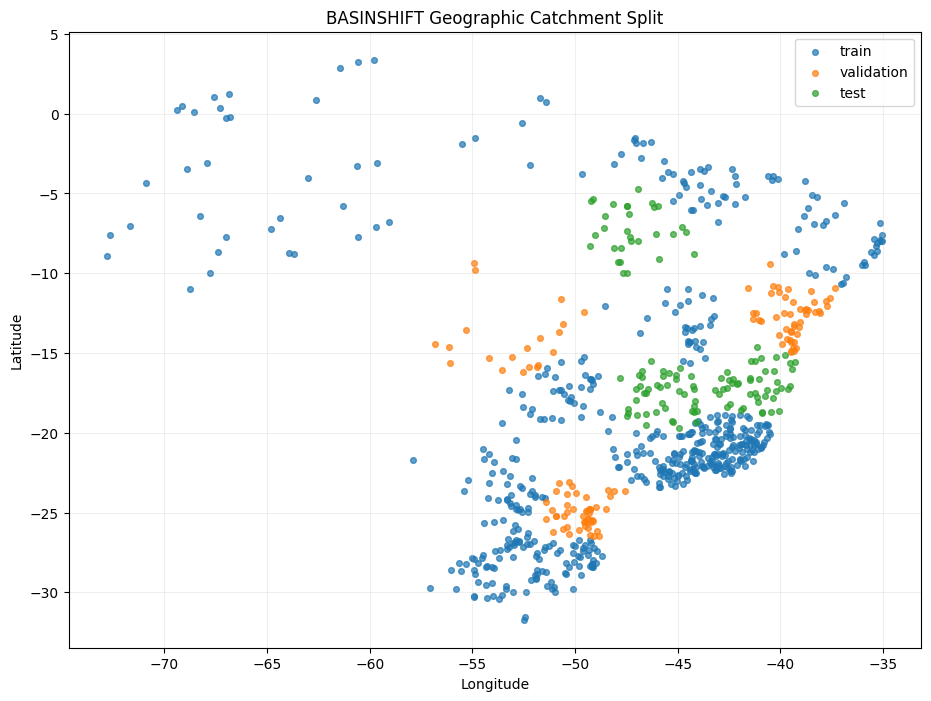


GEOGRAPHIC SPLIT COMPLETE


In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.cluster import KMeans

OUT = Path("/kaggle/working/camels_br_v12")

# ==========================================
# 1. LOAD PREVIOUSLY GENERATED ARTIFACTS
# ==========================================

manifest = pd.read_csv(
    OUT / "catchment_manifest.csv",
    dtype={"gauge_id": str}
)

static = pd.read_parquet(
    OUT / "basinshift_static_features.parquet"
)

static["gauge_id"] = static["gauge_id"].astype(str)

# Keep catchments with >=3 years continuous
eligible = manifest[
    manifest["eligible_3y"].astype(bool)
].copy()

eligible = eligible.merge(
    static[["gauge_id", "gauge_lat", "gauge_lon"]],
    on="gauge_id",
    how="left",
    validate="one_to_one"
)

if eligible[["gauge_lat", "gauge_lon"]].isna().any().any():
    raise ValueError(
        "Eligible catchments contain missing coordinates. "
        "Resolve these before geographic splitting."
    )

eligible = eligible.reset_index(drop=True)

N = len(eligible)

print("Eligible catchments:", N)
print("Five-year eligible:", eligible["eligible_5y"].sum())

# ==========================================
# 2. CREATE SPATIAL CLUSTERS
# ==========================================

N_CLUSTERS = 20

lat = eligible["gauge_lat"].to_numpy(dtype=float)
lon = eligible["gauge_lon"].to_numpy(dtype=float)

# Approximate longitude correction for latitude
mean_lat = np.deg2rad(lat.mean())

geo_features = np.column_stack([
    lat,
    lon * np.cos(mean_lat)
])

kmeans = KMeans(
    n_clusters=N_CLUSTERS,
    random_state=42,
    n_init=20
)

eligible["geo_cluster"] = kmeans.fit_predict(
    geo_features
)

cluster_sizes = (
    eligible.groupby("geo_cluster")
    .size()
    .reindex(range(N_CLUSTERS), fill_value=0)
    .to_numpy()
)

five_year_counts = (
    eligible.groupby("geo_cluster")["eligible_5y"]
    .sum()
    .reindex(range(N_CLUSTERS), fill_value=0)
    .to_numpy()
)

# ==========================================
# 3. OPTIMIZE CLUSTER ALLOCATION
# ==========================================

# 14 clusters for train, 3 for validation,
# 3 for test. Entire clusters stay together.

rng = np.random.default_rng(42)

target_counts = np.array([
    0.70 * N,
    0.15 * N,
    0.15 * N
])

total_5year = int(eligible["eligible_5y"].sum())

target_5year = np.array([
    0.70 * total_5year,
    0.15 * total_5year,
    0.15 * total_5year
])

clusters = np.arange(N_CLUSTERS)

best_score = np.inf
best_allocation = None

for _ in range(50000):

    val_clusters = rng.choice(
        clusters,
        size=3,
        replace=False
    )

    remaining = np.setdiff1d(
        clusters, val_clusters
    )

    test_clusters = rng.choice(
        remaining,
        size=3,
        replace=False
    )

    train_clusters = np.setdiff1d(
        remaining, test_clusters
    )

    allocations = [
        train_clusters,
        val_clusters,
        test_clusters
    ]

    counts = np.array([
        cluster_sizes[a].sum()
        for a in allocations
    ])

    five_counts = np.array([
        five_year_counts[a].sum()
        for a in allocations
    ])

    score = (
        np.sum(((counts - target_counts) / target_counts) ** 2)
        +
        0.5 * np.sum(
            ((five_counts - target_5year) /
             np.maximum(target_5year, 1)) ** 2
        )
    )

    if score < best_score:

        best_score = score

        best_allocation = {
            "train": train_clusters.copy(),
            "validation": val_clusters.copy(),
            "test": test_clusters.copy()
        }

# ==========================================
# 4. ASSIGN CATCHMENT PARTITIONS
# ==========================================

split_map = {}

for split_name, ids in best_allocation.items():

    for cluster_id in ids:
        split_map[int(cluster_id)] = split_name

eligible["split"] = (
    eligible["geo_cluster"].map(split_map)
)

assert eligible["split"].notna().all()

# No spatial cluster may appear in multiple splits
assert (
    eligible.groupby("geo_cluster")["split"].nunique().max()
    == 1
)

# ==========================================
# 5. VALIDATE SPLIT DISTRIBUTION
# ==========================================

summary = (
    eligible.groupby("split")
    .agg(
        catchments=("gauge_id", "count"),
        five_year_eligible=("eligible_5y", "sum"),
        median_joint_streak=("longest_joint_streak", "median"),
        median_primary_days=("primary_label_days", "median")
    )
)

summary["percentage"] = (
    summary["catchments"] / N * 100
)

print("\n========== GEOGRAPHIC SPLIT SUMMARY ==========")
display(summary)

print("\nCluster assignments:")
for name, ids in best_allocation.items():
    print(name, sorted(ids))

# ==========================================
# 6. SAVE SPLIT MANIFEST
# ==========================================

SPLIT_PATH = OUT / "spatial_split_manifest.csv"

eligible[
    [
        "gauge_id",
        "split",
        "geo_cluster",
        "gauge_lat",
        "gauge_lon",
        "longest_joint_streak",
        "eligible_5y"
    ]
].to_csv(
    SPLIT_PATH,
    index=False
)

print("\nSaved:", SPLIT_PATH)

# ==========================================
# 7. VISUALIZE GEOGRAPHIC PARTITIONS
# ==========================================

plt.figure(figsize=(11, 8))

for split_name in ["train", "validation", "test"]:

    subset = eligible[
        eligible["split"] == split_name
    ]

    plt.scatter(
        subset["gauge_lon"],
        subset["gauge_lat"],
        label=split_name,
        alpha=0.7,
        s=17
    )

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("BASINSHIFT Geographic Catchment Split")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("\nGEOGRAPHIC SPLIT COMPLETE")


In [9]:

import pandas as pd
import numpy as np
import pyarrow.parquet as pq

from pathlib import Path
from tqdm.auto import tqdm

OUT = Path("/kaggle/working/camels_br_v12")

TS_PATH = OUT / "basinshift_timeseries.parquet"

SPLIT_PATH = OUT / "spatial_split_manifest.csv"

WINDOW_SIZE = 30
HORIZONS = [1, 3, 7]

# ==========================================
# 1. LOAD MANIFESTS
# ==========================================

splits = pd.read_csv(
    SPLIT_PATH,
    dtype={"gauge_id": str}
)

split_map = dict(
    zip(splits["gauge_id"], splits["split"])
)

print("Split counts:")
print(splits["split"].value_counts())

# Verify no cluster is shared
assert (
    splits.groupby("geo_cluster")["split"]
    .nunique().max() == 1
)

# Verify unique catchment IDs
assert splits["gauge_id"].is_unique

# ==========================================
# 2. READ PARQUET ROW GROUPS
# ==========================================

pf = pq.ParquetFile(TS_PATH)

print("\nTotal parquet rows:", pf.metadata.num_rows)
print("Row groups:", pf.num_row_groups)

columns = [
    "gauge_id",
    "date",
    "target_streamflow_mm",
    "precipitation_mm",
    "temperature_c",
    "met_complete",
    "label_class"
]

records = []

# ==========================================
# 3. COUNT VALID FORECAST WINDOWS
# ==========================================

for rg in tqdm(
    range(pf.num_row_groups),
    desc="Counting forecasting sequences"
):

    df = pf.read_row_group(
        rg,
        columns=columns
    ).to_pandas()

    for gid, basin in df.groupby("gauge_id"):

        gid = str(gid)

        basin = basin.sort_values("date")

        basin = basin.set_index("date")

        if basin.empty:
            continue

        # Reindex to continuous daily calendar.
        # Missing calendar dates become invalid observations.
        full_dates = pd.date_range(
            basin.index.min(),
            basin.index.max(),
            freq="D"
        )

        basin = basin.reindex(full_dates)

        primary = (
            basin["label_class"]
            .eq(1)
            .fillna(False)
            .to_numpy()
        )

        met = (
            basin["met_complete"]
            .eq(1)
            .fillna(False)
            .to_numpy()
        )

        target = pd.to_numeric(
            basin["target_streamflow_mm"],
            errors="coerce"
        ).to_numpy()

        # Every historical input day must have:
        # primary discharge + complete meteorology
        valid_input = (
            primary
            & met
            & np.isfinite(target)
        )

        n = len(basin)

        if n <= WINDOW_SIZE + max(HORIZONS):
            count = 0

        else:

            # Prefix sum for efficient 30-day checks
            invalid = (~valid_input).astype(np.int64)

            prefix = np.concatenate([
                [0],
                np.cumsum(invalid)
            ])

            origins = np.arange(
                WINDOW_SIZE - 1,
                n - max(HORIZONS)
            )

            starts = origins - WINDOW_SIZE + 1

            history_valid = (
                prefix[origins + 1] - prefix[starts]
            ) == 0

            # All future targets must have primary labels
            target_valid = np.ones(
                len(origins),
                dtype=bool
            )

            for horizon in HORIZONS:

                target_valid &= primary[
                    origins + horizon
                ]

                target_valid &= np.isfinite(
                    target[origins + horizon]
                )

            valid_windows = (
                history_valid & target_valid
            )

            count = int(valid_windows.sum())

        records.append({

            "gauge_id": gid,

            "split": split_map.get(
                gid, "excluded"
            ),

            "valid_windows": count,

            "total_calendar_days": n

        })

# ==========================================
# 4. SUMMARIZE
# ==========================================

window_df = pd.DataFrame(records)

window_df.to_csv(
    OUT / "sequence_availability.csv",
    index=False
)

summary = (
    window_df.groupby("split")
    .agg(
        catchments=("gauge_id", "count"),
        total_windows=("valid_windows", "sum"),
        median_windows=("valid_windows", "median"),
        minimum_windows=("valid_windows", "min"),
        maximum_windows=("valid_windows", "max")
    )
)

print("\n========== SEQUENCE AVAILABILITY ==========")

display(summary)

print("\nTotal training sequences:",
      window_df.loc[
          window_df["split"] == "train",
          "valid_windows"
      ].sum())

print("\nTotal validation sequences:",
      window_df.loc[
          window_df["split"] == "validation",
          "valid_windows"
      ].sum())

print("\nTotal test sequences:",
      window_df.loc[
          window_df["split"] == "test",
          "valid_windows"
      ].sum())

print("\nCatchments with zero valid windows:")
print(
    window_df[
        (window_df["split"] != "excluded")
        & (window_df["valid_windows"] == 0)
    ].shape[0]
)

print("\nSaved:", OUT / "sequence_availability.csv")
print("SEQUENCE AUDIT COMPLETE")


Split counts:
split
train         552
validation    118
test          118
Name: count, dtype: int64

Total parquet rows: 14086438
Row groups: 897


Counting forecasting sequences:   0%|          | 0/897 [00:00<?, ?it/s]


========== SEQUENCE AVAILABILITY ==========


,catchments,total_windows,median_windows,minimum_windows,maximum_windows
split,,,,,
excluded,109,575372,5921.0,0,12850
test,118,1419295,12363.5,2454,15610
train,552,6788633,12497.5,2820,15902
validation,118,1350439,11784.0,5933,15164



Total training sequences: 6788633

Total validation sequences: 1350439

Total test sequences: 1419295

Catchments with zero valid windows:
0

Saved: /kaggle/working/camels_br_v12/sequence_availability.csv
SEQUENCE AUDIT COMPLETE


In [10]:

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from pathlib import Path
from tqdm.auto import tqdm
import gc

# =============================================
# CONFIGURATION
# =============================================

OUT = Path("/kaggle/working/camels_br_v12")

TS_PATH = OUT / "basinshift_timeseries.parquet"
STATIC_PATH = OUT / "basinshift_static_features.parquet"
SPLIT_PATH = OUT / "spatial_split_manifest.csv"
AUDIT_PATH = OUT / "sequence_availability.csv"

WINDOW = 30
HORIZONS = [1, 3, 7]
MAX_DAYS = 17000
STRIDE = 7

# =============================================
# 1. LOAD CATCHMENT MAPPING
# =============================================

static = pd.read_parquet(STATIC_PATH)

static["gauge_id"] = static["gauge_id"].astype(str)

basin_ids = sorted(static["gauge_id"].unique())

basin_map = {
    gid: idx for idx, gid in enumerate(basin_ids)
}

splits = pd.read_csv(
    SPLIT_PATH,
    dtype={"gauge_id": str}
)

split_map = dict(
    zip(splits["gauge_id"], splits["split"])
)

print("Total catchments:", len(basin_ids))

# =============================================
# 2. CREATE MEMORY-MAPPED STORAGE
# =============================================

X_PATH = OUT / "basinshift_dynamic.npy"
Y_PATH = OUT / "basinshift_targets.npy"
V_PATH = OUT / "basinshift_input_valid.npy"

B = len(basin_ids)

X = np.lib.format.open_memmap(
    X_PATH,
    mode="w+",
    dtype=np.float32,
    shape=(B, MAX_DAYS, 3)
)

Y = np.lib.format.open_memmap(
    Y_PATH,
    mode="w+",
    dtype=np.float32,
    shape=(B, MAX_DAYS)
)

V = np.lib.format.open_memmap(
    V_PATH,
    mode="w+",
    dtype=np.uint8,
    shape=(B, MAX_DAYS)
)

X[:] = np.nan
Y[:] = np.nan
V[:] = 0

# =============================================
# 3. PARQUET ROW-GROUP PROCESSING
# =============================================

pf = pq.ParquetFile(TS_PATH)

assert pf.num_row_groups == B, (
    "Expected one row group per catchment."
)

sample_chunks = {
    "train": [],
    "validation": [],
    "test": [],
    "validation_daily": [],
    "test_daily": []
}

basin_metadata = []
full_window_counts = []

columns = [
    "gauge_id",
    "date",
    "streamflow_mm_raw",
    "precipitation_mm",
    "temperature_c",
    "target_streamflow_mm",
    "met_complete",
    "label_class"
]

for rg in tqdm(
    range(pf.num_row_groups),
    desc="Building memory-mapped arrays"
):

    df = pf.read_row_group(
        rg,
        columns=columns
    ).to_pandas()

    ids = df["gauge_id"].astype(str).unique()

    if len(ids) != 1:
        raise ValueError(
            f"Multiple catchments in row group {rg}: {ids}"
        )

    gid = ids[0]
    bi = basin_map[gid]

    df["date"] = pd.to_datetime(df["date"])

    df = df.set_index("date").sort_index()

    if df.index.has_duplicates:
        raise ValueError(f"Duplicate dates for {gid}")

    dates = pd.date_range(
        df.index.min(),
        df.index.max(),
        freq="D"
    )

    n = len(dates)

    if n > MAX_DAYS:
        raise ValueError(
            f"{gid}: {n} days exceed MAX_DAYS"
        )

    df = df.reindex(dates)

    q = pd.to_numeric(
        df["streamflow_mm_raw"], errors="coerce"
    ).to_numpy(dtype=np.float32)

    p = pd.to_numeric(
        df["precipitation_mm"], errors="coerce"
    ).to_numpy(dtype=np.float32)

    t = pd.to_numeric(
        df["temperature_c"], errors="coerce"
    ).to_numpy(dtype=np.float32)

    y = pd.to_numeric(
        df["target_streamflow_mm"], errors="coerce"
    ).to_numpy(dtype=np.float32)

    primary = (
        df["label_class"].eq(1)
        .fillna(False)
        .to_numpy()
    )

    met = (
        df["met_complete"].eq(1)
        .fillna(False)
        .to_numpy()
    )

    # Same strict input policy as sequence audit
    input_valid = (
        primary
        & met
        & np.isfinite(q)
        & (q >= 0)
        & np.isfinite(p)
        & (p >= 0)
        & np.isfinite(t)
    )

    target_valid = (
        np.isfinite(y)
        & (y >= 0)
    )

    # Store raw daily features
    X[bi, :n, 0] = q
    X[bi, :n, 1] = p
    X[bi, :n, 2] = t

    Y[bi, :n] = y
    V[bi, :n] = input_valid.astype(np.uint8)

    # =========================================
    # 4. GENERATE VALID FORECAST ORIGINS
    # =========================================

    if n > WINDOW + max(HORIZONS):

        origins = np.arange(
            WINDOW - 1,
            n - max(HORIZONS),
            dtype=np.int32
        )

        # Check all 30 historical observations
        invalid = (~input_valid).astype(np.int64)

        prefix = np.concatenate([
            [0],
            np.cumsum(invalid)
        ])

        starts = origins - WINDOW + 1

        history_valid = (
            prefix[origins + 1] - prefix[starts]
        ) == 0

        # Future discharge labels
        future_valid = np.ones(
            len(origins),
            dtype=bool
        )

        for h in HORIZONS:
            future_valid &= target_valid[origins + h]

        valid_origins = origins[
            history_valid & future_valid
        ]

    else:
        valid_origins = np.array([], dtype=np.int32)

    count = len(valid_origins)

    full_window_counts.append({
        "gauge_id": gid,
        "split": split_map.get(gid, "excluded"),
        "valid_windows": count
    })

    split = split_map.get(gid)

    # -----------------------------------------
    # Select every 7th calendar day
    # -----------------------------------------

    if count and split in ["train", "validation", "test"]:

        day_numbers = (
            dates.values.astype("datetime64[D]")
            .astype(np.int64)
        )

        sampled = valid_origins[
            (day_numbers[valid_origins] % STRIDE) == 0
        ]

        if len(sampled):

            chunk = np.column_stack([
                np.full(len(sampled), bi, dtype=np.int32),
                sampled
            ]).astype(np.int32)

            sample_chunks[split].append(chunk)

    # -----------------------------------------
    # Preserve every valid validation/test day
    # for final evaluation
    # -----------------------------------------

    if count and split in ["validation", "test"]:

        dense_chunk = np.column_stack([
            np.full(count, bi, dtype=np.int32),
            valid_origins
        ]).astype(np.int32)

        sample_chunks[f"{split}_daily"].append(
            dense_chunk
        )

    basin_metadata.append({
        "basin_idx": bi,
        "gauge_id": gid,
        "start_date": str(dates.min().date()),
        "end_date": str(dates.max().date()),
        "calendar_days": n,
        "valid_windows": count
    })

# =============================================
# 5. FLUSH MEMORY-MAPPED STORAGE
# =============================================

X.flush()
Y.flush()
V.flush()

del X, Y, V
gc.collect()

# =============================================
# 6. SAVE SAMPLE INDEX ARRAYS
# =============================================

for name, chunks in sample_chunks.items():

    if chunks:
        samples = np.concatenate(chunks, axis=0)
    else:
        samples = np.empty((0, 2), dtype=np.int32)

    path = OUT / f"samples_{name}.npy"

    np.save(path, samples)

    print(
        f"{name:20s}: {len(samples):,} samples"
    )

# =============================================
# 7. SAVE METADATA
# =============================================

index_df = pd.DataFrame([
    {
        "basin_idx": i,
        "gauge_id": gid
    }
    for i, gid in enumerate(basin_ids)
])

index_df.to_csv(
    OUT / "basin_index_map.csv",
    index=False
)

pd.DataFrame(basin_metadata).to_csv(
    OUT / "basin_metadata.csv",
    index=False
)

counts_df = pd.DataFrame(full_window_counts)

counts_df.to_csv(
    OUT / "reconstructed_window_counts.csv",
    index=False
)

# =============================================
# 8. VALIDATE AGAINST PREVIOUS AUDIT
# =============================================

old_audit = pd.read_csv(
    AUDIT_PATH,
    dtype={"gauge_id": str}
)

comparison = old_audit[
    ["gauge_id", "split", "valid_windows"]
].merge(
    counts_df,
    on="gauge_id",
    suffixes=("_old", "_new"),
    validate="one_to_one"
)

comparison = comparison[
    comparison["split_old"] != "excluded"
]

print("\n========== WINDOW COUNT VALIDATION ==========")

comparison["difference"] = (
    comparison["valid_windows_old"]
    - comparison["valid_windows_new"]
)

display(
    comparison.groupby("split_old")["difference"]
    .agg(["min", "max", "mean"])
)

print(
    "Exact catchment matches:",
    int((comparison["difference"] == 0).sum()),
    "/",
    len(comparison)
)

print("\n========== STORAGE COMPLETE ==========")

for path in [
    X_PATH, Y_PATH, V_PATH
]:

    print(
        path.name,
        f"{path.stat().st_size / 1024**2:.2f} MB"
    )

print("\nMEMORY-MAPPED DATASET READY")


Total catchments: 897


Building memory-mapped arrays:   0%|          | 0/897 [00:00<?, ?it/s]

train               : 969,936 samples
validation          : 193,009 samples
test                : 202,785 samples
validation_daily    : 1,350,439 samples
test_daily          : 1,419,295 samples

========== WINDOW COUNT VALIDATION ==========


,min,max,mean
split_old,,,
test,0,0,0.0
train,0,0,0.0
validation,0,0,0.0


Exact catchment matches: 788 / 788

========== STORAGE COMPLETE ==========
basinshift_dynamic.npy 174.51 MB
basinshift_targets.npy 58.17 MB
basinshift_input_valid.npy 14.54 MB

MEMORY-MAPPED DATASET READY


In [11]:

import numpy as np
import pandas as pd
import json
from pathlib import Path
from tqdm.auto import tqdm

OUT = Path("/kaggle/working/camels_br_v12")

# Load memory-mapped arrays
X = np.load(OUT / "basinshift_dynamic.npy", mmap_mode="r")
Y = np.load(OUT / "basinshift_targets.npy", mmap_mode="r")
V = np.load(OUT / "basinshift_input_valid.npy", mmap_mode="r")

static_raw = pd.read_parquet(
    OUT / "basinshift_static_features.parquet"
)
index_map = pd.read_csv(
    OUT / "basin_index_map.csv",
    dtype={"gauge_id": str}
)
splits = pd.read_csv(
    OUT / "spatial_split_manifest.csv",
    dtype={"gauge_id": str}
)
metadata = pd.read_csv(
    OUT / "basin_metadata.csv",
    dtype={"gauge_id": str}
)

# Preserve exact array ordering
index_map = index_map.sort_values("basin_idx")

static_raw["gauge_id"] = static_raw["gauge_id"].astype(str)

static = index_map[["basin_idx", "gauge_id"]].merge(
    static_raw,
    on="gauge_id",
    validate="one_to_one"
).sort_values("basin_idx")

FEATURES = [
    "elev_gauge", "elev_mean", "slope_mean", "area",
    "sand_perc", "silt_perc", "clay_perc",
    "org_carbon_content", "bedrock_depth", "water_table_depth",
    "geol_class_1st_perc", "geol_class_2nd_perc",
    "carb_rocks_perc", "geol_porosity", "geol_permeability",
    "crop_perc", "crop_mosaic_perc", "forest_perc",
    "shrub_perc", "grass_perc", "barren_perc",
    "imperv_perc", "wet_perc", "snow_perc",
    "dom_land_cover_perc",
    "consumptive_use", "consumptive_use_perc",
    "reservoirs_vol", "regulation_degree"
]

# Map IDs to array indices
basin_index = dict(
    zip(index_map["gauge_id"], index_map["basin_idx"])
)

train_ids = splits.loc[
    splits["split"] == "train", "gauge_id"
].tolist()

train_indices = np.array(
    [basin_index[g] for g in train_ids],
    dtype=int
)

# ==========================================
# 1. DYNAMIC FEATURE SCALERS
# ==========================================

# Input transformations:
# discharge -> log1p
# precipitation -> log1p
# temperature -> unchanged

total = np.zeros(3, dtype=np.float64)
total_sq = np.zeros(3, dtype=np.float64)
count = 0

target_sum = 0.0
target_sq_sum = 0.0
target_count = 0

for bi in tqdm(train_indices, desc="Fitting training scalers"):

    valid = np.asarray(V[bi], dtype=bool)

    values = np.asarray(
        X[bi, valid, :],
        dtype=np.float64
    )

    if len(values):

        values[:, 0] = np.log1p(
            np.maximum(values[:, 0], 0)
        )

        values[:, 1] = np.log1p(
            np.maximum(values[:, 1], 0)
        )

        total += values.sum(axis=0)
        total_sq += np.square(values).sum(axis=0)
        count += len(values)

    targets = np.asarray(Y[bi], dtype=np.float64)

    targets = targets[
        np.isfinite(targets) & (targets >= 0)
    ]

    if len(targets):

        targets = np.log1p(targets)

        target_sum += targets.sum()
        target_sq_sum += np.square(targets).sum()
        target_count += len(targets)

dyn_mean = total / count

dyn_var = total_sq / count - np.square(dyn_mean)

dyn_std = np.sqrt(np.maximum(dyn_var, 1e-8))

target_mean = target_sum / target_count

target_var = (
    target_sq_sum / target_count
    - target_mean ** 2
)

target_std = np.sqrt(max(target_var, 1e-8))

# ==========================================
# 2. STATIC FEATURE SCALERS
# ==========================================

static_values = static[FEATURES].copy()

for col in FEATURES:
    static_values[col] = pd.to_numeric(
        static_values[col], errors="coerce"
    )

# Reduce skew for highly scale-dependent positive variables.
for col in ["area", "reservoirs_vol"]:

    values = static_values[col].dropna()

    if len(values) and (values >= 0).all():

        static_values[col] = np.log1p(
            static_values[col]
        )

train_static = static_values.iloc[train_indices]

# Training-only median imputation
medians = train_static.median()

# Drop features with no available training values
active_features = [
    col for col in FEATURES
    if pd.notna(medians[col])
]

static_values = static_values[active_features]

medians = medians[active_features]

train_static = train_static[active_features]

train_imputed = train_static.fillna(medians)

static_mean = train_imputed.mean()

static_std = train_imputed.std(ddof=0)

static_std = static_std.replace(
    0, 1.0
).fillna(1.0)

# Apply training-fitted preprocessing to all basins
static_imputed = static_values.fillna(medians)

static_scaled = (
    (static_imputed - static_mean) / static_std
).to_numpy(dtype=np.float32)

assert np.isfinite(static_scaled).all()
assert np.isfinite(dyn_mean).all()
assert np.isfinite(dyn_std).all()
assert np.isfinite(target_mean)
assert target_std > 0

np.save(
    OUT / "basinshift_static_scaled.npy",
    static_scaled
)

np.savez(
    OUT / "basinshift_scalers.npz",
    dyn_mean=dyn_mean,
    dyn_std=dyn_std,
    target_mean=target_mean,
    target_std=target_std,
    static_mean=static_mean.to_numpy(),
    static_std=static_std.to_numpy(),
    static_medians=medians.to_numpy()
)

with open(OUT / "feature_config.json", "w") as f:

    json.dump({
        "dynamic_features": [
            "discharge_log1p",
            "precipitation_log1p",
            "temperature"
        ],
        "static_features": active_features,
        "target_transform": "log1p",
        "window": 30,
        "horizons": [1, 3, 7]
    }, f, indent=4)

print("\n========== SCALER REPORT ==========")

print("Training catchments:", len(train_indices))
print("Dynamic features:", dyn_mean)
print("Dynamic standard deviations:", dyn_std)

print("Target mean:", target_mean)
print("Target std:", target_std)

print("Static features retained:", len(active_features))
print("Static features dropped:",
      sorted(set(FEATURES) - set(active_features)))

print("\nStatic array shape:", static_scaled.shape)
print("Finite static values:", np.isfinite(static_scaled).all())

print("\nSCALERS SAVED SUCCESSFULLY")


Fitting training scalers:   0%|          | 0/552 [00:00<?, ?it/s]


========== SCALER REPORT ==========
Training catchments: 552
Dynamic features: [ 0.80632004  1.0480738  21.0137414 ]
Dynamic standard deviations: [0.55170768 1.07088513 4.20596198]
Target mean: 0.8063200395609182
Target std: 0.5517076794077588
Static features retained: 29
Static features dropped: []

Static array shape: (897, 29)
Finite static values: True

SCALERS SAVED SUCCESSFULLY


In [12]:

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from pathlib import Path
from tqdm.auto import tqdm
import gc
import random

# ==========================================
# 1. REPRODUCIBILITY AND DEVICE
# ==========================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

OUT = Path("/kaggle/working/camels_br_v12")

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("Available GPUs:", torch.cuda.device_count())

WINDOW = 30
HORIZONS = [1, 3, 7]

BATCH_SIZE = 512
EPOCHS = 5
LEARNING_RATE = 1e-3
PATIENCE = 2
NUM_WORKERS = 2

torch.backends.cudnn.benchmark = DEVICE.type == "cuda"

# ==========================================
# 2. LOAD ARRAYS AND SCALERS
# ==========================================

X_PATH = OUT / "basinshift_dynamic.npy"
Y_PATH = OUT / "basinshift_targets.npy"

X = np.load(X_PATH, mmap_mode="r")
Y = np.load(Y_PATH, mmap_mode="r")

STATIC = np.load(
    OUT / "basinshift_static_scaled.npy"
)

scalers = np.load(
    OUT / "basinshift_scalers.npz"
)

DYN_MEAN = scalers["dyn_mean"].astype(np.float32)
DYN_STD = scalers["dyn_std"].astype(np.float32)

TARGET_MEAN = float(scalers["target_mean"])
TARGET_STD = float(scalers["target_std"])

# ==========================================
# 3. DATASET CLASS
# ==========================================

class BasinWindowDataset(Dataset):

    def __init__(self, sample_file):

        self.samples = np.load(
            OUT / sample_file,
            mmap_mode="r"
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        bi, origin = self.samples[idx]

        bi = int(bi)
        origin = int(origin)

        start = origin - WINDOW + 1

        # Historical sequence
        x = np.array(
            X[bi, start:origin + 1],
            dtype=np.float32,
            copy=True
        )

        # Transform discharge and precipitation
        x[:, 0] = np.log1p(
            np.maximum(x[:, 0], 0)
        )

        x[:, 1] = np.log1p(
            np.maximum(x[:, 1], 0)
        )

        # Training-fitted normalization
        x = (x - DYN_MEAN) / DYN_STD

        # Future discharge at +1, +3, +7 days
        y = np.array(
            [Y[bi, origin + h] for h in HORIZONS],
            dtype=np.float32
        )

        if not np.isfinite(x).all():
            raise ValueError("Non-finite input sequence")

        if not np.isfinite(y).all():
            raise ValueError("Non-finite target")

        y = np.log1p(np.maximum(y, 0))

        y = (y - TARGET_MEAN) / TARGET_STD

        s = STATIC[bi]

        return (
            torch.from_numpy(x),
            torch.from_numpy(s.copy()),
            torch.from_numpy(y)
        )

# ==========================================
# 4. DATALOADERS
# ==========================================

train_ds = BasinWindowDataset("samples_train.npy")
val_ds = BasinWindowDataset("samples_validation.npy")

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=DEVICE.type == "cuda",
    persistent_workers=NUM_WORKERS > 0,
    drop_last=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=DEVICE.type == "cuda",
    persistent_workers=NUM_WORKERS > 0
)

print("Training samples:", len(train_ds))
print("Validation samples:", len(val_ds))
print("Static dimensions:", STATIC.shape[1])

# ==========================================
# 5. MODEL ARCHITECTURE
# ==========================================

class BasinShiftLSTM(nn.Module):

    def __init__(
        self,
        dynamic_features=3,
        static_features=29,
        hidden_size=64,
        num_layers=2,
        output_size=3
    ):

        super().__init__()

        # Temporal branch
        self.lstm = nn.LSTM(
            input_size=dynamic_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.15 if num_layers > 1 else 0
        )

        # Static catchment branch
        self.static_encoder = nn.Sequential(
            nn.Linear(static_features, 64),
            nn.ReLU(),
            nn.LayerNorm(64),
            nn.Dropout(0.10),
            nn.Linear(64, 64),
            nn.ReLU()
        )

        # Fusion and prediction
        self.fusion = nn.Sequential(
            nn.Linear(hidden_size + 64, 128),
            nn.ReLU(),
            nn.Dropout(0.15),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, output_size)
        )

    def forward(self, x, static):

        _, (hidden, _) = self.lstm(x)

        temporal_features = hidden[-1]

        static_features = self.static_encoder(static)

        combined = torch.cat(
            [temporal_features, static_features],
            dim=1
        )

        return self.fusion(combined)


model = BasinShiftLSTM(
    dynamic_features=3,
    static_features=STATIC.shape[1],
    hidden_size=64,
    num_layers=2,
    output_size=3
).to(DEVICE)

print("\nModel parameters:",
      sum(p.numel() for p in model.parameters()))

# ==========================================
# 6. LOSS AND OPTIMIZER
# ==========================================

criterion = nn.SmoothL1Loss(beta=0.5)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-5
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1
)

USE_AMP = DEVICE.type == "cuda"

amp_scaler = torch.cuda.amp.GradScaler(
    enabled=USE_AMP
)

# ==========================================
# 7. VALIDATION FUNCTION
# ==========================================

def validate(model, loader):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():

        for xb, sb, yb in loader:

            xb = xb.to(DEVICE, non_blocking=True)
            sb = sb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)

            with torch.cuda.amp.autocast(
                enabled=USE_AMP
            ):

                predictions = model(xb, sb)

                loss = criterion(predictions, yb)

            size = len(xb)

            total_loss += loss.item() * size
            total_samples += size

    return total_loss / total_samples

# ==========================================
# 8. TRAINING LOOP
# ==========================================

BEST_PATH = OUT / "basinshift_lstm_best.pt"

best_val_loss = float("inf")
epochs_without_improvement = 0

history = []

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0
    seen = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    )

    for xb, sb, yb in progress:

        xb = xb.to(DEVICE, non_blocking=True)
        sb = sb.to(DEVICE, non_blocking=True)
        yb = yb.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(
            enabled=USE_AMP
        ):

            predictions = model(xb, sb)

            loss = criterion(
                predictions,
                yb
            )

        amp_scaler.scale(loss).backward()

        amp_scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        amp_scaler.step(optimizer)
        amp_scaler.update()

        batch_size = len(xb)

        running_loss += loss.item() * batch_size
        seen += batch_size

        progress.set_postfix(
            train_loss=running_loss / seen
        )

    train_loss = running_loss / seen

    val_loss = validate(
        model,
        val_loader
    )

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"\nEpoch {epoch+1}: "
        f"Train={train_loss:.6f} | "
        f"Validation={val_loss:.6f} | "
        f"LR={current_lr:.2e}"
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "validation_loss": val_loss,
        "learning_rate": current_lr
    })

    # Save best validation model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save({

            "model_state_dict": model.state_dict(),

            "dynamic_mean": DYN_MEAN,
            "dynamic_std": DYN_STD,

            "target_mean": TARGET_MEAN,
            "target_std": TARGET_STD,

            "static_features": STATIC.shape[1],

            "window": WINDOW,
            "horizons": HORIZONS,

            "best_validation_loss": best_val_loss

        }, BEST_PATH)

        epochs_without_improvement = 0

        print("Best model checkpoint saved.")

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping triggered.")
        break

# ==========================================
# 9. SAVE TRAINING HISTORY
# ==========================================

history_df = pd.DataFrame(history)

history_df.to_csv(
    OUT / "lstm_training_history.csv",
    index=False
)

print("\n========== TRAINING COMPLETE ==========")

print("Best validation loss:", best_val_loss)
print("Checkpoint:", BEST_PATH)

if DEVICE.type == "cuda":
    print(
        "Peak GPU memory:",
        round(
            torch.cuda.max_memory_allocated() / 1024**3,
            3
        ),
        "GB"
    )

gc.collect()

print("\nBASINSHIFT LSTM TRAINING FINISHED")


Device: cuda
GPU: Tesla T4
Available GPUs: 2
Training samples: 969936
Validation samples: 193009
Static dimensions: 29

Model parameters: 82115


/tmp/ipykernel_50/2962546637.py:266: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(


Epoch 1/5:   0%|          | 0/1894 [00:00<?, ?it/s]

/tmp/ipykernel_50/2962546637.py:335: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/tmp/ipykernel_50/2962546637.py:289: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(



Epoch 1: Train=0.121723 | Validation=0.097968 | LR=1.00e-03
Best model checkpoint saved.


Epoch 2/5:   0%|          | 0/1894 [00:00<?, ?it/s]


Epoch 2: Train=0.110114 | Validation=0.101563 | LR=1.00e-03


Epoch 3/5:   0%|          | 0/1894 [00:00<?, ?it/s]


Epoch 3: Train=0.108207 | Validation=0.110745 | LR=5.00e-04

Early stopping triggered.

========== TRAINING COMPLETE ==========
Best validation loss: 0.09796833567148092
Checkpoint: /kaggle/working/camels_br_v12/basinshift_lstm_best.pt
Peak GPU memory: 0.074 GB

BASINSHIFT LSTM TRAINING FINISHED


In [13]:

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from tqdm.auto import tqdm

# ==========================================
# 1. CONFIGURATION
# ==========================================

OUT = Path("/kaggle/working/camels_br_v12")

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

WINDOW = 30
HORIZONS = [1, 3, 7]
BATCH_SIZE = 512

# ==========================================
# 2. LOAD MEMORY-MAPPED DATA
# ==========================================

X = np.load(
    OUT / "basinshift_dynamic.npy",
    mmap_mode="r"
)

Y = np.load(
    OUT / "basinshift_targets.npy",
    mmap_mode="r"
)

STATIC = np.load(
    OUT / "basinshift_static_scaled.npy"
)

samples = np.load(
    OUT / "samples_validation_daily.npy",
    mmap_mode="r"
)

index_map = pd.read_csv(
    OUT / "basin_index_map.csv",
    dtype={"gauge_id": str}
)

# ==========================================
# 3. LOAD TRAINING SCALERS
# ==========================================

scalers = np.load(
    OUT / "basinshift_scalers.npz"
)

DYN_MEAN = scalers["dyn_mean"].astype(np.float32)
DYN_STD = scalers["dyn_std"].astype(np.float32)

TARGET_MEAN = float(scalers["target_mean"])
TARGET_STD = float(scalers["target_std"])

# ==========================================
# 4. RECREATE MODEL
# ==========================================

class BasinShiftLSTM(nn.Module):

    def __init__(
        self,
        dynamic_features=3,
        static_features=29,
        hidden_size=64,
        num_layers=2,
        output_size=3
    ):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=dynamic_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.15
        )

        self.static_encoder = nn.Sequential(
            nn.Linear(static_features, 64),
            nn.ReLU(),
            nn.LayerNorm(64),
            nn.Dropout(0.10),
            nn.Linear(64, 64),
            nn.ReLU()
        )

        self.fusion = nn.Sequential(
            nn.Linear(hidden_size + 64, 128),
            nn.ReLU(),
            nn.Dropout(0.15),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, output_size)
        )

    def forward(self, x, static):

        _, (hidden, _) = self.lstm(x)

        temporal = hidden[-1]

        static_features = self.static_encoder(static)

        combined = torch.cat(
            [temporal, static_features],
            dim=1
        )

        return self.fusion(combined)


# ==========================================
# 5. RESTORE BEST CHECKPOINT
# ==========================================

checkpoint = torch.load(
    OUT / "basinshift_lstm_best.pt",
    map_location=DEVICE,
    weights_only=False
)

model = BasinShiftLSTM(
    dynamic_features=3,
    static_features=STATIC.shape[1]
).to(DEVICE)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Checkpoint loaded successfully.")
print("Best validation loss:",
      checkpoint["best_validation_loss"])

# ==========================================
# 6. BATCHED INFERENCE
# ==========================================

predictions = np.empty(
    (len(samples), 3),
    dtype=np.float32
)

truth = np.empty_like(predictions)
persistence = np.empty_like(predictions)

gauge_indices = samples[:, 0].astype(np.int32)
origins = samples[:, 1].astype(np.int32)

USE_AMP = DEVICE.type == "cuda"

with torch.inference_mode():

    for start in tqdm(
        range(0, len(samples), BATCH_SIZE),
        desc="Validation inference"
    ):

        end = min(
            start + BATCH_SIZE,
            len(samples)
        )

        batch = samples[start:end]

        bi = batch[:, 0].astype(np.int64)
        origin = batch[:, 1].astype(np.int64)

        starts = origin - WINDOW + 1

        offsets = np.arange(
            WINDOW,
            dtype=np.int64
        )

        # Shape: batch x 30 x 3
        x = np.array(
            X[
                bi[:, None],
                starts[:, None] + offsets[None, :],
                :
            ],
            dtype=np.float32
        )

        x[:, :, 0] = np.log1p(
            np.maximum(x[:, :, 0], 0)
        )

        x[:, :, 1] = np.log1p(
            np.maximum(x[:, :, 1], 0)
        )

        x = (
            x - DYN_MEAN[None, None, :]
        ) / DYN_STD[None, None, :]

        s = np.asarray(
            STATIC[bi],
            dtype=np.float32
        )

        xb = torch.from_numpy(x).to(DEVICE)
        sb = torch.from_numpy(s).to(DEVICE)

        with torch.amp.autocast(
            "cuda",
            enabled=USE_AMP
        ):

            pred_norm = model(xb, sb)

        # Convert normalized log predictions
        # back to discharge in mm/day

        pred_log = (
            pred_norm.float().cpu().numpy()
            * TARGET_STD
            + TARGET_MEAN
        )

        pred_mm = np.maximum(
            np.expm1(pred_log),
            0
        )

        # Actual targets
        actual = np.column_stack([
            Y[bi, origin + h]
            for h in HORIZONS
        ])

        # Persistence: latest observed discharge
        latest = X[bi, origin, 0]

        persist = np.repeat(
            latest[:, None],
            3,
            axis=1
        )

        predictions[start:end] = pred_mm
        truth[start:end] = actual
        persistence[start:end] = persist


# ==========================================
# 7. GLOBAL METRICS
# ==========================================

def calculate_metrics(y_true, y_pred):

    error = y_pred - y_true

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))

    denominator = np.sum(
        (y_true - np.mean(y_true)) ** 2
    )

    nse = (
        1 - np.sum(error ** 2) / denominator
        if denominator > 0 else np.nan
    )

    return {
        "MAE_mm_day": mae,
        "RMSE_mm_day": rmse,
        "NSE": nse
    }


results = []

for j, horizon in enumerate(HORIZONS):

    y_true = truth[:, j]
    y_model = predictions[:, j]
    y_persist = persistence[:, j]

    model_metrics = calculate_metrics(
        y_true, y_model
    )

    persist_metrics = calculate_metrics(
        y_true, y_persist
    )

    results.append({

        "horizon": f"+{horizon} day",

        "model_MAE": model_metrics["MAE_mm_day"],
        "persistence_MAE": persist_metrics["MAE_mm_day"],

        "model_RMSE": model_metrics["RMSE_mm_day"],
        "persistence_RMSE": persist_metrics["RMSE_mm_day"],

        "model_NSE": model_metrics["NSE"],
        "persistence_NSE": persist_metrics["NSE"],

        "MAE_skill_vs_persistence": (
            1 -
            model_metrics["MAE_mm_day"] /
            persist_metrics["MAE_mm_day"]
        )
    })

global_results = pd.DataFrame(results)

print("\n========== GLOBAL VALIDATION RESULTS ==========")
display(global_results.round(5))

# ==========================================
# 8. CATCHMENT-LEVEL MACRO METRICS
# ==========================================

gauge_ids = index_map.set_index(
    "basin_idx"
)["gauge_id"].to_dict()

validation_gauges = np.array([
    gauge_ids[int(i)]
    for i in gauge_indices
])

macro_records = []

for j, horizon in enumerate(HORIZONS):

    basin_frame = pd.DataFrame({

        "gauge_id": validation_gauges,

        "actual": truth[:, j],

        "predicted": predictions[:, j],

        "persistence": persistence[:, j]

    })

    for gid, group in basin_frame.groupby("gauge_id"):

        model_m = calculate_metrics(
            group["actual"].to_numpy(),
            group["predicted"].to_numpy()
        )

        persistence_m = calculate_metrics(
            group["actual"].to_numpy(),
            group["persistence"].to_numpy()
        )

        macro_records.append({

            "horizon": f"+{horizon} day",

            "gauge_id": gid,

            "model_MAE": model_m["MAE_mm_day"],

            "persistence_MAE":
                persistence_m["MAE_mm_day"],

            "model_RMSE": model_m["RMSE_mm_day"],

            "model_NSE": model_m["NSE"],

            "persistence_NSE":
                persistence_m["NSE"]

        })

macro = pd.DataFrame(macro_records)

macro_summary = (
    macro.groupby("horizon")
    .agg(
        basins=("gauge_id", "nunique"),
        macro_MAE=("model_MAE", "mean"),
        macro_persistence_MAE=("persistence_MAE", "mean"),
        macro_RMSE=("model_RMSE", "mean"),
        macro_NSE=("model_NSE", "mean"),
        macro_persistence_NSE=("persistence_NSE", "mean")
    )
)

macro_summary["macro_MAE_skill"] = (
    1 -
    macro_summary["macro_MAE"] /
    macro_summary["macro_persistence_MAE"]
)

print("\n========== CATCHMENT MACRO RESULTS ==========")
display(macro_summary.round(5))

# ==========================================
# 9. SAVE VALIDATION RESULTS
# ==========================================

global_results.to_csv(
    OUT / "validation_global_metrics.csv",
    index=False
)

macro.to_parquet(
    OUT / "validation_catchment_metrics.parquet",
    index=False
)

# Save prediction arrays
np.savez_compressed(
    OUT / "validation_predictions.npz",
    predictions=predictions,
    truth=truth,
    persistence=persistence
)

print("\nVALIDATION COMPLETE")
print("Predictions saved in:", OUT)


Checkpoint loaded successfully.
Best validation loss: 0.09796833567148092


Validation inference:   0%|          | 0/2638 [00:00<?, ?it/s]


========== GLOBAL VALIDATION RESULTS ==========


,horizon,model_MAE,persistence_MAE,model_RMSE,persistence_RMSE,model_NSE,persistence_NSE,MAE_skill_vs_persistence
0,+1 day,0.23243,0.22030,0.89165,0.98139,0.78188,0.73577,-0.05508
1,+3 day,0.38117,0.43071,1.28910,1.51035,0.54633,0.37724,0.11503
2,+7 day,0.48910,0.59308,1.53572,1.84381,0.38253,0.10992,0.17532



========== CATCHMENT MACRO RESULTS ==========


,basins,macro_MAE,macro_persistence_MAE,macro_RMSE,macro_NSE,macro_persistence_NSE,macro_MAE_skill
horizon,,,,,,,
+1 day,118,0.23321,0.22065,0.60384,0.33420,0.74385,-0.05696
+3 day,118,0.38138,0.43034,0.92031,0.11728,0.37781,0.11375
+7 day,118,0.48894,0.59224,1.11413,0.12713,0.04565,0.17443



VALIDATION COMPLETE
Predictions saved in: /kaggle/working/camels_br_v12


In [14]:

import pandas as pd
import numpy as np
from pathlib import Path

OUT = Path("/kaggle/working/camels_br_v12")

# Load individual catchment results
df = pd.read_parquet(
    OUT / "validation_catchment_metrics.parquet"
)

# ==========================================
# 1. CALCULATE RELATIVE SKILL
# ==========================================

df["mae_skill"] = (
    1 - df["model_MAE"] / df["persistence_MAE"]
)

df["rmse_skill"] = (
    1 - df["model_RMSE"] / df["persistence_MAE"]
    if "model_RMSE" in df.columns
    else np.nan
)

# Correct RMSE skill using actual persistence RMSE
# Recalculate if the existing saved table has no persistence RMSE.
if "persistence_RMSE" in df.columns:
    df["rmse_skill"] = (
        1 - df["model_RMSE"] / df["persistence_RMSE"]
    )

df["nse_gain"] = (
    df["model_NSE"] - df["persistence_NSE"]
)

# ==========================================
# 2. CATCHMENT-WISE SKILL SUMMARY
# ==========================================

summary = []

for horizon, group in df.groupby("horizon"):

    summary.append({

        "horizon": horizon,

        "catchments": group["gauge_id"].nunique(),

        "MAE_win_pct": (
            group["mae_skill"] > 0
        ).mean() * 100,

        "RMSE_win_pct": (
            group["rmse_skill"] > 0
        ).mean() * 100,

        "NSE_win_pct": (
            group["nse_gain"] > 0
        ).mean() * 100,

        "median_MAE_skill": group["mae_skill"].median(),

        "median_RMSE_skill": group["rmse_skill"].median(),

        "median_NSE_gain": group["nse_gain"].median(),

        "valid_NSE_basins": group["nse_gain"].notna().sum()

    })

summary_df = pd.DataFrame(summary)

print("\n========== CATCHMENT WIN RATE ==========")
display(summary_df.round(4))

# ==========================================
# 3. SKILL DISTRIBUTION
# ==========================================

for horizon, group in df.groupby("horizon"):

    print(f"\n========== {horizon} ==========")

    display(
        group[
            ["mae_skill", "rmse_skill", "nse_gain"]
        ].describe(
            percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
        ).round(4)
    )

# ==========================================
# 4. WORST-PERFORMING CATCHMENTS
# ==========================================

for horizon, group in df.groupby("horizon"):

    print(f"\nWorst catchments at {horizon}:")

    display(
        group.sort_values("mae_skill")
        [
            [
                "gauge_id",
                "model_MAE",
                "persistence_MAE",
                "mae_skill",
                "model_NSE",
                "persistence_NSE"
            ]
        ]
        .head(10)
    )

# ==========================================
# 5. SAVE RESULTS
# ==========================================

df.to_parquet(
    OUT / "validation_catchment_skill_analysis.parquet",
    index=False
)

summary_df.to_csv(
    OUT / "validation_skill_summary.csv",
    index=False
)

print("\nSKILL ANALYSIS COMPLETE")



========== CATCHMENT WIN RATE ==========


,horizon,catchments,MAE_win_pct,RMSE_win_pct,NSE_win_pct,median_MAE_skill,median_RMSE_skill,median_NSE_gain,valid_NSE_basins
0,+1 day,118,33.8983,0.0,43.2203,-0.2269,-1.9115,-0.0069,118
1,+3 day,118,55.9322,0.0,75.4237,0.0396,-1.1875,0.0734,118
2,+7 day,118,72.0339,0.0,89.8305,0.1293,-0.9483,0.2859,118



========== +1 day ==========


,mae_skill,rmse_skill,nse_gain
count,118.0000,118.0000,118.0000
mean,-2.6227,-4.2380,-0.4097
std,14.3554,14.4715,4.3333
min,-154.8668,-157.5437,-47.0478
10%,-4.6580,-6.9681,-0.1228
25%,-1.5558,-3.2404,-0.0390
50%,-0.2269,-1.9115,-0.0069
75%,0.0497,-1.3868,0.0689
90%,0.1508,-1.1208,0.1502
max,0.2756,-0.7436,0.4229



========== +3 day ==========


,mae_skill,rmse_skill,nse_gain
count,118.0000,118.0000,118.0000
mean,-0.9170,-2.2832,-0.2605
std,5.5917,5.7094,4.0840
min,-59.9857,-61.5457,-44.1940
10%,-1.9602,-3.7400,-0.0667
25%,-0.3691,-1.8697,0.0064
50%,0.0396,-1.1875,0.0734
75%,0.1609,-0.9528,0.2442
90%,0.2282,-0.7411,0.3951
max,0.2956,-0.4675,0.5741


... (5 outputs left out)

,gauge_id,model_MAE,persistence_MAE,mae_skill,model_NSE,persistence_NSE
135,47480000,0.074978,0.001229,-59.985733,-43.580856,0.613170
163,51430000,0.089089,0.014286,-5.236261,-0.181926,-0.259897
145,50595000,0.095898,0.015858,-5.047274,-0.156229,0.640819
144,50540000,0.103417,0.021116,-3.897629,0.270087,0.506865
142,50430000,0.102734,0.022799,-3.505972,0.420412,0.650823
146,50620000,0.092478,0.022262,-3.154067,0.466869,0.502313
174,52570000,0.083335,0.020430,-3.079126,0.377950,0.488863
157,51170000,0.067063,0.017079,-2.926719,0.407546,0.815993
175,52680000,0.076174,0.019504,-2.905635,0.452827,0.565437
176,52695000,0.073707,0.019595,-2.761602,0.330411,0.547898



Worst catchments at +7 day:


,gauge_id,model_MAE,persistence_MAE,mae_skill,model_NSE,persistence_NSE
253,47480000,0.057754,0.002272,-24.421459,-21.313829,0.252654
281,51430000,0.071596,0.019478,-2.675680,-0.107225,-0.524018
263,50595000,0.083372,0.024974,-2.338369,-0.025030,0.272340
262,50540000,0.092242,0.033020,-1.793550,0.126107,0.075056
260,50430000,0.098202,0.039958,-1.457656,0.247525,0.214082
264,50620000,0.079606,0.034289,-1.321599,0.187325,-0.067858
282,51440000,0.086594,0.038404,-1.254812,0.036651,-0.466671
292,52570000,0.074046,0.034209,-1.164511,0.154420,-0.039175
275,51170000,0.056247,0.027583,-1.039186,0.410132,0.490947
293,52680000,0.065724,0.032294,-1.035157,0.223428,0.048293



SKILL ANALYSIS COMPLETE


In [15]:

import numpy as np
import pandas as pd
from pathlib import Path

OUT = Path("/kaggle/working/camels_br_v12")

# Load actual predictions
data = np.load(OUT / "validation_predictions.npz")

pred = data["predictions"]
truth = data["truth"]
persist = data["persistence"]

samples = np.load(
    OUT / "samples_validation_daily.npy"
)

index_map = pd.read_csv(
    OUT / "basin_index_map.csv",
    dtype={"gauge_id": str}
)

id_map = dict(
    zip(index_map["basin_idx"], index_map["gauge_id"])
)

HORIZONS = [1, 3, 7]

assert pred.shape == truth.shape == persist.shape
assert len(pred) == len(samples)

# ==========================================
# 1. CORRECT CATCHMENT METRICS
# ==========================================

records = []

for bi in np.unique(samples[:, 0]):

    mask = samples[:, 0] == bi

    gauge_id = id_map[int(bi)]

    for j, horizon in enumerate(HORIZONS):

        actual = truth[mask, j]
        model_pred = pred[mask, j]
        baseline_pred = persist[mask, j]

        model_error = model_pred - actual
        base_error = baseline_pred - actual

        model_mae = np.mean(np.abs(model_error))
        base_mae = np.mean(np.abs(base_error))

        model_rmse = np.sqrt(np.mean(model_error ** 2))
        base_rmse = np.sqrt(np.mean(base_error ** 2))

        denominator = np.sum(
            (actual - actual.mean()) ** 2
        )

        model_nse = (
            1 - np.sum(model_error ** 2) / denominator
            if denominator > 0 else np.nan
        )

        base_nse = (
            1 - np.sum(base_error ** 2) / denominator
            if denominator > 0 else np.nan
        )

        records.append({

            "gauge_id": gauge_id,

            "horizon": f"+{horizon} day",

            "samples": len(actual),

            "model_MAE": model_mae,
            "persistence_MAE": base_mae,

            "model_RMSE": model_rmse,
            "persistence_RMSE": base_rmse,

            "model_NSE": model_nse,
            "persistence_NSE": base_nse,

            "MAE_skill": (
                1 - model_mae / base_mae
                if base_mae > 0 else np.nan
            ),

            "RMSE_skill": (
                1 - model_rmse / base_rmse
                if base_rmse > 0 else np.nan
            ),

            "NSE_gain": model_nse - base_nse,

            "MAE_improvement": base_mae - model_mae,

            "target_mean": actual.mean(),
            "target_std": actual.std(),
            "target_p99": np.quantile(actual, 0.99),
            "target_max": actual.max()

        })

results = pd.DataFrame(records)

# ==========================================
# 2. CORRECT SUMMARY
# ==========================================

summary = []

for horizon, group in results.groupby("horizon"):

    summary.append({

        "horizon": horizon,

        "catchments": len(group),

        "MAE_win_pct": (
            group["MAE_improvement"] > 0
        ).mean() * 100,

        "RMSE_win_pct": (
            group["persistence_RMSE"]
            > group["model_RMSE"]
        ).mean() * 100,

        "NSE_win_pct": (
            group["NSE_gain"] > 0
        ).mean() * 100,

        "macro_model_MAE": group["model_MAE"].mean(),

        "macro_persistence_MAE": (
            group["persistence_MAE"].mean()
        ),

        "macro_model_RMSE": group["model_RMSE"].mean(),

        "macro_persistence_RMSE": (
            group["persistence_RMSE"].mean()
        ),

        "median_MAE_skill": group["MAE_skill"].median(),

        "median_RMSE_skill": group["RMSE_skill"].median(),

        "median_NSE_gain": group["NSE_gain"].median(),

        "mean_absolute_MAE_improvement": (
            group["MAE_improvement"].mean()
        ),

        "low_baseline_catchments": (
            group["persistence_MAE"] < 0.001
        ).sum()

    })

summary_df = pd.DataFrame(summary)

print("\n========== CORRECTED CATCHMENT RESULTS ==========")
display(summary_df.round(5))

# ==========================================
# 3. PERFORMANCE WITHOUT NEAR-ZERO BASELINES
# Sensitivity analysis only
# ==========================================

print("\n========== SENSITIVITY ANALYSIS ==========")

for horizon, group in results.groupby("horizon"):

    filtered = group[
        group["persistence_MAE"] >= 0.001
    ]

    print(f"\n{horizon}")
    print("Catchments retained:", len(filtered))

    print(
        "MAE win rate:",
        round(
            (filtered["MAE_skill"] > 0).mean() * 100,
            2
        ),
        "%"
    )

    print(
        "RMSE win rate:",
        round(
            (filtered["RMSE_skill"] > 0).mean() * 100,
            2
        ),
        "%"
    )

# ==========================================
# 4. INVESTIGATE EXTREME BASELINE CASE
# ==========================================

print("\n========== LOW-VARIABILITY CATCHMENTS ==========")

display(
    results[
        results["persistence_MAE"] < 0.001
    ][
        [
            "gauge_id",
            "horizon",
            "samples",
            "target_mean",
            "target_std",
            "target_p99",
            "target_max",
            "model_MAE",
            "persistence_MAE",
            "MAE_skill"
        ]
    ]
)

# ==========================================
# 5. WORST AND BEST CATCHMENTS
# ==========================================

for horizon, group in results.groupby("horizon"):

    print(f"\nBEST CATCHMENTS — {horizon}")

    display(
        group.nlargest(
            10, "MAE_improvement"
        )[
            [
                "gauge_id",
                "model_MAE",
                "persistence_MAE",
                "MAE_skill",
                "RMSE_skill"
            ]
        ]
    )

    print(f"\nWORST CATCHMENTS — {horizon}")

    display(
        group.nsmallest(
            10, "MAE_improvement"
        )[
            [
                "gauge_id",
                "model_MAE",
                "persistence_MAE",
                "MAE_skill",
                "RMSE_skill"
            ]
        ]
    )

# ==========================================
# 6. SAVE CORRECTED RESULTS
# ==========================================

results.to_parquet(
    OUT / "validation_metrics_corrected.parquet",
    index=False
)

summary_df.to_csv(
    OUT / "validation_summary_corrected.csv",
    index=False
)

print("\nCORRECTED EVALUATION COMPLETE")



========== CORRECTED CATCHMENT RESULTS ==========


,horizon,catchments,MAE_win_pct,RMSE_win_pct,NSE_win_pct,macro_model_MAE,macro_persistence_MAE,macro_model_RMSE,macro_persistence_RMSE,median_MAE_skill,median_RMSE_skill,median_NSE_gain,mean_absolute_MAE_improvement,low_baseline_catchments
0,+1 day,118,33.89831,43.22034,43.22034,0.23321,0.22065,0.60384,0.62952,-0.22692,-0.04414,-0.00694,-0.01257,1
1,+3 day,118,55.93220,75.42373,75.42373,0.38138,0.43034,0.92031,1.04247,0.03964,0.08071,0.07340,0.04895,0
2,+7 day,118,72.03390,89.83051,89.83051,0.48894,0.59224,1.11413,1.31748,0.12934,0.14716,0.28593,0.10330,0



========== SENSITIVITY ANALYSIS ==========

+1 day
Catchments retained: 117
MAE win rate: 34.19 %
RMSE win rate: 43.59 %

+3 day
Catchments retained: 118
MAE win rate: 55.93 %
RMSE win rate: 75.42 %

+7 day
Catchments retained: 118
MAE win rate: 72.03 %
RMSE win rate: 89.83 %

========== LOW-VARIABILITY CATCHMENTS ==========


,gauge_id,horizon,samples,target_mean,target_std,target_p99,target_max,model_MAE,persistence_MAE,MAE_skill
51,47480000,+1 day,10147,0.006418,0.0115,0.052172,0.229843,0.077622,0.000498,-154.866776



BEST CATCHMENTS — +1 day


,gauge_id,model_MAE,persistence_MAE,MAE_skill,RMSE_skill
342,82270050,1.339364,1.716496,0.219710,0.142669
348,82350000,1.045328,1.339862,0.219824,0.118555
345,82320000,0.844327,1.047345,0.193840,0.089670
303,65809000,0.719171,0.908694,0.208567,0.114007
252,64625000,0.494220,0.654436,0.244816,0.101123
255,64645000,0.380506,0.525257,0.275581,0.182831
249,64620000,0.472036,0.604328,0.218907,0.090000
246,64619950,0.483182,0.596002,0.189295,0.059828
351,82770000,1.091982,1.193639,0.085165,-0.107518
216,64360000,0.296248,0.359442,0.175814,0.130933


... (7 outputs left out)

,gauge_id,model_MAE,persistence_MAE,MAE_skill,RMSE_skill
353,82770000,2.792744,3.683045,0.241730,0.176336
344,82270050,2.142464,2.949476,0.273612,0.137206
350,82350000,1.711709,2.438536,0.298059,0.218743
347,82320000,1.555890,2.168047,0.282354,0.179937
254,64625000,1.252894,1.763646,0.289600,0.200221
305,65809000,1.352701,1.862378,0.273670,0.209469
251,64620000,1.316724,1.797051,0.267287,0.177271
248,64619950,1.333205,1.810801,0.263748,0.169088
257,64645000,1.109120,1.535793,0.277819,0.176933
260,65009000,1.284312,1.587146,0.190804,0.112084



WORST CATCHMENTS — +7 day


,gauge_id,model_MAE,persistence_MAE,MAE_skill,RMSE_skill
80,50540000,0.092242,0.033020,-1.793550,0.027988
83,50595000,0.083372,0.024974,-2.338369,-0.186873
74,50430000,0.098202,0.039958,-1.457656,0.021508
71,50420000,0.133115,0.076676,-0.736066,0.165065
53,47480000,0.057754,0.002272,-24.421459,-4.464196
143,51460000,0.112017,0.059359,-0.887106,0.161482
137,51430000,0.071596,0.019478,-2.675680,0.147640
140,51440000,0.086594,0.038404,-1.254812,0.189552
86,50620000,0.079606,0.034289,-1.321599,0.127628
77,50465000,0.099765,0.055436,-0.799637,0.071007



CORRECTED EVALUATION COMPLETE


In [16]:

import numpy as np
import pandas as pd
from pathlib import Path

OUT = Path("/kaggle/working/camels_br_v12")

data = np.load(OUT / "validation_predictions.npz")

pred = data["predictions"]
truth = data["truth"]
persist = data["persistence"]

samples = np.load(
    OUT / "samples_validation_daily.npy"
)

index_map = pd.read_csv(
    OUT / "basin_index_map.csv",
    dtype={"gauge_id": str}
)

static = pd.read_parquet(
    OUT / "basinshift_static_features.parquet"
)

splits = pd.read_csv(
    OUT / "spatial_split_manifest.csv",
    dtype={"gauge_id": str}
)

id_map = dict(zip(
    index_map["basin_idx"],
    index_map["gauge_id"]
))

HORIZONS = [1, 3, 7]

# ==========================================
# 1. CATCHMENT DIAGNOSTICS
# ==========================================

records = []

for bi in np.unique(samples[:, 0]):

    mask = samples[:, 0] == bi

    gid = id_map[int(bi)]

    for j, horizon in enumerate(HORIZONS):

        actual = truth[mask, j]
        predicted = pred[mask, j]
        baseline = persist[mask, j]

        model_error = predicted - actual
        base_error = baseline - actual

        model_mae = np.mean(np.abs(model_error))
        base_mae = np.mean(np.abs(base_error))

        model_rmse = np.sqrt(np.mean(model_error**2))
        base_rmse = np.sqrt(np.mean(base_error**2))

        records.append({

            "gauge_id": gid,
            "horizon": horizon,
            "samples": len(actual),

            "actual_mean": actual.mean(),
            "actual_median": np.median(actual),
            "actual_std": actual.std(),
            "actual_p99": np.quantile(actual, 0.99),
            "actual_max": actual.max(),

            "actual_zero_pct": (
                actual == 0
            ).mean() * 100,

            "prediction_mean": predicted.mean(),

            "prediction_bias": model_error.mean(),

            "persistence_bias": base_error.mean(),

            "model_MAE": model_mae,
            "persistence_MAE": base_mae,

            "MAE_improvement": base_mae - model_mae,

            "model_RMSE": model_rmse,
            "persistence_RMSE": base_rmse,

            "RMSE_improvement": base_rmse - model_rmse

        })

diagnostics = pd.DataFrame(records)

# ==========================================
# 2. ADD CATCHMENT CHARACTERISTICS
# ==========================================

static["gauge_id"] = static["gauge_id"].astype(str)
splits["gauge_id"] = splits["gauge_id"].astype(str)

metadata_columns = [
    "gauge_id",
    "gauge_lat",
    "gauge_lon",
    "area",
    "elev_mean",
    "slope_mean",
    "regulation_degree",
    "reservoirs_vol",
    "forest_perc",
    "imperv_perc"
]

basin_metadata = static[
    [c for c in metadata_columns if c in static.columns]
]

cluster_metadata = splits[
    ["gauge_id", "geo_cluster"]
]

diagnostics = diagnostics.merge(
    basin_metadata,
    on="gauge_id",
    how="left"
)

diagnostics = diagnostics.merge(
    cluster_metadata,
    on="gauge_id",
    how="left"
)

# ==========================================
# 3. WORST CATCHMENTS
# ==========================================

for horizon in HORIZONS:

    subset = diagnostics[
        diagnostics["horizon"] == horizon
    ]

    print(f"\n========== WORST AT +{horizon} DAY ==========")

    display(
        subset.sort_values("MAE_improvement")
        .head(10)
    )

# ==========================================
# 4. EXAMINE THE LOW-FLOW BASIN
# ==========================================

print("\n========== LOW-FLOW CATCHMENT ==========")

display(
    diagnostics[
        diagnostics["gauge_id"] == "47480000"
    ]
)

# ==========================================
# 5. REGIONAL CLUSTER COMPARISON
# ==========================================

print("\n========== CLUSTER PERFORMANCE ==========")

cluster_summary = (
    diagnostics.groupby(
        ["horizon", "geo_cluster"]
    )
    .agg(
        catchments=("gauge_id", "nunique"),
        mean_MAE_improvement=("MAE_improvement", "mean"),
        mean_model_bias=("prediction_bias", "mean"),
        mean_actual_flow=("actual_mean", "mean")
    )
    .reset_index()
)

display(
    cluster_summary.sort_values(
        ["horizon", "mean_MAE_improvement"]
    ).head(20)
)

# ==========================================
# 6. SAVE
# ==========================================

diagnostics.to_parquet(
    OUT / "validation_basin_diagnostics.parquet",
    index=False
)

cluster_summary.to_csv(
    OUT / "validation_cluster_diagnostics.csv",
    index=False
)

print("\nDIAGNOSTICS SAVED")



========== WORST AT +1 DAY ==========


,gauge_id,horizon,samples,actual_mean,actual_median,actual_std,actual_p99,actual_max,actual_zero_pct,prediction_mean,...,gauge_lat,gauge_lon,area,elev_mean,slope_mean,regulation_degree,reservoirs_vol,forest_perc,imperv_perc,geo_cluster
78,50540000,1,12058,0.043623,0.012933,0.155049,0.665439,3.368720,0.000000,0.139909,...,-11.097500,-38.512501,27982.179688,423.438995,30.313299,76.059601,332.0,7.829200,0.0000,7
81,50595000,1,10394,0.045393,0.019495,0.094564,0.415529,1.789598,0.000000,0.141272,...,-11.734700,-37.803299,35133.488281,392.740204,29.598700,49.543201,332.0,7.635400,0.0000,7
282,65060000,1,11414,1.759887,1.298905,1.405843,6.212426,16.539333,0.000000,1.706143,...,-25.875799,-50.389702,5996.266113,894.952881,28.409901,3.516900,149.0,52.148102,2.7322,12
141,51460000,1,10315,0.051582,0.002568,0.439490,1.203430,16.047380,4.488609,0.138430,...,-12.233100,-39.046101,11566.030273,432.648804,25.023001,112.072800,268.0,9.500400,0.0000,7
72,50430000,1,7520,0.075421,0.028378,0.166361,0.749087,2.882628,0.159574,0.165843,...,-11.182200,-40.046700,2313.331055,589.781677,54.674999,63.821400,46.0,14.877900,0.0000,7
138,51440000,1,13003,0.028491,0.001649,0.239684,0.404728,8.076418,6.167807,0.114988,...,-11.807200,-39.386398,7131.012207,539.675415,27.408800,238.843094,267.0,13.350600,0.0000,7
75,50465000,1,9230,0.074951,0.027751,0.197912,0.972897,3.434468,2.145179,0.164504,...,-10.973300,-39.632801,11834.959961,509.371613,36.890499,19.830999,73.0,13.095000,0.0000,7
84,50620000,1,13909,0.059864,0.034368,0.237033,0.448313,7.135020,0.000000,0.145443,...,-11.782200,-38.346699,2896.081055,287.834015,24.082899,0.000000,0.0,5.505600,0.0000,7
135,51430000,1,11001,0.012389,0.001498,0.128548,0.161993,6.623527,12.571584,0.099025,...,-11.470000,-39.788300,5040.750977,639.523010,33.833801,718.199829,262.0,14.412600,0.0000,7
69,50420000,1,12106,0.098855,0.036043,0.307771,1.052391,12.181035,0.000000,0.184435,...,-11.211400,-40.470299,1304.515015,664.466675,62.585602,0.000000,0.0,16.058399,0.0000,7



========== WORST AT +3 DAY ==========


,gauge_id,horizon,samples,actual_mean,actual_median,actual_std,actual_p99,actual_max,actual_zero_pct,prediction_mean,...,gauge_lat,gauge_lon,area,elev_mean,slope_mean,regulation_degree,reservoirs_vol,forest_perc,imperv_perc,geo_cluster
283,65060000,3,11414,1.759179,1.298905,1.405031,6.212426,16.539333,0.000000,1.619244,...,-25.875799,-50.389702,5996.266113,894.952881,28.409901,3.516900,149.0,52.148102,2.7322,12
79,50540000,3,12058,0.043656,0.012933,0.155047,0.665439,3.368720,0.000000,0.131320,...,-11.097500,-38.512501,27982.179688,423.438995,30.313299,76.059601,332.0,7.829200,0.0000,7
82,50595000,3,10394,0.045797,0.019495,0.096549,0.432418,1.789598,0.000000,0.133447,...,-11.734700,-37.803299,35133.488281,392.740204,29.598700,49.543201,332.0,7.635400,0.0000,7
73,50430000,3,7520,0.074665,0.027929,0.165759,0.749087,2.882628,0.226064,0.162394,...,-11.182200,-40.046700,2313.331055,589.781677,54.674999,63.821400,46.0,14.877900,0.0000,7
70,50420000,3,12106,0.098949,0.036043,0.309025,1.053074,12.181035,0.000000,0.186317,...,-11.211400,-40.470299,1304.515015,664.466675,62.585602,0.000000,0.0,16.058399,0.0000,7
136,51430000,3,11001,0.012933,0.001498,0.137806,0.175354,6.623527,12.617035,0.090230,...,-11.470000,-39.788300,5040.750977,639.523010,33.833801,718.199829,262.0,14.412600,0.0000,7
52,47480000,3,10147,0.006423,0.003611,0.011517,0.052510,0.229843,0.000000,0.081384,...,-10.901700,-41.570301,9270.727539,871.958130,30.500200,4.124900,1.0,10.132000,0.0000,7
139,51440000,3,13003,0.028942,0.001649,0.241074,0.429510,8.076418,6.183188,0.102677,...,-11.807200,-39.386398,7131.012207,539.675415,27.408800,238.843094,267.0,13.350600,0.0000,7
142,51460000,3,10315,0.051966,0.002564,0.440194,1.223859,16.047380,4.672807,0.123672,...,-12.233100,-39.046101,11566.030273,432.648804,25.023001,112.072800,268.0,9.500400,0.0000,7
85,50620000,3,13909,0.060006,0.034368,0.237371,0.454357,7.135020,0.000000,0.131895,...,-11.782200,-38.346699,2896.081055,287.834015,24.082899,0.000000,0.0,5.505600,0.0000,7



========== WORST AT +7 DAY ==========


,gauge_id,horizon,samples,actual_mean,actual_median,actual_std,actual_p99,actual_max,actual_zero_pct,prediction_mean,...,gauge_lat,gauge_lon,area,elev_mean,slope_mean,regulation_degree,reservoirs_vol,forest_perc,imperv_perc,geo_cluster
80,50540000,7,12058,0.043560,0.012938,0.154404,0.636302,3.368720,0.000000,0.112354,...,-11.0975,-38.512501,27982.179688,423.438995,30.313299,76.059601,332.0,7.829200,0.0,7
83,50595000,7,10394,0.047225,0.019495,0.102724,0.461979,1.792859,0.000000,0.115778,...,-11.7347,-37.803299,35133.488281,392.740204,29.598700,49.543201,332.0,7.635400,0.0,7
74,50430000,7,7520,0.073730,0.027253,0.165169,0.749087,2.882628,0.265957,0.145762,...,-11.1822,-40.046700,2313.331055,589.781677,54.674999,63.821400,46.0,14.877900,0.0,7
71,50420000,7,12106,0.099628,0.036043,0.311308,1.093232,12.181035,0.000000,0.177517,...,-11.2114,-40.470299,1304.515015,664.466675,62.585602,0.000000,0.0,16.058399,0.0,7
53,47480000,7,10147,0.006515,0.003611,0.012811,0.053584,0.412497,0.000000,0.064153,...,-10.9017,-41.570301,9270.727539,871.958130,30.500200,4.124900,1.0,10.132000,0.0,7
143,51460000,7,10315,0.050214,0.002387,0.432880,1.192057,16.047380,5.167232,0.101467,...,-12.2331,-39.046101,11566.030273,432.648804,25.023001,112.072800,268.0,9.500400,0.0,7
137,51430000,7,11001,0.014407,0.001498,0.153875,0.194179,6.623527,12.707936,0.068847,...,-11.4700,-39.788300,5040.750977,639.523010,33.833801,718.199829,262.0,14.412600,0.0,7
140,51440000,7,13003,0.030870,0.001649,0.257885,0.470600,8.379308,6.190879,0.080522,...,-11.8072,-39.386398,7131.012207,539.675415,27.408800,238.843094,267.0,13.350600,0.0,7
86,50620000,7,13909,0.059881,0.034368,0.236570,0.452621,7.135020,0.000000,0.109863,...,-11.7822,-38.346699,2896.081055,287.834015,24.082899,0.000000,0.0,5.505600,0.0,7
77,50465000,7,9230,0.076684,0.027054,0.204316,1.052393,3.434468,2.296858,0.133690,...,-10.9733,-39.632801,11834.959961,509.371613,36.890499,19.830999,73.0,13.095000,0.0,7



========== LOW-FLOW CATCHMENT ==========


,gauge_id,horizon,samples,actual_mean,actual_median,actual_std,actual_p99,actual_max,actual_zero_pct,prediction_mean,...,gauge_lat,gauge_lon,area,elev_mean,slope_mean,regulation_degree,reservoirs_vol,forest_perc,imperv_perc,geo_cluster
51,47480000,1,10147,0.006418,0.003611,0.011500,0.052172,0.229843,0.0,0.084029,...,-10.9017,-41.570301,9270.727539,871.95813,30.5002,4.1249,1.0,10.132,0.0,7
52,47480000,3,10147,0.006423,0.003611,0.011517,0.052510,0.229843,0.0,0.081384,...,-10.9017,-41.570301,9270.727539,871.95813,30.5002,4.1249,1.0,10.132,0.0,7
53,47480000,7,10147,0.006515,0.003611,0.012811,0.053584,0.412497,0.0,0.064153,...,-10.9017,-41.570301,9270.727539,871.95813,30.5002,4.1249,1.0,10.132,0.0,7



========== CLUSTER PERFORMANCE ==========


,horizon,geo_cluster,catchments,mean_MAE_improvement,mean_model_bias,mean_actual_flow
1,1,7,50,-0.057505,0.044544,0.329473
0,1,5,20,-0.022876,-0.052585,1.688487
2,1,12,48,0.038535,-0.146453,1.868104
4,3,7,50,-0.028045,0.017872,0.330473
3,3,5,20,0.021998,-0.115436,1.688613
5,3,12,48,0.140389,-0.311718,1.870113
7,7,7,50,0.005972,-0.005167,0.331761
6,7,5,20,0.059457,-0.175401,1.689117
8,7,12,48,0.222959,-0.432281,1.876185



DIAGNOSTICS SAVED


In [17]:

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from pathlib import Path
from tqdm.auto import tqdm
import random
import gc

# ==========================================
# 1. CONFIGURATION
# ==========================================

SEED = 42
OUT = Path("/kaggle/working/camels_br_v12")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

WINDOW = 30
HORIZONS = [1, 3, 7]

BATCH_SIZE = 512
EPOCHS = 8
LEARNING_RATE = 5e-4
PATIENCE = 3
NUM_WORKERS = 2

USE_AMP = DEVICE.type == "cuda"

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# ==========================================
# 2. LOAD DATA
# ==========================================

X = np.load(
    OUT / "basinshift_dynamic.npy",
    mmap_mode="r"
)

Y = np.load(
    OUT / "basinshift_targets.npy",
    mmap_mode="r"
)

STATIC = np.load(
    OUT / "basinshift_static_scaled.npy"
)

scalers = np.load(
    OUT / "basinshift_scalers.npz"
)

DYN_MEAN = scalers["dyn_mean"].astype(np.float32)
DYN_STD = scalers["dyn_std"].astype(np.float32)

TARGET_STD = float(scalers["target_std"])

# ==========================================
# 3. RESIDUAL DATASET
# ==========================================

class ResidualBasinDataset(Dataset):

    def __init__(self, sample_file):

        self.samples = np.load(
            OUT / sample_file,
            mmap_mode="r"
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        bi, origin = self.samples[idx]

        bi = int(bi)
        origin = int(origin)

        start = origin - WINDOW + 1

        x = np.array(
            X[bi, start:origin + 1],
            dtype=np.float32,
            copy=True
        )

        # Transform discharge and precipitation
        x[:, 0] = np.log1p(
            np.maximum(x[:, 0], 0)
        )

        x[:, 1] = np.log1p(
            np.maximum(x[:, 1], 0)
        )

        x = (
            x - DYN_MEAN
        ) / DYN_STD

        # Latest observed discharge in log space
        latest_q = float(X[bi, origin, 0])

        latest_z = np.log1p(
            max(latest_q, 0)
        )

        # Future discharge
        future_q = np.array(
            [Y[bi, origin + h] for h in HORIZONS],
            dtype=np.float32
        )

        future_z = np.log1p(
            np.maximum(future_q, 0)
        )

        # Residual targets:
        # future log discharge - latest log discharge
        delta = (
            future_z - latest_z
        ) / TARGET_STD

        return (
            torch.from_numpy(x),
            torch.from_numpy(STATIC[bi].copy()),
            torch.from_numpy(delta.astype(np.float32))
        )

# ==========================================
# 4. DATA LOADERS
# ==========================================

train_ds = ResidualBasinDataset(
    "samples_train.npy"
)

val_ds = ResidualBasinDataset(
    "samples_validation.npy"
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=USE_AMP,
    persistent_workers=NUM_WORKERS > 0,
    drop_last=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=USE_AMP,
    persistent_workers=NUM_WORKERS > 0
)

print("Training samples:", len(train_ds))
print("Validation samples:", len(val_ds))

# ==========================================
# 5. RESIDUAL LSTM ARCHITECTURE
# ==========================================

class ResidualBasinShiftLSTM(nn.Module):

    def __init__(
        self,
        dynamic_features=3,
        static_features=29,
        hidden_size=64,
        num_layers=2
    ):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=dynamic_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.15
        )

        self.static_encoder = nn.Sequential(
            nn.Linear(static_features, 64),
            nn.ReLU(),
            nn.LayerNorm(64),
            nn.Dropout(0.10),
            nn.Linear(64, 64),
            nn.ReLU()
        )

        self.fusion = nn.Sequential(
            nn.Linear(hidden_size + 64, 128),
            nn.ReLU(),
            nn.Dropout(0.15),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 3)
        )

        # Start exactly at persistence:
        # all predicted residuals = 0
        final_layer = self.fusion[-1]

        nn.init.zeros_(final_layer.weight)
        nn.init.zeros_(final_layer.bias)

    def forward(self, x, static):

        _, (hidden, _) = self.lstm(x)

        temporal = hidden[-1]

        static_features = self.static_encoder(static)

        combined = torch.cat(
            [temporal, static_features],
            dim=1
        )

        return self.fusion(combined)


model = ResidualBasinShiftLSTM(
    dynamic_features=3,
    static_features=STATIC.shape[1]
).to(DEVICE)

print(
    "Parameters:",
    sum(p.numel() for p in model.parameters())
)

# Verify exact persistence initialization
with torch.no_grad():

    test_output = model(
        torch.zeros(2, WINDOW, 3, device=DEVICE),
        torch.zeros(2, STATIC.shape[1], device=DEVICE)
    )

    assert torch.allclose(
        test_output,
        torch.zeros_like(test_output)
    )

print("Zero-residual initialization verified.")

# ==========================================
# 6. LOSS AND OPTIMIZER
# ==========================================

criterion = nn.SmoothL1Loss(beta=0.5)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1
)

amp_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

# ==========================================
# 7. VALIDATION
# ==========================================

def validate(model, loader):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    with torch.inference_mode():

        for xb, sb, yb in loader:

            xb = xb.to(DEVICE, non_blocking=True)
            sb = sb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)

            with torch.amp.autocast(
                device_type=DEVICE.type,
                enabled=USE_AMP
            ):

                output = model(xb, sb)

                loss = criterion(output, yb)

            total_loss += loss.item() * len(xb)
            total_samples += len(xb)

    return total_loss / total_samples

# ==========================================
# 8. TRAINING LOOP
# ==========================================

BEST_PATH = OUT / "basinshift_residual_lstm_best.pt"

best_loss = float("inf")
wait = 0
history = []

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0
    total = 0

    progress = tqdm(
        train_loader,
        desc=f"Residual Epoch {epoch+1}/{EPOCHS}"
    )

    for xb, sb, yb in progress:

        xb = xb.to(DEVICE, non_blocking=True)
        sb = sb.to(DEVICE, non_blocking=True)
        yb = yb.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP
        ):

            output = model(xb, sb)

            loss = criterion(output, yb)

        amp_scaler.scale(loss).backward()

        amp_scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        amp_scaler.step(optimizer)
        amp_scaler.update()

        running_loss += loss.item() * len(xb)
        total += len(xb)

        progress.set_postfix(
            loss=running_loss / total
        )

    train_loss = running_loss / total

    val_loss = validate(
        model,
        val_loader
    )

    scheduler.step(val_loss)

    lr = optimizer.param_groups[0]["lr"]

    print(
        f"\nEpoch {epoch+1}: "
        f"Train={train_loss:.6f} | "
        f"Validation={val_loss:.6f} | "
        f"LR={lr:.2e}"
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "validation_loss": val_loss,
        "learning_rate": lr
    })

    if val_loss < best_loss:

        best_loss = val_loss

        torch.save({

            "model_state_dict": model.state_dict(),

            "dynamic_mean": DYN_MEAN,
            "dynamic_std": DYN_STD,

            "target_std": TARGET_STD,

            "static_features": STATIC.shape[1],

            "window": WINDOW,
            "horizons": HORIZONS,

            "best_validation_loss": best_loss

        }, BEST_PATH)

        wait = 0

        print("Best residual checkpoint saved.")

    else:

        wait += 1

    if wait >= PATIENCE:

        print("Early stopping.")
        break

# ==========================================
# 9. SAVE HISTORY
# ==========================================

pd.DataFrame(history).to_csv(
    OUT / "residual_lstm_history.csv",
    index=False
)

print("\n========== RESIDUAL TRAINING COMPLETE ==========")

print("Best validation loss:", best_loss)
print("Checkpoint:", BEST_PATH)

if DEVICE.type == "cuda":
    print(
        "Peak GPU memory:",
        round(
            torch.cuda.max_memory_allocated() / 1024**3,
            3
        ),
        "GB"
    )

gc.collect()


Device: cuda
GPU: Tesla T4
Training samples: 969936
Validation samples: 193009
Parameters: 82115
Zero-residual initialization verified.


Residual Epoch 1/8:   0%|          | 0/1894 [00:00<?, ?it/s]


Epoch 1: Train=0.113758 | Validation=0.092081 | LR=5.00e-04
Best residual checkpoint saved.


Residual Epoch 2/8:   0%|          | 0/1894 [00:00<?, ?it/s]


Epoch 2: Train=0.107811 | Validation=0.091909 | LR=5.00e-04
Best residual checkpoint saved.


Residual Epoch 3/8:   0%|          | 0/1894 [00:00<?, ?it/s]

... (9 outputs left out)


Epoch 7: Train=0.104369 | Validation=0.090674 | LR=5.00e-04


Residual Epoch 8/8:   0%|          | 0/1894 [00:00<?, ?it/s]


Epoch 8: Train=0.103892 | Validation=0.090242 | LR=5.00e-04
Best residual checkpoint saved.

========== RESIDUAL TRAINING COMPLETE ==========
Best validation loss: 0.09024243038721799
Checkpoint: /kaggle/working/camels_br_v12/basinshift_residual_lstm_best.pt
Peak GPU memory: 0.074 GB


316

In [18]:

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from tqdm.auto import tqdm

OUT = Path("/kaggle/working/camels_br_v12")

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

WINDOW = 30
HORIZONS = [1, 3, 7]
BATCH_SIZE = 512

# ==========================================
# 1. LOAD ORIGINAL VALIDATION RESULTS
# ==========================================

original = np.load(
    OUT / "validation_predictions.npz"
)

direct_pred = original["predictions"]
truth = original["truth"]
persistence = original["persistence"]

samples = np.load(
    OUT / "samples_validation_daily.npy",
    mmap_mode="r"
)

assert len(samples) == len(truth)

# ==========================================
# 2. LOAD MEMORY-MAPPED DATA
# ==========================================

X = np.load(
    OUT / "basinshift_dynamic.npy",
    mmap_mode="r"
)

Y = np.load(
    OUT / "basinshift_targets.npy",
    mmap_mode="r"
)

STATIC = np.load(
    OUT / "basinshift_static_scaled.npy"
)

scalers = np.load(
    OUT / "basinshift_scalers.npz"
)

DYN_MEAN = scalers["dyn_mean"].astype(np.float32)
DYN_STD = scalers["dyn_std"].astype(np.float32)

TARGET_STD = float(scalers["target_std"])

# ==========================================
# 3. RECREATE RESIDUAL MODEL
# ==========================================

class ResidualBasinShiftLSTM(nn.Module):

    def __init__(
        self,
        dynamic_features=3,
        static_features=29,
        hidden_size=64,
        num_layers=2
    ):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=dynamic_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.15
        )

        self.static_encoder = nn.Sequential(
            nn.Linear(static_features, 64),
            nn.ReLU(),
            nn.LayerNorm(64),
            nn.Dropout(0.10),
            nn.Linear(64, 64),
            nn.ReLU()
        )

        self.fusion = nn.Sequential(
            nn.Linear(hidden_size + 64, 128),
            nn.ReLU(),
            nn.Dropout(0.15),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 3)
        )

    def forward(self, x, static):

        _, (hidden, _) = self.lstm(x)

        temporal = hidden[-1]

        static_features = self.static_encoder(static)

        combined = torch.cat(
            [temporal, static_features],
            dim=1
        )

        return self.fusion(combined)


# ==========================================
# 4. LOAD BEST CHECKPOINT
# ==========================================

checkpoint = torch.load(
    OUT / "basinshift_residual_lstm_best.pt",
    map_location=DEVICE,
    weights_only=False
)

model = ResidualBasinShiftLSTM(
    dynamic_features=3,
    static_features=STATIC.shape[1]
).to(DEVICE)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Residual checkpoint loaded.")
print("Best validation loss:",
      checkpoint["best_validation_loss"])

# ==========================================
# 5. DAILY VALIDATION INFERENCE
# ==========================================

residual_pred = np.empty(
    (len(samples), 3),
    dtype=np.float32
)

USE_AMP = DEVICE.type == "cuda"

with torch.inference_mode():

    for start in tqdm(
        range(0, len(samples), BATCH_SIZE),
        desc="Residual validation inference"
    ):

        end = min(
            start + BATCH_SIZE,
            len(samples)
        )

        batch = samples[start:end]

        bi = batch[:, 0].astype(np.int64)
        origin = batch[:, 1].astype(np.int64)

        starts = origin - WINDOW + 1

        offsets = np.arange(WINDOW)

        x = np.array(
            X[
                bi[:, None],
                starts[:, None] + offsets[None, :],
                :
            ],
            dtype=np.float32
        )

        x[:, :, 0] = np.log1p(
            np.maximum(x[:, :, 0], 0)
        )

        x[:, :, 1] = np.log1p(
            np.maximum(x[:, :, 1], 0)
        )

        x = (
            x - DYN_MEAN[None, None, :]
        ) / DYN_STD[None, None, :]

        s = np.asarray(
            STATIC[bi],
            dtype=np.float32
        )

        xb = torch.from_numpy(x).to(DEVICE)
        sb = torch.from_numpy(s).to(DEVICE)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP
        ):

            delta_norm = model(xb, sb)

        delta_norm = (
            delta_norm.float().cpu().numpy()
        )

        # Recover the latest observed discharge
        latest_q = np.asarray(
            X[bi, origin, 0],
            dtype=np.float32
        )

        latest_log_q = np.log1p(
            np.maximum(latest_q, 0)
        )

        # Reconstruct future log discharge
        predicted_log_q = (
            latest_log_q[:, None]
            + delta_norm * TARGET_STD
        )

        # Convert back to mm/day
        predicted_q = np.maximum(
            np.expm1(
                np.clip(predicted_log_q, -20, 20)
            ),
            0
        )

        residual_pred[start:end] = predicted_q


# ==========================================
# 6. ALIGNMENT VALIDATION
# ==========================================

assert residual_pred.shape == truth.shape
assert np.isfinite(residual_pred).all()

np.savez_compressed(
    OUT / "residual_validation_predictions.npz",
    predictions=residual_pred
)

print("\nResidual predictions generated:", len(residual_pred))

# ==========================================
# 7. CALCULATE GLOBAL METRICS
# ==========================================

def metrics(y, p):

    error = p - y

    denominator = np.sum(
        (y - y.mean()) ** 2
    )

    return {
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "NSE": (
            1 - np.sum(error ** 2) / denominator
            if denominator > 0 else np.nan
        )
    }


global_records = []

for j, horizon in enumerate(HORIZONS):

    direct = metrics(truth[:, j], direct_pred[:, j])
    residual = metrics(truth[:, j], residual_pred[:, j])
    base = metrics(truth[:, j], persistence[:, j])

    global_records.append({

        "horizon": f"+{horizon} day",

        "direct_MAE": direct["MAE"],
        "residual_MAE": residual["MAE"],
        "persistence_MAE": base["MAE"],

        "direct_RMSE": direct["RMSE"],
        "residual_RMSE": residual["RMSE"],
        "persistence_RMSE": base["RMSE"],

        "direct_NSE": direct["NSE"],
        "residual_NSE": residual["NSE"],
        "persistence_NSE": base["NSE"],

        "residual_MAE_skill": (
            1 - residual["MAE"] / base["MAE"]
        ),

        "residual_vs_direct_MAE": (
            direct["MAE"] - residual["MAE"]
        )

    })

global_df = pd.DataFrame(global_records)

print("\n========== GLOBAL MODEL COMPARISON ==========")
display(global_df.round(5))

# ==========================================
# 8. CATCHMENT-LEVEL COMPARISON
# ==========================================

sample_ids = samples[:, 0].astype(np.int64)

catchment_results = []

for bi in np.unique(sample_ids):

    mask = sample_ids == bi

    for j, horizon in enumerate(HORIZONS):

        y = truth[mask, j]

        direct = metrics(
            y, direct_pred[mask, j]
        )

        residual = metrics(
            y, residual_pred[mask, j]
        )

        base = metrics(
            y, persistence[mask, j]
        )

        catchment_results.append({

            "basin_idx": int(bi),

            "horizon": f"+{horizon} day",

            "direct_MAE": direct["MAE"],
            "residual_MAE": residual["MAE"],
            "persistence_MAE": base["MAE"],

            "direct_RMSE": direct["RMSE"],
            "residual_RMSE": residual["RMSE"],
            "persistence_RMSE": base["RMSE"],

            "direct_NSE": direct["NSE"],
            "residual_NSE": residual["NSE"],
            "persistence_NSE": base["NSE"]

        })

catchment_df = pd.DataFrame(catchment_results)

catchment_df = catchment_df.merge(
    pd.read_csv(
        OUT / "basin_index_map.csv"
    ),
    on="basin_idx",
    validate="many_to_one"
)

# ==========================================
# 9. CATCHMENT MACRO SUMMARY
# ==========================================

macro_records = []

for horizon, group in catchment_df.groupby("horizon"):

    for model_name in [
        "direct", "residual", "persistence"
    ]:

        macro_records.append({

            "horizon": horizon,

            "model": model_name,

            "macro_MAE": group[
                f"{model_name}_MAE"
            ].mean(),

            "macro_RMSE": group[
                f"{model_name}_RMSE"
            ].mean(),

            "macro_NSE": group[
                f"{model_name}_NSE"
            ].mean()

        })

macro_df = pd.DataFrame(macro_records)

print("\n========== MACRO MODEL COMPARISON ==========")
display(
    macro_df.pivot(
        index="horizon",
        columns="model",
        values=["macro_MAE", "macro_RMSE", "macro_NSE"]
    ).round(5)
)

# ==========================================
# 10. CATCHMENT WIN RATES
# ==========================================

win_records = []

for horizon, group in catchment_df.groupby("horizon"):

    win_records.append({

        "horizon": horizon,

        "residual_MAE_win_vs_persistence": (
            group["residual_MAE"]
            < group["persistence_MAE"]
        ).mean() * 100,

        "residual_RMSE_win_vs_persistence": (
            group["residual_RMSE"]
            < group["persistence_RMSE"]
        ).mean() * 100,

        "residual_MAE_win_vs_direct": (
            group["residual_MAE"]
            < group["direct_MAE"]
        ).mean() * 100,

        "direct_MAE_win_vs_persistence": (
            group["direct_MAE"]
            < group["persistence_MAE"]
        ).mean() * 100

    })

win_df = pd.DataFrame(win_records)

print("\n========== CATCHMENT WIN RATES ==========")
display(win_df.round(2))

# ==========================================
# 11. SAVE ALL METRICS
# ==========================================

global_df.to_csv(
    OUT / "residual_global_comparison.csv",
    index=False
)

catchment_df.to_parquet(
    OUT / "residual_catchment_comparison.parquet",
    index=False
)

macro_df.to_csv(
    OUT / "residual_macro_comparison.csv",
    index=False
)

win_df.to_csv(
    OUT / "residual_win_rates.csv",
    index=False
)

print("\nRESIDUAL EVALUATION COMPLETE")


Residual checkpoint loaded.
Best validation loss: 0.09024243038721799


Residual validation inference:   0%|          | 0/2638 [00:00<?, ?it/s]


Residual predictions generated: 1350439

========== GLOBAL MODEL COMPARISON ==========


,horizon,direct_MAE,residual_MAE,persistence_MAE,direct_RMSE,residual_RMSE,persistence_RMSE,direct_NSE,residual_NSE,persistence_NSE,residual_MAE_skill,residual_vs_direct_MAE
0,+1 day,0.23243,0.18678,0.22030,0.89165,0.86618,0.98139,0.78188,0.79417,0.73577,0.15213,0.04565
1,+3 day,0.38117,0.34964,0.43071,1.28910,1.28447,1.51035,0.54633,0.54958,0.37724,0.18823,0.03153
2,+7 day,0.48910,0.47006,0.59308,1.53572,1.53027,1.84381,0.38253,0.38690,0.10992,0.20743,0.01904



========== MACRO MODEL COMPARISON ==========


macro_MAE                      macro_RMSE                       \
model      direct persistence residual     direct persistence residual   
horizon                                                                  
+1 day    0.23321     0.22065  0.18768    0.60384     0.62952  0.56293   
+3 day    0.38138     0.43034  0.34994    0.92031     1.04247  0.90157   
+7 day    0.48894     0.59224  0.46959    1.11413     1.31748  1.10348   

        macro_NSE                       
model      direct persistence residual  
horizon                                 
+1 day    0.33420     0.74385  0.79724  
+3 day    0.11728     0.37781  0.54207  
+7 day    0.12713     0.04565  0.33796


========== CATCHMENT WIN RATES ==========


,horizon,residual_MAE_win_vs_persistence,residual_RMSE_win_vs_persistence,residual_MAE_win_vs_direct,direct_MAE_win_vs_persistence
0,+1 day,83.05,89.83,95.76,33.90
1,+3 day,88.98,91.53,92.37,55.93
2,+7 day,95.76,96.61,89.83,72.03



RESIDUAL EVALUATION COMPLETE


In [19]:

import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm

# ==========================================
# 1. CONFIGURATION
# ==========================================

OUT = Path("/kaggle/working/camels_br_v12")

Y = np.load(
    OUT / "basinshift_targets.npy",
    mmap_mode="r"
)

metadata = pd.read_csv(
    OUT / "basin_metadata.csv",
    dtype={"gauge_id": str}
)

splits = pd.read_csv(
    OUT / "spatial_split_manifest.csv",
    dtype={"gauge_id": str}
)

index_map = pd.read_csv(
    OUT / "basin_index_map.csv",
    dtype={"gauge_id": str}
)

REF_START = "1980-01-01"
REF_END = "2000-12-31"

EVAL_START = "2001-01-01"
EVAL_END = "2024-12-31"

MIN_REFERENCE_OBSERVATIONS = 365 * 10

split_map = dict(
    zip(splits["gauge_id"], splits["split"])
)

index_to_id = dict(
    zip(index_map["basin_idx"], index_map["gauge_id"])
)

# ==========================================
# 2. CALCULATE THRESHOLDS
# ==========================================

results = []

for row in tqdm(
    metadata.itertuples(index=False),
    total=len(metadata),
    desc="Calculating basin thresholds"
):

    bi = int(row.basin_idx)
    gid = str(row.gauge_id)

    start_date = pd.Timestamp(row.start_date)

    n = int(row.calendar_days)

    dates = pd.date_range(
        start=start_date,
        periods=n,
        freq="D"
    )

    q = np.asarray(
        Y[bi, :n],
        dtype=np.float64
    )

    valid = (
        np.isfinite(q)
        & (q >= 0)
    )

    ref_mask = (
        (dates >= REF_START)
        & (dates <= REF_END)
        & valid
    )

    eval_mask = (
        (dates >= EVAL_START)
        & (dates <= EVAL_END)
        & valid
    )

    reference = q[ref_mask]
    evaluation = q[eval_mask]

    ref_count = len(reference)
    eval_count = len(evaluation)

    eligible = (
        ref_count >= MIN_REFERENCE_OBSERVATIONS
    )

    record = {

        "gauge_id": gid,

        "basin_idx": bi,

        "split": split_map.get(
            gid, "excluded"
        ),

        "reference_observations": ref_count,

        "evaluation_observations": eval_count,

        "reference_coverage_pct": (
            ref_count / np.sum(
                (dates >= REF_START)
                & (dates <= REF_END)
            ) * 100
        ),

        "threshold_eligible": eligible

    }

    if eligible:

        p95 = float(
            np.quantile(reference, 0.95)
        )

        p99 = float(
            np.quantile(reference, 0.99)
        )

        record.update({

            "P95_mm_day": p95,

            "P99_mm_day": p99,

            "P95_event_count": int(
                np.sum(evaluation > p95)
            ),

            "P99_event_count": int(
                np.sum(evaluation > p99)
            ),

            "P95_event_rate_pct": (
                np.mean(evaluation > p95) * 100
                if eval_count else np.nan
            ),

            "P99_event_rate_pct": (
                np.mean(evaluation > p99) * 100
                if eval_count else np.nan
            ),

            "P95_zero_threshold": p95 == 0,

            "P95_equals_P99": p95 == p99

        })

    else:

        record.update({

            "P95_mm_day": np.nan,
            "P99_mm_day": np.nan,

            "P95_event_count": 0,
            "P99_event_count": 0,

            "P95_event_rate_pct": np.nan,
            "P99_event_rate_pct": np.nan,

            "P95_zero_threshold": False,
            "P95_equals_P99": False

        })

    results.append(record)

# ==========================================
# 3. BUILD THRESHOLD TABLE
# ==========================================

thresholds = pd.DataFrame(results)

thresholds.to_csv(
    OUT / "catchment_flow_thresholds.csv",
    index=False
)

# ==========================================
# 4. ELIGIBILITY SUMMARY
# ==========================================

print("\n========== THRESHOLD ELIGIBILITY ==========")

eligibility = (
    thresholds.groupby("split")
    .agg(
        catchments=("gauge_id", "count"),
        eligible=("threshold_eligible", "sum"),
        median_reference_days=(
            "reference_observations", "median"
        ),
        median_reference_coverage=(
            "reference_coverage_pct", "median"
        )
    )
)

display(eligibility)

# ==========================================
# 5. THRESHOLD DISTRIBUTION
# ==========================================

qualified = thresholds[
    thresholds["threshold_eligible"]
]

print("\n========== P95 DISTRIBUTION ==========")

display(
    qualified["P95_mm_day"].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.99]
    )
)

print("\n========== P99 DISTRIBUTION ==========")

display(
    qualified["P99_mm_day"].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.99]
    )
)

# ==========================================
# 6. EVENT FREQUENCY
# ==========================================

print("\n========== EVENT FREQUENCY ==========")

display(
    qualified.groupby("split")
    .agg(
        median_P95_event_rate=(
            "P95_event_rate_pct", "median"
        ),

        median_P99_event_rate=(
            "P99_event_rate_pct", "median"
        ),

        median_P95_events=(
            "P95_event_count", "median"
        ),

        median_P99_events=(
            "P99_event_count", "median"
        )
    )
)

# ==========================================
# 7. SPECIAL CASES
# ==========================================

print("\n========== THRESHOLD EDGE CASES ==========")

print(
    "Zero P95 thresholds:",
    int(qualified["P95_zero_threshold"].sum())
)

print(
    "P95 equals P99:",
    int(qualified["P95_equals_P99"].sum())
)

print(
    "Catchments with insufficient reference data:",
    int((~thresholds["threshold_eligible"]).sum())
)

print("\n========== LOWEST P95 CATCHMENTS ==========")

display(
    qualified.nsmallest(
        10, "P95_mm_day"
    )[
        [
            "gauge_id",
            "split",
            "reference_observations",
            "P95_mm_day",
            "P99_mm_day",
            "P95_event_rate_pct",
            "P99_event_rate_pct"
        ]
    ]
)

# ==========================================
# 8. SAVE SUMMARY
# ==========================================

print("\nSaved:")
print(OUT / "catchment_flow_thresholds.csv")

print("\nTHRESHOLD ANALYSIS COMPLETE")


Calculating basin thresholds:   0%|          | 0/897 [00:00<?, ?it/s]


========== THRESHOLD ELIGIBILITY ==========


,catchments,eligible,median_reference_days,median_reference_coverage
split,,,,
excluded,109,61,4388.0,57.202451
test,118,115,7054.5,91.963238
train,552,541,7173.5,93.514535
validation,118,118,7097.5,92.523791



========== P95 DISTRIBUTION ==========


count    835.000000
mean       4.405892
std        3.025708
min        0.017611
10%        0.831791
25%        2.370238
50%        3.743046
75%        5.925143
90%        8.677597
99%       13.498548
max       21.733453
Name: P95_mm_day, dtype: float64


========== P99 DISTRIBUTION ==========


... (2 outputs left out)

,median_P95_event_rate,median_P99_event_rate,median_P95_events,median_P99_events
split,,,,
excluded,3.575593,0.747581,200.0,38.0
test,3.206892,0.552808,210.0,37.0
train,4.092056,0.865060,291.0,61.0
validation,3.654861,0.611865,235.5,36.5



========== THRESHOLD EDGE CASES ==========
Zero P95 thresholds: 0
P95 equals P99: 0
Catchments with insufficient reference data: 62

========== LOWEST P95 CATCHMENTS ==========


,gauge_id,split,reference_observations,P95_mm_day,P99_mm_day,P95_event_rate_pct,P99_event_rate_pct
284,47480000,validation,7663,0.017611,0.075471,6.220657,0.117371
293,50146000,train,4404,0.035955,0.187803,5.287747,2.314717
294,50150000,train,7234,0.038865,0.320263,3.614196,0.413673
322,51430000,validation,7124,0.044148,0.607752,2.843327,0.386847
137,34571000,excluded,5435,0.096729,0.187641,3.019812,0.827082
174,38860000,excluded,6519,0.098868,2.084983,5.850091,0.162503
323,51440000,validation,7506,0.100982,0.710721,2.957514,0.750638
324,51460000,validation,7103,0.131927,2.050247,3.995719,0.552979
305,50620000,validation,7593,0.146169,0.624108,2.113971,0.367647
338,52680000,validation,7260,0.148468,0.964705,3.847218,0.456684



Saved:
/kaggle/working/camels_br_v12/catchment_flow_thresholds.csv

THRESHOLD ANALYSIS COMPLETE


In [20]:

import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm

OUT = Path("/kaggle/working/camels_br_v12")

# ==========================================
# 1. LOAD DATA
# ==========================================

Y = np.load(
    OUT / "basinshift_targets.npy",
    mmap_mode="r"
)

thresholds = pd.read_csv(
    OUT / "catchment_flow_thresholds.csv",
    dtype={"gauge_id": str}
)

metadata = pd.read_csv(
    OUT / "basin_metadata.csv",
    dtype={"gauge_id": str}
)

# ==========================================
# 2. CONFIGURATION
# ==========================================

HORIZONS = [1, 3, 7]

EVENT_COLUMNS = [
    "p95_h1", "p99_h1",
    "p95_h3", "p99_h3",
    "p95_h7", "p99_h7"
]

EVAL_START = pd.Timestamp("2001-01-01")
EVAL_END = pd.Timestamp("2024-12-31")

index_map = pd.read_csv(
    OUT / "basin_index_map.csv",
    dtype={"gauge_id": str}
)

id_to_index = dict(
    zip(index_map.gauge_id, index_map.basin_idx)
)

meta_map = metadata.set_index("gauge_id")

thresholds = thresholds[
    thresholds["threshold_eligible"].astype(bool)
].copy()

threshold_map = thresholds.set_index("gauge_id")

# ==========================================
# 3. INPUT SAMPLE FILES
# ==========================================

SAMPLE_FILES = {
    "train": "samples_train.npy",
    "validation": "samples_validation_daily.npy",
    "test": "samples_test_daily.npy"
}

sample_outputs = {}
label_outputs = {}
report_rows = []

# ==========================================
# 4. BUILD EVENT DATASETS
# ==========================================

for split, filename in SAMPLE_FILES.items():

    print(f"\nProcessing {split}...")

    samples = np.load(
        OUT / filename,
        mmap_mode="r"
    )

    # Stable sorting groups samples by catchment
    order = np.argsort(
        samples[:, 0],
        kind="stable"
    )

    samples = samples[order]

    unique_basins, starts = np.unique(
        samples[:, 0],
        return_index=True
    )

    ends = np.append(starts[1:], len(samples))

    split_samples = []
    split_labels = []

    for bi, start, end in tqdm(
        zip(unique_basins, starts, ends),
        total=len(unique_basins),
        desc=split
    ):

        bi = int(bi)

        gid = str(
            index_map.iloc[bi]["gauge_id"]
        )

        # Require approved threshold
        if gid not in threshold_map.index:
            continue

        threshold = threshold_map.loc[gid]

        p95 = float(threshold["P95_mm_day"])
        p99 = float(threshold["P99_mm_day"])

        if not np.isfinite([p95, p99]).all():
            continue

        if p95 < 0 or p99 < p95:
            raise ValueError(
                f"Invalid thresholds for {gid}"
            )

        # Retrieve catchment's start date
        start_date = pd.Timestamp(
            meta_map.loc[gid, "start_date"]
        )

        basin_samples = samples[start:end]

        origins = basin_samples[:, 1].astype(np.int64)

        # Target dates must be within 2001-2024
        first_target = (
            origins + HORIZONS[0]
        )

        last_target = (
            origins + max(HORIZONS)
        )

        start_offset = (
            EVAL_START - start_date
        ).days

        end_offset = (
            EVAL_END - start_date
        ).days

        period_valid = (
            (first_target >= start_offset)
            &
            (last_target <= end_offset)
        )

        basin_samples = basin_samples[period_valid]

        origins = (
            basin_samples[:, 1].astype(np.int64)
        )

        if len(origins) == 0:
            continue

        # Retrieve all future discharge targets
        future = np.column_stack([
            Y[bi, origins + h]
            for h in HORIZONS
        ]).astype(np.float32)

        if not np.isfinite(future).all():
            raise ValueError(
                f"Invalid target values for {gid}"
            )

        if (future < 0).any():
            raise ValueError(
                f"Negative target discharge for {gid}"
            )

        # Generate six binary labels
        labels = np.column_stack([

            future[:, 0] > p95,
            future[:, 0] > p99,

            future[:, 1] > p95,
            future[:, 1] > p99,

            future[:, 2] > p95,
            future[:, 2] > p99

        ]).astype(np.uint8)

        # P99 must always be a subset of P95
        assert np.all(labels[:, 1] <= labels[:, 0])
        assert np.all(labels[:, 3] <= labels[:, 2])
        assert np.all(labels[:, 5] <= labels[:, 4])

        split_samples.append(
            basin_samples.astype(np.int32)
        )

        split_labels.append(labels)

        # Catchment-level event counts
        report_rows.append({

            "gauge_id": gid,
            "split": split,
            "samples": len(labels),

            **{
                EVENT_COLUMNS[j]: int(labels[:, j].sum())
                for j in range(6)
            }

        })

    if split_samples:

        split_samples = np.concatenate(
            split_samples, axis=0
        )

        split_labels = np.concatenate(
            split_labels, axis=0
        )

    else:

        split_samples = np.empty(
            (0, 2), dtype=np.int32
        )

        split_labels = np.empty(
            (0, 6), dtype=np.uint8
        )

    sample_outputs[split] = split_samples
    label_outputs[split] = split_labels

    # Save each partition separately
    np.save(
        OUT / f"event_samples_{split}.npy",
        split_samples
    )

    np.save(
        OUT / f"event_labels_{split}.npy",
        split_labels
    )

    print("Samples:", len(split_samples))
    print("Positive labels:", split_labels.sum(axis=0))

# ==========================================
# 5. EVENT BALANCE REPORT
# ==========================================

report = pd.DataFrame(report_rows)

summary_rows = []

for split in SAMPLE_FILES:

    group = report[
        report["split"] == split
    ]

    total = group["samples"].sum()

    for column in EVENT_COLUMNS:

        positives = group[column].sum()

        summary_rows.append({

            "split": split,

            "event": column,

            "total_samples": int(total),

            "positive_samples": int(positives),

            "negative_samples": int(total - positives),

            "positive_rate_pct": (
                positives / total * 100
                if total else np.nan
            )

        })

summary = pd.DataFrame(summary_rows)

print("\n========== EVENT CLASS BALANCE ==========")

display(
    summary.pivot(
        index="event",
        columns="split",
        values="positive_rate_pct"
    ).round(4)
)

print("\n========== POSITIVE SAMPLE COUNTS ==========")

display(summary)

# ==========================================
# 6. SAVE REPORT
# ==========================================

report.to_parquet(
    OUT / "event_catchment_counts.parquet",
    index=False
)

summary.to_csv(
    OUT / "event_class_balance.csv",
    index=False
)

print("\nEVENT LABEL CONSTRUCTION COMPLETE")

for split in SAMPLE_FILES:

    print(
        split,
        sample_outputs[split].shape,
        label_outputs[split].shape
    )



Processing train...


train:   0%|          | 0/552 [00:00<?, ?it/s]

Samples: 494216
Positive labels: [20961  4929 20539  4637 21084  5104]

Processing validation...


validation:   0%|          | 0/118 [00:00<?, ?it/s]

Samples: 680972
Positive labels: [24474  4280 24576  4319 24781  4418]

Processing test...


test:   0%|          | 0/118 [00:00<?, ?it/s]

Samples: 725921
Positive labels: [21888  4346 21988  4390 22208  4503]

========== EVENT CLASS BALANCE ==========


split,test,train,validation
event,,,
p95_h1,3.0152,4.2413,3.5940
p95_h3,3.0290,4.1559,3.6090
p95_h7,3.0593,4.2662,3.6391
p99_h1,0.5987,0.9973,0.6285
p99_h3,0.6047,0.9383,0.6342
p99_h7,0.6203,1.0327,0.6488



========== POSITIVE SAMPLE COUNTS ==========


,split,event,total_samples,positive_samples,negative_samples,positive_rate_pct
0,train,p95_h1,494216,20961,473255,4.241263
1,train,p99_h1,494216,4929,489287,0.997337
2,train,p95_h3,494216,20539,473677,4.155875
3,train,p99_h3,494216,4637,489579,0.938254
4,train,p95_h7,494216,21084,473132,4.266151
5,train,p99_h7,494216,5104,489112,1.032747
6,validation,p95_h1,680972,24474,656498,3.593980
7,validation,p99_h1,680972,4280,676692,0.628513
8,validation,p95_h3,680972,24576,656396,3.608959
9,validation,p99_h3,680972,4319,676653,0.634240



EVENT LABEL CONSTRUCTION COMPLETE
train (494216, 2) (494216, 6)
validation (680972, 2) (680972, 6)
test (725921, 2) (725921, 6)


In [21]:

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from pathlib import Path
from tqdm.auto import tqdm
import gc
import random

# ==========================================
# CONFIGURATION
# ==========================================

SEED = 42
OUT = Path("/kaggle/working/camels_br_v12")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

WINDOW = 30
HORIZONS = [1, 3, 7]

BATCH_SIZE = 512
EPOCHS = 8
LR = 1e-4
PATIENCE = 3

EVENT_WEIGHT = 0.10

USE_AMP = DEVICE.type == "cuda"

print("Device:", DEVICE)
if USE_AMP:
    print("GPU:", torch.cuda.get_device_name(0))

# ==========================================
# LOAD DATA
# ==========================================

X = np.load(
    OUT / "basinshift_dynamic.npy",
    mmap_mode="r"
)

Y = np.load(
    OUT / "basinshift_targets.npy",
    mmap_mode="r"
)

STATIC = np.load(
    OUT / "basinshift_static_scaled.npy"
)

scalers = np.load(
    OUT / "basinshift_scalers.npz"
)

DYN_MEAN = scalers["dyn_mean"].astype(np.float32)
DYN_STD = scalers["dyn_std"].astype(np.float32)
TARGET_STD = float(scalers["target_std"])

# Load previous residual checkpoint
previous_checkpoint = torch.load(
    OUT / "basinshift_residual_lstm_best.pt",
    map_location=DEVICE,
    weights_only=False
)

# ==========================================
# DATASET
# ==========================================

class MultiTaskDataset(Dataset):

    def __init__(self, sample_file, label_file):

        self.samples = np.load(
            OUT / sample_file,
            mmap_mode="r"
        )

        self.labels = np.load(
            OUT / label_file,
            mmap_mode="r"
        )

        assert len(self.samples) == len(self.labels)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        bi, origin = self.samples[idx]

        bi = int(bi)
        origin = int(origin)

        start = origin - WINDOW + 1

        # Historical sequence
        x = np.array(
            X[bi, start:origin + 1, :],
            dtype=np.float32,
            copy=True
        )

        x[:, 0] = np.log1p(
            np.maximum(x[:, 0], 0)
        )

        x[:, 1] = np.log1p(
            np.maximum(x[:, 1], 0)
        )

        x = (x - DYN_MEAN) / DYN_STD

        # Residual discharge target
        latest_q = max(float(X[bi, origin, 0]), 0)

        latest_z = np.log1p(latest_q)

        future_q = np.array(
            [Y[bi, origin + h] for h in HORIZONS],
            dtype=np.float32
        )

        future_z = np.log1p(
            np.maximum(future_q, 0)
        )

        delta = (
            future_z - latest_z
        ) / TARGET_STD

        labels = np.asarray(
            self.labels[idx],
            dtype=np.float32
        )

        return (
            torch.from_numpy(x),
            torch.from_numpy(STATIC[bi].copy()),
            torch.tensor(delta, dtype=torch.float32),
            torch.from_numpy(labels)
        )


train_ds = MultiTaskDataset(
    "event_samples_train.npy",
    "event_labels_train.npy"
)

val_ds = MultiTaskDataset(
    "event_samples_validation.npy",
    "event_labels_validation.npy"
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=USE_AMP,
    drop_last=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=USE_AMP
)

print("Training samples:", len(train_ds))
print("Validation samples:", len(val_ds))

# ==========================================
# CALCULATE POSITIVE CLASS WEIGHTS
# ==========================================

train_labels = np.load(
    OUT / "event_labels_train.npy",
    mmap_mode="r"
)

positive = np.asarray(
    train_labels.sum(axis=0),
    dtype=np.float64
)

total = len(train_labels)

negative = total - positive

pos_weights = negative / np.maximum(positive, 1)

# Cap weights to avoid extreme gradients
pos_weights = np.clip(
    pos_weights,
    1.0,
    100.0
)

pos_weights = torch.tensor(
    pos_weights,
    dtype=torch.float32,
    device=DEVICE
)

print("Positive samples:", positive.astype(int))
print("Class weights:", pos_weights.cpu().numpy())

# ==========================================
# MULTI-TASK MODEL
# ==========================================

class BasinShiftMultiTask(nn.Module):

    def __init__(
        self,
        dynamic_features=3,
        static_features=29,
        hidden_size=64,
        num_layers=2
    ):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=dynamic_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.15
        )

        self.static_encoder = nn.Sequential(
            nn.Linear(static_features, 64),
            nn.ReLU(),
            nn.LayerNorm(64),
            nn.Dropout(0.10),
            nn.Linear(64, 64),
            nn.ReLU()
        )

        # Preserve the pretrained residual head structure
        self.fusion = nn.Sequential(
            nn.Linear(hidden_size + 64, 128),
            nn.ReLU(),
            nn.Dropout(0.15),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 3)
        )

        # New six-output classification head
        self.event_head = nn.Sequential(
            nn.Linear(hidden_size + 64, 64),
            nn.ReLU(),
            nn.Dropout(0.15),
            nn.Linear(64, 6)
        )

    def forward(self, x, static):

        _, (hidden, _) = self.lstm(x)

        temporal = hidden[-1]

        static_features = self.static_encoder(static)

        combined = torch.cat(
            [temporal, static_features],
            dim=1
        )

        delta = self.fusion(combined)

        event_logits = self.event_head(combined)

        return delta, event_logits


model = BasinShiftMultiTask(
    static_features=STATIC.shape[1]
).to(DEVICE)

# Transfer pretrained residual LSTM weights
load_result = model.load_state_dict(
    previous_checkpoint["model_state_dict"],
    strict=False
)

assert set(load_result.missing_keys) == {
    "event_head.0.weight",
    "event_head.0.bias",
    "event_head.3.weight",
    "event_head.3.bias"
}

assert len(load_result.unexpected_keys) == 0

print("Pretrained residual encoder transferred.")
print("New event head initialized.")

# ==========================================
# LOSSES AND OPTIMIZER
# ==========================================

flow_criterion = nn.SmoothL1Loss(
    beta=0.5
)

event_criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weights
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1
)

amp_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

# ==========================================
# VALIDATION
# ==========================================

def validate():

    model.eval()

    flow_total = 0.0
    event_total = 0.0
    samples_seen = 0

    with torch.inference_mode():

        for xb, sb, yb, labels in val_loader:

            xb = xb.to(DEVICE, non_blocking=True)
            sb = sb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.amp.autocast(
                device_type=DEVICE.type,
                enabled=USE_AMP
            ):

                delta, logits = model(xb, sb)

                flow_loss = flow_criterion(delta, yb)

                event_loss = event_criterion(
                    logits,
                    labels
                )

                loss = (
                    flow_loss
                    + EVENT_WEIGHT * event_loss
                )

            n = len(xb)

            flow_total += flow_loss.item() * n
            event_total += event_loss.item() * n

            samples_seen += n

    flow_avg = flow_total / samples_seen
    event_avg = event_total / samples_seen

    total_avg = (
        flow_avg + EVENT_WEIGHT * event_avg
    )

    return total_avg, flow_avg, event_avg


# ==========================================
# TRAINING
# ==========================================

BEST_PATH = OUT / "basinshift_multitask_best.pt"

best_loss = float("inf")
wait = 0

history = []

for epoch in range(EPOCHS):

    model.train()

    flow_sum = 0.0
    event_sum = 0.0
    seen = 0

    progress = tqdm(
        train_loader,
        desc=f"Multi-task Epoch {epoch+1}/{EPOCHS}"
    )

    for xb, sb, yb, labels in progress:

        xb = xb.to(DEVICE, non_blocking=True)
        sb = sb.to(DEVICE, non_blocking=True)
        yb = yb.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP
        ):

            delta, logits = model(xb, sb)

            flow_loss = flow_criterion(
                delta, yb
            )

            event_loss = event_criterion(
                logits, labels
            )

            loss = (
                flow_loss
                + EVENT_WEIGHT * event_loss
            )

        amp_scaler.scale(loss).backward()

        amp_scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0
        )

        amp_scaler.step(optimizer)
        amp_scaler.update()

        n = len(xb)

        flow_sum += flow_loss.item() * n
        event_sum += event_loss.item() * n
        seen += n

        progress.set_postfix(
            flow=flow_sum / seen,
            event=event_sum / seen
        )

    train_flow = flow_sum / seen
    train_event = event_sum / seen

    val_total, val_flow, val_event = validate()

    scheduler.step(val_total)

    print(
        f"\nEpoch {epoch+1}: "
        f"Train flow={train_flow:.5f} | "
        f"Train event={train_event:.5f} | "
        f"Val flow={val_flow:.5f} | "
        f"Val event={val_event:.5f} | "
        f"Val total={val_total:.5f}"
    )

    history.append({

        "epoch": epoch + 1,
        "train_flow_loss": train_flow,
        "train_event_loss": train_event,
        "validation_flow_loss": val_flow,
        "validation_event_loss": val_event,
        "validation_total_loss": val_total

    })

    if val_total < best_loss:

        best_loss = val_total

        torch.save({

            "model_state_dict": model.state_dict(),

            "dynamic_mean": DYN_MEAN,
            "dynamic_std": DYN_STD,

            "target_std": TARGET_STD,

            "static_features": STATIC.shape[1],

            "pos_weights": pos_weights.cpu(),

            "event_weight": EVENT_WEIGHT,

            "window": WINDOW,
            "horizons": HORIZONS,

            "best_validation_loss": best_loss

        }, BEST_PATH)

        wait = 0
        print("Best multi-task checkpoint saved.")

    else:

        wait += 1

    if wait >= PATIENCE:

        print("Early stopping.")
        break

# ==========================================
# SAVE TRAINING HISTORY
# ==========================================

pd.DataFrame(history).to_csv(
    OUT / "multitask_training_history.csv",
    index=False
)

print("\n========== MULTI-TASK TRAINING COMPLETE ==========")
print("Best validation loss:", best_loss)
print("Saved:", BEST_PATH)

if USE_AMP:
    print(
        "Peak GPU memory:",
        round(
            torch.cuda.max_memory_allocated() / 1024**3,
            3
        ),
        "GB"
    )

gc.collect()


Device: cuda
GPU: Tesla T4
Training samples: 494216
Validation samples: 680972
Positive samples: [20961  4929 20539  4637 21084  5104]
Class weights: [ 22.577883  99.26699   23.06232  100.        22.440334  95.829155]
Pretrained residual encoder transferred.
New event head initialized.


Multi-task Epoch 1/8:   0%|          | 0/965 [00:00<?, ?it/s]


Epoch 1: Train flow=0.10420 | Train event=0.90500 | Val flow=0.09097 | Val event=0.74283 | Val total=0.16525
Best multi-task checkpoint saved.


Multi-task Epoch 2/8:   0%|          | 0/965 [00:00<?, ?it/s]


Epoch 2: Train flow=0.10357 | Train event=0.65992 | Val flow=0.09098 | Val event=0.69676 | Val total=0.16066
Best multi-task checkpoint saved.


Multi-task Epoch 3/8:   0%|          | 0/965 [00:00<?, ?it/s]

... (8 outputs left out)


Epoch 7: Train flow=0.10238 | Train event=0.57508 | Val flow=0.09075 | Val event=0.68008 | Val total=0.15876


Multi-task Epoch 8/8:   0%|          | 0/965 [00:00<?, ?it/s]


Epoch 8: Train flow=0.10227 | Train event=0.56667 | Val flow=0.09043 | Val event=0.68364 | Val total=0.15879

========== MULTI-TASK TRAINING COMPLETE ==========
Best validation loss: 0.1558078738793624
Saved: /kaggle/working/camels_br_v12/basinshift_multitask_best.pt
Peak GPU memory: 0.075 GB


127

In [22]:

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

OUT = Path("/kaggle/working/camels_br_v12")

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

WINDOW = 30
HORIZONS = [1, 3, 7]

BATCH_SIZE = 512
USE_AMP = DEVICE.type == "cuda"

# ==========================================
# 1. LOAD VALIDATION DATA
# ==========================================

X = np.load(
    OUT / "basinshift_dynamic.npy",
    mmap_mode="r"
)

Y = np.load(
    OUT / "basinshift_targets.npy",
    mmap_mode="r"
)

STATIC = np.load(
    OUT / "basinshift_static_scaled.npy"
)

samples = np.load(
    OUT / "event_samples_validation.npy",
    mmap_mode="r"
)

labels = np.load(
    OUT / "event_labels_validation.npy",
    mmap_mode="r"
)

assert len(samples) == len(labels)

scalers = np.load(
    OUT / "basinshift_scalers.npz"
)

DYN_MEAN = scalers["dyn_mean"].astype(np.float32)
DYN_STD = scalers["dyn_std"].astype(np.float32)

TARGET_STD = float(scalers["target_std"])

# ==========================================
# 2. LOAD PREVIOUS MODEL PREDICTIONS
# ==========================================

direct_data = np.load(
    OUT / "validation_predictions.npz"
)

direct_all = direct_data["predictions"]
base_samples = np.load(
    OUT / "samples_validation_daily.npy",
    mmap_mode="r"
)

residual_all = np.load(
    OUT / "residual_validation_predictions.npz"
)["predictions"]

# Align earlier predictions to event validation samples
# Key encoding assumes maximum daily index < 17000.

MAX_DAYS = 17000

base_keys = (
    base_samples[:, 0].astype(np.int64) * MAX_DAYS
    + base_samples[:, 1].astype(np.int64)
)

event_keys = (
    samples[:, 0].astype(np.int64) * MAX_DAYS
    + samples[:, 1].astype(np.int64)
)

order = np.argsort(base_keys)

sorted_keys = base_keys[order]

positions = np.searchsorted(
    sorted_keys,
    event_keys
)

assert np.all(positions < len(sorted_keys))

assert np.array_equal(
    sorted_keys[positions],
    event_keys
), "Could not align validation samples."

aligned_indices = order[positions]

direct_pred = direct_all[aligned_indices]
residual_pred = residual_all[aligned_indices]

# ==========================================
# 3. DEFINE MULTI-TASK MODEL
# ==========================================

class BasinShiftMultiTask(nn.Module):

    def __init__(
        self,
        dynamic_features=3,
        static_features=29,
        hidden_size=64,
        num_layers=2
    ):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=dynamic_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.15
        )

        self.static_encoder = nn.Sequential(
            nn.Linear(static_features, 64),
            nn.ReLU(),
            nn.LayerNorm(64),
            nn.Dropout(0.10),
            nn.Linear(64, 64),
            nn.ReLU()
        )

        self.fusion = nn.Sequential(
            nn.Linear(hidden_size + 64, 128),
            nn.ReLU(),
            nn.Dropout(0.15),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 3)
        )

        self.event_head = nn.Sequential(
            nn.Linear(hidden_size + 64, 64),
            nn.ReLU(),
            nn.Dropout(0.15),
            nn.Linear(64, 6)
        )

    def forward(self, x, static):

        _, (hidden, _) = self.lstm(x)

        temporal = hidden[-1]

        static_features = self.static_encoder(static)

        combined = torch.cat(
            [temporal, static_features],
            dim=1
        )

        return (
            self.fusion(combined),
            self.event_head(combined)
        )


# ==========================================
# 4. RESTORE BEST CHECKPOINT
# ==========================================

checkpoint = torch.load(
    OUT / "basinshift_multitask_best.pt",
    map_location=DEVICE,
    weights_only=False
)

model = BasinShiftMultiTask(
    static_features=STATIC.shape[1]
).to(DEVICE)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Multi-task checkpoint restored.")
print("Best validation loss:",
      checkpoint["best_validation_loss"])

# ==========================================
# 5. DAILY VALIDATION INFERENCE
# ==========================================

n_samples = len(samples)

multi_pred = np.empty(
    (n_samples, 3),
    dtype=np.float32
)

event_logits = np.empty(
    (n_samples, 6),
    dtype=np.float32
)

actual = np.empty_like(multi_pred)
persistence = np.empty_like(multi_pred)

with torch.inference_mode():

    for start in tqdm(
        range(0, n_samples, BATCH_SIZE),
        desc="Multi-task validation"
    ):

        end = min(
            start + BATCH_SIZE,
            n_samples
        )

        batch = samples[start:end]

        bi = batch[:, 0].astype(np.int64)
        origin = batch[:, 1].astype(np.int64)

        starts = origin - WINDOW + 1

        offsets = np.arange(WINDOW)

        x = np.array(
            X[
                bi[:, None],
                starts[:, None] + offsets[None, :],
                :
            ],
            dtype=np.float32
        )

        x[:, :, 0] = np.log1p(
            np.maximum(x[:, :, 0], 0)
        )

        x[:, :, 1] = np.log1p(
            np.maximum(x[:, :, 1], 0)
        )

        x = (
            x - DYN_MEAN[None, None, :]
        ) / DYN_STD[None, None, :]

        static_batch = np.asarray(
            STATIC[bi],
            dtype=np.float32
        )

        xb = torch.from_numpy(x).to(DEVICE)
        sb = torch.from_numpy(static_batch).to(DEVICE)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP
        ):

            delta, logits = model(xb, sb)

        delta = delta.float().cpu().numpy()

        logits = logits.float().cpu().numpy()

        latest = np.asarray(
            X[bi, origin, 0],
            dtype=np.float32
        )

        latest_log = np.log1p(
            np.maximum(latest, 0)
        )

        # Residual prediction reconstruction
        predicted_log = (
            latest_log[:, None]
            + delta * TARGET_STD
        )

        predicted = np.maximum(
            np.expm1(
                np.clip(predicted_log, -20, 20)
            ),
            0
        )

        # Ground truth and persistence
        target_values = np.column_stack([
            Y[bi, origin + h]
            for h in HORIZONS
        ]).astype(np.float32)

        persistence_values = np.repeat(
            latest[:, None],
            3,
            axis=1
        )

        multi_pred[start:end] = predicted

        event_logits[start:end] = logits

        actual[start:end] = target_values

        persistence[start:end] = persistence_values

# Raw probabilities
event_probs_raw = 1.0 / (
    1.0 + np.exp(
        -np.clip(event_logits, -50, 50)
    )
)

assert np.isfinite(multi_pred).all()
assert np.isfinite(event_probs_raw).all()

# Enforce probability hierarchy:
# P(Q > P99) must not exceed P(Q > P95)

event_probs = event_probs_raw.copy()

event_probs[:, 1] = np.minimum(
    event_probs[:, 1], event_probs[:, 0]
)

event_probs[:, 3] = np.minimum(
    event_probs[:, 3], event_probs[:, 2]
)

event_probs[:, 5] = np.minimum(
    event_probs[:, 5], event_probs[:, 4]
)

# ==========================================
# 6. REGRESSION METRICS
# ==========================================

def regression_metrics(y, p):

    error = p - y

    denominator = np.sum(
        (y - np.mean(y)) ** 2
    )

    return {
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "NSE": (
            1 - np.sum(error ** 2) / denominator
            if denominator > 0 else np.nan
        )
    }


forecast_models = {
    "Persistence": persistence,
    "Direct_LSTM": direct_pred,
    "Residual_LSTM": residual_pred,
    "MultiTask_LSTM": multi_pred
}

regression_rows = []

for j, horizon in enumerate(HORIZONS):

    for name, prediction in forecast_models.items():

        m = regression_metrics(
            actual[:, j],
            prediction[:, j]
        )

        regression_rows.append({

            "horizon": f"+{horizon} day",
            "model": name,
            **m

        })

regression_global = pd.DataFrame(
    regression_rows
)

print("\n========== REGRESSION: GLOBAL ==========")

display(
    regression_global.pivot(
        index="horizon",
        columns="model",
        values=["MAE", "RMSE", "NSE"]
    ).round(5)
)

# Catchment-level macro evaluation
macro_rows = []

for bi in np.unique(samples[:, 0]):

    mask = samples[:, 0] == bi

    for j, horizon in enumerate(HORIZONS):

        for name, prediction in forecast_models.items():

            m = regression_metrics(
                actual[mask, j],
                prediction[mask, j]
            )

            macro_rows.append({

                "gauge_id": int(bi),
                "horizon": f"+{horizon} day",
                "model": name,
                **m

            })

macro_frame = pd.DataFrame(macro_rows)

regression_macro = (
    macro_frame.groupby(
        ["horizon", "model"]
    )
    .agg(
        catchments=("gauge_id", "nunique"),
        macro_MAE=("MAE", "mean"),
        macro_RMSE=("RMSE", "mean"),
        macro_NSE=("NSE", "mean")
    )
    .reset_index()
)

print("\n========== REGRESSION: CATCHMENT MACRO ==========")

display(regression_macro.round(5))

# ==========================================
# 7. EVENT METRICS
# ==========================================

EVENT_NAMES = [
    "P95 +1d",
    "P99 +1d",
    "P95 +3d",
    "P99 +3d",
    "P95 +7d",
    "P99 +7d"
]

def expected_calibration_error(y, p, bins=15):

    edges = np.linspace(0, 1, bins + 1)

    ece = 0.0

    for i in range(bins):

        if i == bins - 1:

            mask = (
                (p >= edges[i])
                & (p <= edges[i + 1])
            )

        else:

            mask = (
                (p >= edges[i])
                & (p < edges[i + 1])
            )

        if mask.sum() == 0:
            continue

        confidence = p[mask].mean()
        accuracy = y[mask].mean()

        ece += (
            mask.mean()
            * abs(confidence - accuracy)
        )

    return ece


def event_metrics(y, p):

    y = y.astype(np.uint8)

    pred_class = p >= 0.5

    tp = np.sum(pred_class & (y == 1))
    fp = np.sum(pred_class & (y == 0))
    fn = np.sum((~pred_class) & (y == 1))

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)

    return {

        "prevalence_pct": y.mean() * 100,

        "AUPRC": average_precision_score(y, p),

        "ROC_AUC": (
            roc_auc_score(y, p)
            if np.unique(y).size == 2
            else np.nan
        ),

        "Brier": np.mean((p - y) ** 2),

        "ECE": expected_calibration_error(y, p),

        "precision_at_0.5": precision,

        "recall_at_0.5": recall,

        "mean_probability": p.mean()

    }


event_rows = []

for j, name in enumerate(EVENT_NAMES):

    y = labels[:, j]

    raw_p = event_probs_raw[:, j]

    constrained_p = event_probs[:, j]

    raw_metrics = event_metrics(y, raw_p)

    constrained_metrics = event_metrics(
        y, constrained_p
    )

    event_rows.append({

        "event": name,

        **{
            f"raw_{k}": v
            for k, v in raw_metrics.items()
        },

        **{
            f"constrained_{k}": v
            for k, v in constrained_metrics.items()
        }

    })

event_results = pd.DataFrame(event_rows)

print("\n========== EVENT DETECTION RESULTS ==========")

display(event_results.round(5))

# ==========================================
# 8. CATCHMENT-MACRO AUPRC
# ==========================================

event_macro_rows = []

basin_indices = samples[:, 0].astype(np.int32)

for j, name in enumerate(EVENT_NAMES):

    for bi in np.unique(basin_indices):

        mask = basin_indices == bi

        y = labels[mask, j]
        p = event_probs[mask, j]

        # AP needs at least one positive and one negative
        if y.sum() == 0 or y.sum() == len(y):
            continue

        event_macro_rows.append({

            "event": name,
            "basin_idx": int(bi),

            "AUPRC": average_precision_score(y, p),

            "Brier": np.mean((y-p)**2)

        })

event_macro_frame = pd.DataFrame(
    event_macro_rows
)

print("\n========== EVENT CATCHMENT-MACRO RESULTS ==========")

display(
    event_macro_frame.groupby("event")
    .agg(
        eligible_basins=("basin_idx", "nunique"),
        macro_AUPRC=("AUPRC", "mean"),
        macro_Brier=("Brier", "mean")
    ).round(5)
)

# ==========================================
# 9. P99 / P95 PROBABILITY VIOLATIONS
# ==========================================

violations = {}

for name, p95_col, p99_col in [
    ("+1 day", 0, 1),
    ("+3 days", 2, 3),
    ("+7 days", 4, 5)
]:

    violations[name] = {

        "raw_violation_pct": (
            event_probs_raw[:, p99_col]
            > event_probs_raw[:, p95_col]
        ).mean() * 100,

        "constrained_violation_pct": (
            event_probs[:, p99_col]
            > event_probs[:, p95_col]
        ).mean() * 100

    }

print("\n========== EVENT HIERARCHY ==========")

display(pd.DataFrame(violations).T)

# ==========================================
# 10. SAVE EVERYTHING
# ==========================================

np.savez_compressed(
    OUT / "multitask_validation_predictions.npz",

    regression=multi_pred,

    event_logits=event_logits,

    event_probabilities_raw=event_probs_raw,

    event_probabilities=event_probs,

    actual=actual,

    event_labels=labels
)

regression_global.to_csv(
    OUT / "multitask_regression_global.csv",
    index=False
)

regression_macro.to_csv(
    OUT / "multitask_regression_macro.csv",
    index=False
)

event_results.to_csv(
    OUT / "multitask_event_metrics.csv",
    index=False
)

event_macro_frame.to_parquet(
    OUT / "multitask_event_macro.parquet",
    index=False
)

print("\n========== VALIDATION COMPLETE ==========")
print("All validation outputs saved in:", OUT)


Multi-task checkpoint restored.
Best validation loss: 0.1558078738793624


Multi-task validation:   0%|          | 0/1331 [00:00<?, ?it/s]


========== REGRESSION: GLOBAL ==========


MAE                                                 RMSE  \
model   Direct_LSTM MultiTask_LSTM Persistence Residual_LSTM Direct_LSTM   
horizon                                                                    
+1 day      0.22872        0.18558     0.21762       0.18334     0.86076   
+3 day      0.37248        0.34489     0.42303       0.34048     1.23904   
+7 day      0.47589        0.45876     0.58150       0.45716     1.45067   

                                                         NSE                 \
model   MultiTask_LSTM Persistence Residual_LSTM Direct_LSTM MultiTask_LSTM   
horizon                                                                       
+1 day         0.83309     0.95636       0.83477     0.78054        0.79442   
+3 day         1.22889     1.46539       1.23466     0.54680        0.55419   
+7 day         1.44460     1.77308       1.44674     0.39227        0.39734   

                                   
model   Persistence Residual_LSTM  
horizon                            
+1 day      0.72908       0.79359  
+3 day      0.36609       0.55000  
+7 day      0.09212       0.39556


========== REGRESSION: CATCHMENT MACRO ==========


,horizon,model,catchments,macro_MAE,macro_RMSE,macro_NSE
0,+1 day,Direct_LSTM,117,0.22677,0.58941,0.05616
1,+1 day,MultiTask_LSTM,117,0.18305,0.55070,0.76901
2,+1 day,Persistence,117,0.21349,0.61729,0.70610
3,+1 day,Residual_LSTM,117,0.18072,0.54774,0.77073
4,+3 day,Direct_LSTM,117,0.36725,0.88263,-0.14374
5,+3 day,MultiTask_LSTM,117,0.33944,0.86117,0.50200
6,+3 day,Persistence,117,0.41465,1.01173,0.30669
7,+3 day,Residual_LSTM,117,0.33493,0.86456,0.50303
8,+7 day,Direct_LSTM,117,0.46931,1.05230,-0.08282
9,+7 day,MultiTask_LSTM,117,0.45206,1.04018,0.29737


... (3 outputs left out)

,eligible_basins,macro_AUPRC,macro_Brier
event,,,
P95 +1d,117,0.71743,0.07208
P95 +3d,117,0.46232,0.11822
P95 +7d,117,0.26125,0.15523
P99 +1d,112,0.52956,0.05798
P99 +3d,111,0.23984,0.09787
P99 +7d,112,0.09689,0.13386



========== EVENT HIERARCHY ==========


,raw_violation_pct,constrained_violation_pct
+1 day,0.031132,0.0
+3 days,0.212637,0.0
+7 days,1.188595,0.0



========== VALIDATION COMPLETE ==========
All validation outputs saved in: /kaggle/working/camels_br_v12


In [23]:

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import joblib

from pathlib import Path
from tqdm.auto import tqdm

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve
)

OUT = Path("/kaggle/working/camels_br_v12")

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

WINDOW = 30
HORIZONS = [1, 3, 7]
EVENT_NAMES = [
    "P95 +1d", "P99 +1d",
    "P95 +3d", "P99 +3d",
    "P95 +7d", "P99 +7d"
]

BATCH_SIZE = 512
USE_AMP = DEVICE.type == "cuda"

# ==========================================
# 1. LOAD VALIDATION DATA FOR CALIBRATION
# ==========================================

val_data = np.load(
    OUT / "multitask_validation_predictions.npz"
)

val_logits = val_data["event_logits"].astype(np.float64)
val_labels = val_data["event_labels"].astype(np.uint8)

assert val_logits.shape == val_labels.shape
assert val_logits.shape[1] == 6

print("Calibration samples:", len(val_labels))

# ==========================================
# 2. FIT SIX PLATT CALIBRATORS
# ==========================================

calibrators = []
val_probs = np.zeros_like(val_logits, dtype=np.float64)

for j, event_name in enumerate(EVENT_NAMES):

    y = val_labels[:, j]
    z = val_logits[:, j]

    if np.unique(y).size != 2:
        raise ValueError(
            f"Cannot calibrate {event_name}: "
            "validation contains only one class."
        )

    calibrator = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=10.0,
            solver="lbfgs",
            max_iter=1000
        )
    )

    calibrator.fit(z.reshape(-1, 1), y)

    calibrators.append(calibrator)

    val_probs[:, j] = calibrator.predict_proba(
        z.reshape(-1, 1)
    )[:, 1]

    coefficient = (
        calibrator.named_steps["logisticregression"]
        .coef_[0, 0]
    )

    print(
        f"{event_name}: "
        f"prevalence={y.mean():.4%}, "
        f"slope={coefficient:.4f}"
    )

# ==========================================
# 3. ENFORCE EVENT PROBABILITY HIERARCHY
# ==========================================

def enforce_hierarchy(probabilities):

    result = probabilities.copy()

    for p95_col, p99_col in [
        (0, 1),
        (2, 3),
        (4, 5)
    ]:

        result[:, p99_col] = np.minimum(
            result[:, p99_col],
            result[:, p95_col]
        )

    return result


val_probs = enforce_hierarchy(val_probs)

# ==========================================
# 4. SELECT THRESHOLDS ON VALIDATION
# ==========================================

decision_thresholds = {}

for j, event_name in enumerate(EVENT_NAMES):

    y = val_labels[:, j]
    p = val_probs[:, j]

    precision, recall, thresholds = precision_recall_curve(
        y, p
    )

    f1 = (
        2 * precision[:-1] * recall[:-1]
        /
        np.maximum(
            precision[:-1] + recall[:-1],
            1e-12
        )
    )

    best_idx = int(np.argmax(f1))

    threshold = float(thresholds[best_idx])

    decision_thresholds[event_name] = threshold

    print(
        f"{event_name}: "
        f"validation F1 threshold={threshold:.6f}"
    )

# Save calibration artifacts
joblib.dump(
    {
        "calibrators": calibrators,
        "decision_thresholds": decision_thresholds,
        "event_names": EVENT_NAMES
    },
    OUT / "basinshift_calibration.joblib"
)

# ==========================================
# 5. LOAD TEST DATA
# ==========================================

X = np.load(
    OUT / "basinshift_dynamic.npy",
    mmap_mode="r"
)

Y = np.load(
    OUT / "basinshift_targets.npy",
    mmap_mode="r"
)

STATIC = np.load(
    OUT / "basinshift_static_scaled.npy"
)

samples = np.load(
    OUT / "event_samples_test.npy",
    mmap_mode="r"
)

test_labels = np.load(
    OUT / "event_labels_test.npy",
    mmap_mode="r"
).astype(np.uint8)

assert len(samples) == len(test_labels)

scalers = np.load(
    OUT / "basinshift_scalers.npz"
)

DYN_MEAN = scalers["dyn_mean"].astype(np.float32)
DYN_STD = scalers["dyn_std"].astype(np.float32)

TARGET_STD = float(scalers["target_std"])

print("\nTest samples:", len(samples))

# ==========================================
# 6. RECREATE MULTI-TASK MODEL
# ==========================================

class BasinShiftMultiTask(nn.Module):

    def __init__(
        self,
        dynamic_features=3,
        static_features=29
    ):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=dynamic_features,
            hidden_size=64,
            num_layers=2,
            batch_first=True,
            dropout=0.15
        )

        self.static_encoder = nn.Sequential(
            nn.Linear(static_features, 64),
            nn.ReLU(),
            nn.LayerNorm(64),
            nn.Dropout(0.10),
            nn.Linear(64, 64),
            nn.ReLU()
        )

        self.fusion = nn.Sequential(
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Dropout(0.15),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 3)
        )

        self.event_head = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.15),
            nn.Linear(64, 6)
        )

    def forward(self, x, static):

        _, (hidden, _) = self.lstm(x)

        temporal = hidden[-1]

        static_features = self.static_encoder(static)

        combined = torch.cat(
            [temporal, static_features],
            dim=1
        )

        return (
            self.fusion(combined),
            self.event_head(combined)
        )


checkpoint = torch.load(
    OUT / "basinshift_multitask_best.pt",
    map_location=DEVICE,
    weights_only=False
)

model = BasinShiftMultiTask(
    static_features=STATIC.shape[1]
).to(DEVICE)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

# ==========================================
# 7. FINAL TEST INFERENCE
# ==========================================

n = len(samples)

test_regression = np.empty(
    (n, 3), dtype=np.float32
)

test_logits = np.empty(
    (n, 6), dtype=np.float32
)

test_actual = np.empty(
    (n, 3), dtype=np.float32
)

test_persistence = np.empty(
    (n, 3), dtype=np.float32
)

with torch.inference_mode():

    for start in tqdm(
        range(0, n, BATCH_SIZE),
        desc="FINAL UNSEEN TEST"
    ):

        end = min(start + BATCH_SIZE, n)

        batch = samples[start:end]

        bi = batch[:, 0].astype(np.int64)
        origin = batch[:, 1].astype(np.int64)

        starts = origin - WINDOW + 1

        offsets = np.arange(WINDOW)

        x = np.array(
            X[
                bi[:, None],
                starts[:, None] + offsets[None, :],
                :
            ],
            dtype=np.float32
        )

        x[:, :, 0] = np.log1p(
            np.maximum(x[:, :, 0], 0)
        )

        x[:, :, 1] = np.log1p(
            np.maximum(x[:, :, 1], 0)
        )

        x = (
            x - DYN_MEAN[None, None, :]
        ) / DYN_STD[None, None, :]

        s = np.asarray(
            STATIC[bi],
            dtype=np.float32
        )

        xb = torch.from_numpy(x).to(DEVICE)
        sb = torch.from_numpy(s).to(DEVICE)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP
        ):

            delta, logits = model(xb, sb)

        delta = delta.float().cpu().numpy()

        logits = logits.float().cpu().numpy()

        latest_q = np.asarray(
            X[bi, origin, 0],
            dtype=np.float32
        )

        latest_log = np.log1p(
            np.maximum(latest_q, 0)
        )

        future_log = (
            latest_log[:, None]
            + delta * TARGET_STD
        )

        predicted = np.maximum(
            np.expm1(
                np.clip(future_log, -20, 20)
            ),
            0
        )

        actual = np.column_stack([
            Y[bi, origin + h]
            for h in HORIZONS
        ]).astype(np.float32)

        baseline = np.repeat(
            latest_q[:, None],
            3,
            axis=1
        )

        test_regression[start:end] = predicted

        test_logits[start:end] = logits

        test_actual[start:end] = actual

        test_persistence[start:end] = baseline

assert np.isfinite(test_regression).all()
assert np.isfinite(test_logits).all()

# ==========================================
# 8. CALIBRATE TEST PROBABILITIES
# ==========================================

raw_probabilities = 1.0 / (
    1.0 + np.exp(
        -np.clip(test_logits, -50, 50)
    )
)

calibrated = np.column_stack([

    calibrators[j].predict_proba(
        test_logits[:, j].reshape(-1, 1)
    )[:, 1]

    for j in range(6)

])

violation_rate = {}

for name, a, b in [
    ("+1 day", 0, 1),
    ("+3 days", 2, 3),
    ("+7 days", 4, 5)
]:

    violation_rate[name] = (
        calibrated[:, b] > calibrated[:, a]
    ).mean() * 100

calibrated = enforce_hierarchy(calibrated)

# ==========================================
# 9. REGRESSION METRICS
# ==========================================

def regression_metrics(y, p):

    err = p - y

    denominator = np.sum(
        (y - y.mean()) ** 2
    )

    return {

        "MAE": np.mean(np.abs(err)),

        "RMSE": np.sqrt(np.mean(err ** 2)),

        "NSE": (
            1 - np.sum(err ** 2) / denominator
            if denominator > 0 else np.nan
        )

    }


regression_rows = []

for j, horizon in enumerate(HORIZONS):

    for name, prediction in [
        ("MultiTask_LSTM", test_regression),
        ("Persistence", test_persistence)
    ]:

        metrics = regression_metrics(
            test_actual[:, j],
            prediction[:, j]
        )

        regression_rows.append({

            "horizon": f"+{horizon} day",

            "model": name,

            **metrics

        })

regression_results = pd.DataFrame(
    regression_rows
)

print("\n========== FINAL TEST REGRESSION ==========")

display(
    regression_results.pivot(
        index="horizon",
        columns="model",
        values=["MAE", "RMSE", "NSE"]
    ).round(5)
)

# ==========================================
# 10. EVENT METRICS
# ==========================================

def calculate_ece(y, p, bins=15):

    edges = np.linspace(0, 1, bins + 1)

    result = 0.0

    for i in range(bins):

        if i == bins - 1:

            mask = (
                (p >= edges[i])
                & (p <= edges[i + 1])
            )

        else:

            mask = (
                (p >= edges[i])
                & (p < edges[i + 1])
            )

        if mask.sum() == 0:
            continue

        result += (
            mask.mean()
            * abs(
                y[mask].mean() - p[mask].mean()
            )
        )

    return result


event_rows = []

for j, event_name in enumerate(EVENT_NAMES):

    y = test_labels[:, j]

    p = calibrated[:, j]

    threshold = decision_thresholds[event_name]

    predicted_class = p >= threshold

    tp = np.sum(predicted_class & (y == 1))
    fp = np.sum(predicted_class & (y == 0))
    fn = np.sum((~predicted_class) & (y == 1))

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)

    f1 = (
        2 * precision * recall
        / max(precision + recall, 1e-12)
    )

    event_rows.append({

        "event": event_name,

        "prevalence_pct": y.mean() * 100,

        "AUPRC": average_precision_score(
            y, p
        ),

        "ROC_AUC": roc_auc_score(
            y, p
        ),

        "Brier": np.mean((p - y) ** 2),

        "ECE": calculate_ece(y, p),

        "decision_threshold": threshold,

        "precision": precision,

        "recall": recall,

        "F1": f1,

        "false_alarms_per_1000": (
            fp / len(y) * 1000
        ),

        "mean_probability": p.mean()

    })

event_results = pd.DataFrame(event_rows)

print("\n========== FINAL TEST EVENT RESULTS ==========")

display(event_results.round(5))

# ==========================================
# 11. CATCHMENT-MACRO REGRESSION
# ==========================================

catchment_rows = []

for bi in np.unique(samples[:, 0]):

    mask = samples[:, 0] == bi

    for j, horizon in enumerate(HORIZONS):

        for name, prediction in [
            ("MultiTask_LSTM", test_regression),
            ("Persistence", test_persistence)
        ]:

            m = regression_metrics(
                test_actual[mask, j],
                prediction[mask, j]
            )

            catchment_rows.append({

                "basin_idx": int(bi),

                "horizon": f"+{horizon} day",

                "model": name,

                **m

            })

catchment_df = pd.DataFrame(catchment_rows)

macro_results = (
    catchment_df.groupby(
        ["horizon", "model"]
    )
    .agg(
        catchments=("basin_idx", "nunique"),
        macro_MAE=("MAE", "mean"),
        macro_RMSE=("RMSE", "mean"),
        macro_NSE=("NSE", "mean")
    )
    .reset_index()
)

print("\n========== FINAL TEST CATCHMENT-MACRO ==========")

display(macro_results.round(5))

# ==========================================
# 12. SAVE FINAL ARTIFACTS
# ==========================================

np.savez_compressed(
    OUT / "basinshift_final_test_predictions.npz",

    regression=test_regression,

    truth=test_actual,

    persistence=test_persistence,

    raw_event_probabilities=raw_probabilities,

    calibrated_event_probabilities=calibrated,

    event_labels=test_labels,

    test_samples=np.asarray(samples)
)

regression_results.to_csv(
    OUT / "final_test_regression.csv",
    index=False
)

event_results.to_csv(
    OUT / "final_test_events.csv",
    index=False
)

macro_results.to_csv(
    OUT / "final_test_macro.csv",
    index=False
)

print("\n========== BASINSHIFT FINAL TEST COMPLETE ==========")

print("Test samples:", len(samples))
print("Evaluated catchments:", len(np.unique(samples[:, 0])))

print("\nRaw probability hierarchy violations:")
print(violation_rate)

print("\nFinal outputs saved in:", OUT)


Calibration samples: 680972
P95 +1d: prevalence=3.5940%, slope=2.2831
P99 +1d: prevalence=0.6285%, slope=2.6980
P95 +3d: prevalence=3.6090%, slope=1.8034
P99 +3d: prevalence=0.6342%, slope=2.0323
P95 +7d: prevalence=3.6391%, slope=1.3082
P99 +7d: prevalence=0.6488%, slope=1.3791
P95 +1d: validation F1 threshold=0.237221
P99 +1d: validation F1 threshold=0.137087
P95 +3d: validation F1 threshold=0.165968
P99 +3d: validation F1 threshold=0.093761
P95 +7d: validation F1 threshold=0.119219
P99 +7d: validation F1 threshold=0.071246

Test samples: 725921


FINAL UNSEEN TEST:   0%|          | 0/1418 [00:00<?, ?it/s]


========== FINAL TEST REGRESSION ==========


MAE                       RMSE                        NSE  \
model   MultiTask_LSTM Persistence MultiTask_LSTM Persistence MultiTask_LSTM   
horizon                                                                        
+1 day         0.10174     0.11807        0.54953     0.63952        0.77223   
+3 day         0.17974     0.21968        0.72433     0.87593        0.60651   
+7 day         0.25108     0.30861        0.84369     1.03742        0.47148   

                     
model   Persistence  
horizon              
+1 day      0.69152  
+3 day      0.42456  
+7 day      0.20090


========== FINAL TEST EVENT RESULTS ==========


,event,prevalence_pct,AUPRC,ROC_AUC,Brier,ECE,decision_threshold,precision,recall,F1,false_alarms_per_1000,mean_probability
0,P95 +1d,3.01520,0.58440,0.96910,0.01807,0.00418,0.23722,0.46241,0.68759,0.55295,24.10317,0.03433
1,P99 +1d,0.59869,0.29882,0.97654,0.00482,0.00047,0.13709,0.28833,0.52876,0.37317,7.81352,0.00590
2,P95 +3d,3.02898,0.42031,0.94849,0.02174,0.00277,0.16597,0.34599,0.61356,0.44247,35.13054,0.03111
3,P99 +3d,0.60475,0.15122,0.95781,0.00550,0.00110,0.09376,0.21183,0.29932,0.24809,6.73489,0.00502
4,P95 +7d,3.05929,0.24911,0.90815,0.02560,0.00281,0.11922,0.22661,0.50140,0.31215,52.35005,0.02990
5,P99 +7d,0.62032,0.06644,0.91856,0.00595,0.00114,0.07125,0.12483,0.10371,0.11329,4.51013,0.00509



========== FINAL TEST CATCHMENT-MACRO ==========


,horizon,model,catchments,macro_MAE,macro_RMSE,macro_NSE
0,+1 day,MultiTask_LSTM,115,0.10511,0.37013,0.83995
1,+1 day,Persistence,115,0.12262,0.42366,0.79406
2,+3 day,MultiTask_LSTM,115,0.18464,0.54435,0.65363
3,+3 day,Persistence,115,0.22614,0.65718,0.50051
4,+7 day,MultiTask_LSTM,115,0.25650,0.67043,0.46499
5,+7 day,Persistence,115,0.31581,0.82260,0.19654



========== BASINSHIFT FINAL TEST COMPLETE ==========
Test samples: 725921
Evaluated catchments: 115

Raw probability hierarchy violations:
{'+1 day': np.float64(0.0), '+3 days': np.float64(0.0), '+7 days': np.float64(0.0)}

Final outputs saved in: /kaggle/working/camels_br_v12


In [24]:

from pathlib import Path
import zipfile
import json
from IPython.display import FileLink, display

OUT = Path("/kaggle/working/camels_br_v12")

PACKAGE = Path("/kaggle/working/BASINSHIFT_RELEASE")
PACKAGE.mkdir(exist_ok=True)

files = [
    # Final model
    "basinshift_multitask_best.pt",
    "basinshift_residual_lstm_best.pt",
    "basinshift_lstm_best.pt",

    # Inference configuration
    "basinshift_scalers.npz",
    "basinshift_calibration.joblib",
    "feature_config.json",
    "basinshift_static_scaled.npy",
    "basinshift_static_features.parquet",
    "basin_index_map.csv",
    "catchment_flow_thresholds.csv",

    # Benchmark definitions
    "spatial_split_manifest.csv",
    "catchment_manifest.csv",

    # Final evaluation
    "final_test_regression.csv",
    "final_test_events.csv",
    "final_test_macro.csv",
    "basinshift_final_test_predictions.npz"
]

copied = []
missing = []

for name in files:

    source = OUT / name

    if source.exists():

        copied.append(source)

    else:

        missing.append(name)

zip_path = Path(
    "/kaggle/working/BASINSHIFT_Final_Release.zip"
)

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as archive:

    for source in copied:

        archive.write(
            source,
            arcname=source.name
        )

    readme = """
BASINSHIFT - FINAL MODEL RELEASE

Primary dataset: CAMELS-BR v1.2

Architecture:
Multi-task residual LSTM

Dynamic inputs:
30 days of discharge, precipitation and temperature.

Static inputs:
29 catchment attributes.

Forecast horizons:
1, 3 and 7 days.

Event thresholds:
Catchment-specific P95 and P99.

Model:
basinshift_multitask_best.pt

Probability calibration:
basinshift_calibration.joblib

Important:
The test results cover 115 threshold-eligible
unseen Brazilian catchments.

This is an experimental research benchmark.
It is not a certified operational flood-warning system.

The training notebook contains the model architecture
and preprocessing implementation.
"""

    archive.writestr("README.txt", readme)

print("PACKAGING COMPLETE")
print("Included:", len(copied))
print("Missing:", missing)
print("ZIP size:", round(zip_path.stat().st_size / 1024**2, 2), "MB")

display(FileLink(str(zip_path)))


PACKAGING COMPLETE
Included: 16
Missing: []
ZIP size: 47.91 MB


/kaggle/working/BASINSHIFT_Final_Release.zip

In [25]:

from pathlib import Path
import zipfile
from IPython.display import FileLink, display

BASE = Path("/kaggle/working/camels_br_v12")

required = [
    "basinshift_multitask_best.pt",
    "basinshift_scalers.npz",
    "basinshift_calibration.joblib",
    "feature_config.json",
    "basinshift_timeseries.parquet",
    "basinshift_static_features.parquet",
    "basinshift_static_scaled.npy",
    "basin_index_map.csv",
    "basin_metadata.csv",
    "catchment_flow_thresholds.csv",
    "catchment_manifest.csv",
    "spatial_split_manifest.csv",
    "final_test_regression.csv",
    "final_test_events.csv",
    "final_test_macro.csv",
    "basinshift_final_test_predictions.npz",
]

missing = [f for f in required if not (BASE / f).is_file()]
if missing:
    raise FileNotFoundError(f"Missing artifacts: {missing}")

output = Path("/kaggle/working/BASINSHIFT_APP_BUNDLE.zip")

with zipfile.ZipFile(output, "w", compression=zipfile.ZIP_STORED) as z:
    for filename in required:
        z.write(BASE / filename, arcname=filename)

print("Bundle created:", output)
print("Size:", round(output.stat().st_size / 1024**2, 2), "MB")
display(FileLink(str(output)))


Bundle created: /kaggle/working/BASINSHIFT_APP_BUNDLE.zip
Size: 293.7 MB


/kaggle/working/BASINSHIFT_APP_BUNDLE.zip